# Brain Connectome Visualization and Analysis System

**Project statement:** a graph-based application for analysing brain connectivity. Brain regions are nodes and their connectivity is weighted edges; statistical and graph-theoretic methods visualise, analyse and compare network patterns, **without machine learning**.

**Data:** HCP Young Adult S1200, PTN release (1003 subjects), group-ICA 100 components, `netmats1` (full correlation, r-to-Z statistics). Main pair: A = 100206, B = 100307. Replication: 4 pre-specified pairs (next 8 subject IDs, C28). Nodes are ICA components, not anatomical parcels.

**How to run:** Runtime → Run all. Allow Google Drive access when asked. The data must be in `MyDrive/HCP_PTN1200` (shared folder; add a shortcut to your My Drive).

| Cells | Owner | Modules |
|---|---|---|
| C01–C11 | Person 1 | Setup, configuration, shared contracts, A (import + validation), B (preprocessing), C (graph construction) |
| C12–C19 | Person 2 | D (statistics), E (metrics), F (BFS/DFS), G (Bellman–Ford), J part 1 (single-network figures) |
| C20–C25 | Person 3 | H (comparison), I (multi-setting global-to-local), J part 2 (comparison figures), K (report + export) |
| C22S, C22R | Person 3 | Post-hoc scale check; revised protocol v2 (scale-free metrics, 1% minimum gap), reported next to the frozen v1 |
| C26 | Person 2 (v2 by Person 3) | Integration tests (runs after C25) |
| C27 | Person 1 | `run_pipeline()` one-call pipeline |
| C28 | Person 3 | Replication on 4 pre-specified pairs (v2 primary, v1 for reference) |

**Non-negotiable rules:** no Dijkstra; no `1/w`; negative values never discarded; no finite shortest paths when a reachable negative cycle affects them; A and B always built with the same settings and checked for node correspondence; source HCP data never overwritten; every result records its settings and provenance. All research outputs are descriptive, not significance tests.

In [1]:
# =============================================================================
# C01 | Setup
# Reads : -
# Writes: ENV_INFO, SEED
# =============================================================================
import sys
import json
import hashlib
import platform
import warnings
from datetime import datetime, timezone
from dataclasses import dataclass, field, asdict, replace
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt

# Mount Google Drive, where the HCP data and the outputs live
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Fixed seed so layouts and anything random repeat exactly
SEED = 42
np.random.seed(SEED)

# Environment details, saved for the final report
ENV_INFO = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "networkx": nx.__version__,
    "matplotlib": matplotlib.__version__,
    "seed": SEED,
    "colab": IN_COLAB,
}

for k, v in ENV_INFO.items():
    print(f"{k:12s}: {v}")

Mounted at /content/drive
python      : 3.13.16
platform    : Linux-6.6.122+-x86_64-with-glibc2.39
numpy       : 2.1.3
pandas      : 2.2.3
networkx    : 3.7
matplotlib  : 3.10.0
seed        : 42
colab       : True


In [2]:
# =============================================================================
# C02 | Configuration (Algorithm doc §3)
# Reads : C01
# Writes: PROJECT_CONFIG, N_NODES, GraphConfiguration, CFG, DENSITY_SETTINGS,
#         EPS_ZERO, SUBJECT_A_ID, SUBJECT_B_ID, PTN_DIR, OUTPUT_DIR
# =============================================================================

# Fixed project decisions. No later cell may change these.
PROJECT_CONFIG = {
    "dataset": "HCP Young Adult S1200",
    "package": "HCP1200 Parcellation+Timeseries+Netmats (PTN), 1003 subjects",
    "parcellation": "group-ICA, d=100",
    "representation": "netmats1: full correlation, Fisher r-to-Z",
    "n_nodes": 100,
    "graph": "undirected, weighted, signed",
    "shortest_path": "Bellman-Ford only (no Dijkstra)",
    "reciprocal_weights": False,       # 1/w is never used
    "uses_ml": False,
}

N_NODES = PROJECT_CONFIG["n_nodes"]


@dataclass(frozen=True)
class GraphConfiguration:
    """Every graph-construction setting in one object.
    It is attached to every result so the result can be reproduced."""
    density: float = 0.15
    rank_rule: str = "abs_weight"            # rank by |w|, keep signed w
    tie_rule: str = "abs_desc_then_ij"       # sort by (-|w|, i, j)
    rounding: str = "floor_plus_half"        # m = floor(d*E + 0.5)
    diagonal_policy: str = "zero_and_exclude"
    missing_policy: str = "median_offdiag_symmetric"
    asym_policy: str = "reject_above_tol_else_average"
    symmetry_tol: float = 1e-5
    signed: bool = True
    directed: bool = False
    path_rule: str = "bellman_ford_signed_raw_w"

    def with_density(self, d):
        """Same settings, different density (used by the multi-setting loop)."""
        return replace(self, density=float(d))

    def hash(self):
        """Short, stable ID for this exact set of settings."""
        text = json.dumps(asdict(self), sort_keys=True)
        return hashlib.sha1(text.encode()).hexdigest()[:10]

    def validate(self):
        """Algorithm doc §4 step 13: reject impossible settings."""
        if not (0 < self.density <= 1):
            raise ValueError(f"density must be in (0, 1], got {self.density}")
        if self.directed:
            raise ValueError("Primary graph must be undirected")
        if not self.signed:
            raise ValueError("Signed weights must be preserved")
        if self.symmetry_tol <= 0:
            raise ValueError("symmetry_tol must be positive")
        return True


CFG = GraphConfiguration()
CFG.validate()

# Research settings (decision rows 10-11). PROVISIONAL until the team freezes them.
DENSITY_SETTINGS = (0.05, 0.10, 0.15, 0.20, 0.25, 0.30)
EPS_ZERO = 1e-9

# Subjects A and B (decision row 7). Filled in after C06 lists the subject IDs.
SUBJECT_A_ID = "100206"
SUBJECT_B_ID = "100307"

# Folders on Google Drive
PTN_DIR = Path("/content/drive/MyDrive/HCP_PTN1200")
OUTPUT_DIR = Path("/content/drive/MyDrive/connectome_outputs")

print("Config hash     :", CFG.hash())
print("Density         :", CFG.density)
print("Density settings:", DENSITY_SETTINGS)
print("PTN_DIR exists  :", PTN_DIR.exists(), "->", PTN_DIR)

Config hash     : f1ebb3fdc3
Density         : 0.15
Density settings: (0.05, 0.1, 0.15, 0.2, 0.25, 0.3)
PTN_DIR exists  : True -> /content/drive/MyDrive/HCP_PTN1200


In [3]:
# =============================================================================
# C03 | Shared contracts (Algorithm doc §18)
# Reads : C01, C02
# Writes: Provenance, make_provenance, ConnectivityData, ValidationReport,
#         ProcessedMatrix, ConnectomeGraph, AnalysisResult, TraversalResult,
#         ShortestPathResult, ComparisonResult, MultiSettingResult,
#         ResultStore, RESULTS
# Rule  : fields may be ADDED later (with a default), never renamed or removed.
# v2 (20 Oct 2026): added TraversalResult.depth / .parent (Person 2),
#                   ComparisonResult.edge_summary and MultiSettingResult.values (Person 3)
# =============================================================================

@dataclass
class Provenance:
    """Where a result came from. Attached to every result object."""
    subject_id: str
    source_file: str
    representation: str
    config_hash: str
    algorithm: str
    created_at: str
    is_fixture: bool = False       # True only for small test examples


def make_provenance(subject_id, algorithm, cfg=None, source_file="",
                    is_fixture=False):
    """Build the provenance stamp for a result."""
    if cfg is None:
        cfg_hash = "none"
    else:
        cfg_hash = cfg.hash()
    return Provenance(
        subject_id=str(subject_id),
        source_file=str(source_file),
        representation=PROJECT_CONFIG["representation"],
        config_hash=cfg_hash,
        algorithm=algorithm,
        created_at=datetime.now(timezone.utc).isoformat(timespec="seconds"),
        is_fixture=is_fixture,
    )


@dataclass
class ConnectivityData:            # Module A output (Person 1)
    subject_id: str
    matrix_original: np.ndarray    # read-only, never modified
    labels: list                   # "IC001" ... "IC100", same order as matrix
    row_index: int                 # row in netmats1.txt (-1 for CSV/NPY files)
    provenance: Provenance


@dataclass
class ValidationReport:            # Module A output (Person 1)
    is_valid: bool                 # False if there is any issue
    issues: list                   # problems that block graph construction
    warnings: list                 # things to note that do not block it
    summary: dict                  # shape, NaN count, symmetry, negatives ...


@dataclass
class ProcessedMatrix:             # Module B output (Person 1)
    subject_id: str
    W: np.ndarray                  # copy: diagonal zeroed, signs kept, read-only
    labels: list
    transform_log: list            # every change made, in order
    n_imputed: int
    provenance: Provenance


@dataclass
class ConnectomeGraph:             # Module C output (Person 1)
    G: nx.Graph                    # edge attrs: weight (signed), abs_weight, sign
    config: GraphConfiguration
    subject_id: str
    n_nodes: int
    n_edges: int
    n_negative: int
    provenance: Provenance


@dataclass
class AnalysisResult:              # Modules D, E (Person 2)
    kind: str                      # "statistics" or "metrics"
    subject_id: str
    global_values: dict
    node_table: Optional[pd.DataFrame]
    caveats: list
    provenance: Provenance


@dataclass
class TraversalResult:             # Module F (Person 2)
    algorithm: str                 # "BFS" or "DFS"
    source: int
    order: list
    reachable: set
    unreachable: set
    provenance: Provenance
    depth: dict = field(default_factory=dict)      # v2: node -> BFS level ({} for DFS)
    parent: dict = field(default_factory=dict)     # v2: node -> node it was found from


@dataclass
class ShortestPathResult:          # Module G (Person 2)
    source: int
    status: str                    # "ok" or "negative_cycle"
    distances: dict                # node -> float; math.inf if unreachable; None if undefined
    unreachable: set
    undefined_nodes: set
    predecessors: dict
    caveats: list
    provenance: Provenance


@dataclass
class ComparisonResult:            # Module H (Person 3)
    id_A: str
    id_B: str
    compatible: bool
    flags: list
    density: float
    global_diff: dict              # metric -> M(A) - M(B)
    node_diff: pd.DataFrame
    edge_diff: pd.DataFrame
    path_diff: Optional[dict]
    provenance: Provenance
    edge_summary: dict = field(default_factory=dict)   # v2: n_both, n_A_only, n_B_only, n_sign_flips, jaccard


@dataclass
class MultiSettingResult:          # Module I (Person 3)
    settings: tuple
    metrics: tuple
    eps: float
    profile: pd.DataFrame          # rows = setting, cols = metric, values = dM(d)
    consistency: pd.DataFrame      # metric, n_pos, n_neg, n_zero, S_M, label, direction
    node_profile: pd.DataFrame
    retention: pd.DataFrame        # pair, P_A, P_B, dP
    g2l_summary: pd.DataFrame
    rule: str
    provenance: Provenance
    values: pd.DataFrame = field(default_factory=pd.DataFrame)   # v2: A and B values behind each dM


class ResultStore:
    """Results are only ever added, never removed. Every module saves its
    results here so the report (Module K) can find them by kind."""

    def __init__(self):
        self._items = []

    def add(self, kind, result):
        prov = getattr(result, "provenance", None)
        if prov is not None and prov.is_fixture:
            raise ValueError("Test fixtures must never be stored in RESULTS")
        self._items.append((kind, result))
        return result

    def get(self, kind, subject_id=None):
        found = []
        for k, r in self._items:
            if k != kind:
                continue
            if subject_id is not None:
                sid = getattr(r, "subject_id", None)
                if sid is not None and sid != str(subject_id):
                    continue
            found.append(r)
        return found

    def kinds(self):
        return sorted(set(k for k, _ in self._items))

    def __len__(self):
        return len(self._items)


RESULTS = ResultStore()

# Quick self-check
_p = make_provenance("check", "self-test", CFG, is_fixture=True)
_blocked = False
try:
    RESULTS.add("check", ConnectivityData("check", np.zeros((2, 2)), ["a", "b"], -1, _p))
except ValueError:
    _blocked = True

_t = TraversalResult("BFS", 0, [0], {0}, set(), _p)
_defaults_ok = (_t.depth == {} and _t.parent == {})

print("Contracts defined : 10 classes + ResultStore (v2)")
print("RESULTS empty     :", len(RESULTS) == 0)
print("Fixtures blocked  :", _blocked)
print("New v2 fields     :", _defaults_ok)
print("Provenance example:", _p.config_hash, _p.created_at)

Contracts defined : 10 classes + ResultStore (v2)
RESULTS empty     : True
Fixtures blocked  : True
New v2 fields     : True
Provenance example: f1ebb3fdc3 2026-10-21T17:12:34+00:00


### Data acquisition (done once by Person 1, 20 Oct 2026; not re-run)

Source: `s3://hcp-openaccess/HCP_Resources/GroupAvg/HCP_PTN1200/`, using an AWS key from ConnectomeDB/BALSA ("Get/Reset AWS S3 Access") after accepting the HCP Open Access Data Use Terms.

Files copied to `MyDrive/HCP_PTN1200`: `netmats_3T_HCP1200_MSMAll_ICAd100_ts2.tar.gz` (59.8 MB), `subjectIDs.txt` (1003 IDs), `scripts.tar.gz`. Sizes and checksums are in `download_record.json`. Use `HCP_PTN1200`, not `HCP_PTN1200_recon2` (812 subjects).

In [4]:
# !pip -q install boto3
# import boto3, getpass

# key_id = getpass.getpass("AWS Access Key ID: ")
# secret = getpass.getpass("AWS Secret Access Key: ")
# s3 = boto3.client("s3", aws_access_key_id=key_id, aws_secret_access_key=secret)

# # Top-level folders in the HCP bucket
# resp = s3.list_objects_v2(Bucket="hcp-openaccess", Delimiter="/")
# for p in resp.get("CommonPrefixes", []):
#     print(p["Prefix"])

In [5]:
# # Search the bucket for the PTN / netmats files
# paginator = s3.get_paginator("list_objects_v2")

# def find_keys(prefix, words):
#     """List every file under prefix whose name contains one of the words."""
#     hits = []
#     for page in paginator.paginate(Bucket="hcp-openaccess", Prefix=prefix):
#         for obj in page.get("Contents", []):
#             name = obj["Key"].lower()
#             for w in words:
#                 if w in name:
#                     hits.append((obj["Key"], obj["Size"]))
#                     break
#     return hits

# # 1. Everything under HCP_Resources/ (folders only, one level)
# print("== HCP_Resources/ folders ==")
# resp = s3.list_objects_v2(Bucket="hcp-openaccess", Prefix="HCP_Resources/", Delimiter="/")
# for p in resp.get("CommonPrefixes", []):
#     print("  ", p["Prefix"])

# # 2. Loose files directly inside HCP_1200/ (not subject folders)
# print("\n== Files directly in HCP_1200/ ==")
# resp = s3.list_objects_v2(Bucket="hcp-openaccess", Prefix="HCP_1200/", Delimiter="/")
# print("   subject folders:", len(resp.get("CommonPrefixes", [])), "(first page)")
# for obj in resp.get("Contents", []):
#     print("  ", obj["Key"], f"{obj['Size'] / 1e6:.1f} MB")

# # 3. Search HCP_Resources/ for PTN / netmats names
# print("\n== Matches in HCP_Resources/ ==")
# for key, size in find_keys("HCP_Resources/", ["ptn", "netmat", "subjectids"]):
#     print("  ", key, f"{size / 1e6:.1f} MB")

In [6]:
# # Download the S1200 PTN ICA-100 files from S3 into Drive (run once)
# S3_BUCKET = "hcp-openaccess"
# S3_PREFIX = "HCP_Resources/GroupAvg/HCP_PTN1200/"
# FILES = [
#     "netmats_3T_HCP1200_MSMAll_ICAd100_ts2.tar.gz",
#     "subjectIDs.txt",
#     "scripts.tar.gz",
# ]

# PTN_DIR.mkdir(parents=True, exist_ok=True)
# record = []

# for name in FILES:
#     key = S3_PREFIX + name
#     dest = PTN_DIR / name
#     info = s3.head_object(Bucket=S3_BUCKET, Key=key)   # size + checksum tag
#     print(f"Downloading {name} ({info['ContentLength'] / 1e6:.1f} MB) ...")
#     s3.download_file(S3_BUCKET, key, str(dest))

#     # Check the downloaded file is the full size
#     if dest.stat().st_size != info["ContentLength"]:
#         raise RuntimeError(f"{name}: size mismatch, download again")

#     record.append({
#         "file": name,
#         "s3_uri": f"s3://{S3_BUCKET}/{key}",
#         "bytes": info["ContentLength"],
#         "etag": info["ETag"].strip('"'),
#         "last_modified_on_s3": info["LastModified"].isoformat(),
#         "downloaded_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
#     })

# with open(PTN_DIR / "download_record.json", "w") as f:
#     json.dump(record, f, indent=2)

# n_ids = len((PTN_DIR / "subjectIDs.txt").read_text().split())
# print("\nSaved to:", PTN_DIR)
# for p in sorted(PTN_DIR.iterdir()):
#     print(f"  {p.name:50s} {p.stat().st_size / 1e6:8.2f} MB")
# print("Subject IDs in subjectIDs.txt:", n_ids)

In [7]:
# =============================================================================
# C04 | Module A: Data import (Algorithm doc §5.1)
# Reads : C02 (N_NODES, PTN_DIR, CFG), C03 (ConnectivityData, make_provenance)
# Writes: make_labels, find_ptn_files, extract_netmats1, HCPNetmatsLoader,
#         load_subject, load_matrix_file
# Note  : definitions only. Nothing is loaded until C06.
# =============================================================================
import tarfile

NETMATS_TAR_NAME = "netmats_3T_HCP1200_MSMAll_ICAd100_ts2.tar.gz"
NETMATS_TXT_NAME = "netmats1.txt"
SUBJECT_IDS_NAME = "subjectIDs.txt"


def make_labels(n):
    """Component labels IC001 ... IC100, in matrix order."""
    labels = []
    for i in range(n):
        labels.append(f"IC{i + 1:03d}")
    return labels


def find_ptn_files(ptn_dir):
    """Find subjectIDs.txt and the d=100 netmats (tar.gz or extracted txt)."""
    ptn_dir = Path(ptn_dir)
    if not ptn_dir.exists():
        raise FileNotFoundError(f"PTN folder not found: {ptn_dir}")

    ids = list(ptn_dir.rglob(SUBJECT_IDS_NAME))
    if len(ids) != 1:
        raise FileNotFoundError(f"Expected 1 {SUBJECT_IDS_NAME}, found {len(ids)}")

    # Prefer an already-extracted d100 netmats1.txt
    txts = []
    for p in ptn_dir.rglob(NETMATS_TXT_NAME):
        if "d100" in str(p):
            txts.append(p)
    tars = list(ptn_dir.rglob(NETMATS_TAR_NAME))

    if len(txts) == 1:
        return {"subject_ids": ids[0], "netmats1": txts[0], "tar": None}
    if len(tars) == 1:
        return {"subject_ids": ids[0], "netmats1": None, "tar": tars[0]}
    raise FileNotFoundError(
        f"No unique d100 {NETMATS_TXT_NAME} or {NETMATS_TAR_NAME} under {ptn_dir}")


def extract_netmats1(tar_path, out_dir):
    """Extract only netmats1.txt from the d100 tarball. Returns its path."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    with tarfile.open(tar_path, "r:gz") as tf:
        members = []
        for m in tf.getmembers():
            if m.isfile() and m.name.endswith(NETMATS_TXT_NAME):
                members.append(m)
        if len(members) != 1:
            names = [m.name for m in members]
            raise RuntimeError(f"Expected one {NETMATS_TXT_NAME} in tarball, found {names}")
        m = members[0]
        m.name = NETMATS_TXT_NAME          # flatten the path (blocks '../' tricks)
        tf.extract(m, out_dir, filter="data")
    return out_dir / NETMATS_TXT_NAME


class HCPNetmatsLoader:
    """Reads netmats1.txt (one row per subject, N*N values per row)
    and subjectIDs.txt (one ID per line, same order as the rows)."""

    def __init__(self, netmats_path, subject_ids_path, n_nodes=N_NODES):
        self.netmats_path = Path(netmats_path)
        self.n_nodes = n_nodes
        self.labels = make_labels(n_nodes)

        text = Path(subject_ids_path).read_text()
        self.subject_ids = []
        for s in text.split():
            if s.strip():
                self.subject_ids.append(s.strip())

        self.rows = np.loadtxt(self.netmats_path, dtype=np.float64, ndmin=2)
        n_rows, n_cols = self.rows.shape

        # Structural checks: without these the rows cannot be matched to subjects
        if n_cols != n_nodes * n_nodes:
            raise ValueError(
                f"Each row must have {n_nodes * n_nodes} values for a "
                f"{n_nodes}x{n_nodes} matrix; file has {n_cols}. Not reshaping.")
        if n_rows != len(self.subject_ids):
            raise ValueError(
                f"{n_rows} matrix rows but {len(self.subject_ids)} subject IDs.")
        if len(set(self.subject_ids)) != len(self.subject_ids):
            raise ValueError("Duplicate subject IDs in subjectIDs.txt")

        self.index = {}
        for i, sid in enumerate(self.subject_ids):
            self.index[sid] = i

    def __len__(self):
        return len(self.subject_ids)


def load_subject(loader, subject_id, cfg=CFG):
    """Algorithm A §5.1: one subject's row -> 100x100 ConnectivityData."""
    sid = str(subject_id)
    if sid not in loader.index:
        raise KeyError(f"Subject {sid} not in {SUBJECT_IDS_NAME}")
    i = loader.index[sid]

    # Rebuild the matrix. Symmetry is checked in C05, not assumed here.
    M = loader.rows[i].reshape(loader.n_nodes, loader.n_nodes).copy()
    M.setflags(write=False)                # the original can never be edited

    prov = make_provenance(sid, "HCPNetmatsLoader", cfg,
                           source_file=f"{loader.netmats_path}#row{i}")
    return ConnectivityData(sid, M, list(loader.labels), i, prov)


def load_matrix_file(path, subject_id, labels=None, cfg=CFG, is_fixture=False):
    """SRS format support: a single matrix saved as .csv or .npy.
    The shape is never changed here. C05 rejects a wrong shape."""
    path = Path(path)
    suffix = path.suffix.lower()
    if suffix == ".npy":
        M = np.load(path, allow_pickle=False)
    elif suffix == ".csv":
        M = pd.read_csv(path, header=None).to_numpy()
    else:
        raise ValueError(f"Unsupported format '{suffix}'. Use .csv or .npy")

    M = np.array(M, copy=True)
    M.setflags(write=False)
    if labels is None and M.ndim == 2:
        labels = make_labels(M.shape[0])
    prov = make_provenance(subject_id, "load_matrix_file", cfg,
                           source_file=str(path), is_fixture=is_fixture)
    return ConnectivityData(str(subject_id), M, labels, -1, prov)


print("C04 ready: find_ptn_files, extract_netmats1, HCPNetmatsLoader, "
      "load_subject, load_matrix_file")
print("Labels example:", make_labels(N_NODES)[:3], "...", make_labels(N_NODES)[-1])

C04 ready: find_ptn_files, extract_netmats1, HCPNetmatsLoader, load_subject, load_matrix_file
Labels example: ['IC001', 'IC002', 'IC003'] ... IC100


In [8]:
# =============================================================================
# C05 | Module A: Validation (Algorithm doc §5.2-5.3)
# Reads : C02 (N_NODES, CFG), C03 (ValidationReport), C04 (make_labels)
# Writes: DataValidator, validate, print_report
# Rule  : issues block graph construction; warnings are recorded only.
#         Negative values are NEVER an issue.
# =============================================================================

class DataValidator:
    """Runs every check in §5.2 and returns a ValidationReport."""

    def __init__(self, cfg=CFG, n_nodes=N_NODES):
        self.cfg = cfg
        self.n_nodes = n_nodes

    def validate(self, data):
        issues = []
        warnings_ = []
        summary = {"subject_id": data.subject_id}
        M = data.matrix_original

        # 1. Matrix exists and is an array
        if M is None or not isinstance(M, np.ndarray):
            issues.append("No matrix found in the input")
            return ValidationReport(False, issues, warnings_, summary)

        # 2-3. Two-dimensional, square, expected size
        summary["shape"] = M.shape
        if M.ndim != 2:
            issues.append(f"Matrix must be 2-D, got {M.ndim}-D")
            return ValidationReport(False, issues, warnings_, summary)
        if M.shape[0] != M.shape[1]:
            issues.append(f"Matrix must be square, got {M.shape}")
            return ValidationReport(False, issues, warnings_, summary)
        if M.shape != (self.n_nodes, self.n_nodes):
            issues.append(f"Expected {self.n_nodes}x{self.n_nodes} (ICA-100), got {M.shape}")
            return ValidationReport(False, issues, warnings_, summary)

        # 4. Numeric values
        try:
            X = np.asarray(M, dtype=np.float64)
        except (ValueError, TypeError):
            issues.append("Matrix contains non-numeric values")
            return ValidationReport(False, issues, warnings_, summary)
        summary["dtype"] = str(M.dtype)

        # 5. NaN / infinite values
        n_nan = int(np.isnan(X).sum())
        n_inf = int(np.isinf(X).sum())
        summary["n_nan"] = n_nan
        summary["n_inf"] = n_inf
        if n_inf > 0:
            issues.append(f"{n_inf} infinite values (cannot be imputed)")
        if n_nan > 0:
            off = ~np.eye(self.n_nodes, dtype=bool)
            if np.isnan(X[off]).all():
                issues.append("All off-diagonal values are missing")
            else:
                warnings_.append(f"{n_nan} missing values -> will be imputed "
                                 f"({self.cfg.missing_policy}) in C07")

        # 6-7. Labels: count, uniqueness, known ordering
        labels = data.labels
        if labels is None:
            issues.append("No component labels")
        else:
            summary["n_labels"] = len(labels)
            if len(labels) != self.n_nodes:
                issues.append(f"{len(labels)} labels for {self.n_nodes} nodes")
            elif len(set(labels)) != len(labels):
                issues.append("Duplicate component labels")
            elif list(labels) != make_labels(self.n_nodes):
                warnings_.append("Labels differ from IC001..IC100 order; "
                                 "check component correspondence before comparing")

        finite = np.isfinite(X)
        if not finite.any():
            issues.append("No finite values in matrix")
            return ValidationReport(False, issues, warnings_, summary)

        # 8. Diagonal rule (zero_and_exclude: diagonal is not an edge)
        d = np.diag(X)
        d_fin = d[np.isfinite(d)]
        if len(d_fin) > 0:
            summary["diag_min"] = float(d_fin.min())
            summary["diag_max"] = float(d_fin.max())
            if np.any(d_fin != 0):
                warnings_.append("Diagonal is non-zero -> set to 0 in C07 "
                                 "(self-connections are not edges)")

        # 9. Symmetry (undirected graph)
        both = finite & finite.T
        asym = np.abs(X[both] - X.T[both])     # subtract only finite pairs
        max_asym = float(asym.max())
        summary["max_asymmetry"] = max_asym
        if max_asym > self.cfg.symmetry_tol:
            issues.append(f"Not symmetric: max |W - W.T| = {max_asym:.3g} "
                          f"> tol {self.cfg.symmetry_tol}")
        elif max_asym > 0:
            warnings_.append(f"Tiny asymmetry {max_asym:.3g} (within tol) "
                             f"-> averaged in C07")

        # 10. Negative values: recorded, never rejected
        iu = np.triu_indices(self.n_nodes, k=1)
        upper = X[iu]
        upper = upper[np.isfinite(upper)]
        summary["n_pairs"] = int(len(upper))
        if len(upper) == 0:
            issues.append("No finite off-diagonal values")
            return ValidationReport(False, issues, warnings_, summary)
        summary["n_negative"] = int((upper < 0).sum())
        summary["n_positive"] = int((upper > 0).sum())
        summary["n_zero"] = int((upper == 0).sum())
        summary["offdiag_min"] = float(upper.min())
        summary["offdiag_max"] = float(upper.max())
        if summary["offdiag_max"] > 1 or summary["offdiag_min"] < -1:
            summary["value_note"] = "Values outside [-1, 1]: expected for Fisher Z, not raw r"

        is_valid = len(issues) == 0
        return ValidationReport(is_valid, issues, warnings_, summary)


def validate(data, cfg=CFG):
    """Frozen signature used by everyone: validate(data, cfg) -> ValidationReport."""
    return DataValidator(cfg).validate(data)


def print_report(report):
    """Readable summary, with actionable messages (§5.3)."""
    status = "INVALID"
    if report.is_valid:
        status = "VALID"
    print(f"Subject {report.summary.get('subject_id')}: {status}")
    for k, v in report.summary.items():
        if k != "subject_id":
            print(f"   {k:15s}: {v}")
    for msg in report.issues:
        print("   ISSUE  :", msg)
    for msg in report.warnings:
        print("   WARNING:", msg)


print("C05 ready: DataValidator, validate, print_report")

C05 ready: DataValidator, validate, print_report


In [9]:
# =============================================================================
# C05T | Tests for Module A (Algorithm doc §16, "Data validation" row)
# Reads : C02-C05
# Writes: nothing global (all test data is local and marked is_fixture=True)
# Rule  : these small matrices are TEST FIXTURES, never project data.
# =============================================================================
import tempfile

_rng = np.random.default_rng(SEED)
_passed = 0
_failed = 0


def _check(name, condition):
    """Print one test line and count it."""
    global _passed, _failed
    if condition:
        _passed += 1
        print("  PASS  ", name)
    else:
        _failed += 1
        print("  FAIL  ", name)


def _sym(n=N_NODES):
    """Random symmetric matrix with zero diagonal (fixture only)."""
    A = _rng.normal(size=(n, n))
    A = (A + A.T) / 2
    np.fill_diagonal(A, 0)
    return A


def _fixture(M, labels="auto"):
    """Wrap a test matrix as ConnectivityData, clearly marked as a fixture."""
    if isinstance(labels, str) and labels == "auto":
        labels = None
        if isinstance(M, np.ndarray) and M.ndim == 2:
            labels = make_labels(M.shape[0])
    prov = make_provenance("FIXTURE", "C05T", CFG, is_fixture=True)
    return ConnectivityData("FIXTURE", M, labels, -1, prov)


print("Validator tests")
base = _sym()

r = validate(_fixture(base))
_check("valid 100x100 symmetric matrix is accepted", r.is_valid and not r.issues)

_check("1-D input is rejected", not validate(_fixture(base[0])).is_valid)
_check("non-square 100x99 is rejected", not validate(_fixture(base[:, :99])).is_valid)
_check("wrong size 50x50 is rejected", not validate(_fixture(base[:50, :50])).is_valid)

M = base.astype(object)
M[3, 4] = "abc"
_check("non-numeric value is rejected", not validate(_fixture(M)).is_valid)

M = base.copy()
M[1, 2] = np.nan
M[2, 1] = np.nan
r = validate(_fixture(M))
_check("a few NaN -> still valid, with a warning", r.is_valid and len(r.warnings) > 0)

M = np.full((N_NODES, N_NODES), np.nan)
_check("all values NaN is rejected", not validate(_fixture(M)).is_valid)

M = base.copy()
M[5, 6] = np.inf
M[6, 5] = np.inf
_check("infinite value is rejected", not validate(_fixture(M)).is_valid)

_check("99 labels for 100 nodes is rejected",
       not validate(_fixture(base, make_labels(99))).is_valid)

labels = make_labels(N_NODES)
labels[1] = labels[0]
_check("duplicate labels are rejected", not validate(_fixture(base, labels)).is_valid)

_check("missing labels are rejected", not validate(_fixture(base, None)).is_valid)

labels = make_labels(N_NODES)
labels[0], labels[1] = labels[1], labels[0]
r = validate(_fixture(base, labels))
_check("reordered labels -> valid, with a warning", r.is_valid and len(r.warnings) > 0)

M = base.copy()
M[0, 5] = M[0, 5] + 0.5
_check("asymmetry above tolerance is rejected", not validate(_fixture(M)).is_valid)

M = base.copy()
M[0, 5] = M[0, 5] + 1e-7
r = validate(_fixture(M))
_check("tiny asymmetry (1e-7) -> valid, with a warning", r.is_valid and len(r.warnings) > 0)

M = -np.abs(base)
r = validate(_fixture(M))
_check("all-negative matrix is VALID (negatives never rejected)",
       r.is_valid and r.summary["n_negative"] == 4950)

M = base.copy()
np.fill_diagonal(M, 1.0)
r = validate(_fixture(M))
_check("non-zero diagonal -> valid, with a warning", r.is_valid and len(r.warnings) > 0)

r = validate(_fixture(base * 3))
_check("values outside [-1, 1] are noted, not rejected",
       r.is_valid and "value_note" in r.summary)


print("\nLoader tests")
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    rows = []
    for _ in range(3):
        rows.append(_sym().ravel())
    rows = np.array(rows)
    np.savetxt(tmp / "netmats1.txt", rows)
    (tmp / "ids.txt").write_text("111\n222\n333\n")

    L = HCPNetmatsLoader(tmp / "netmats1.txt", tmp / "ids.txt")
    d = load_subject(L, "222")
    _check("row 2 rebuilds exactly into the 100x100 matrix",
           np.allclose(d.matrix_original, rows[1].reshape(N_NODES, N_NODES)))
    _check("loaded matrix is read-only", not d.matrix_original.flags.writeable)
    _check("provenance records file and row", d.provenance.source_file.endswith("#row1"))

    _raised = False
    try:
        load_subject(L, "999")
    except KeyError:
        _raised = True
    _check("unknown subject ID raises KeyError", _raised)

    np.savetxt(tmp / "short.txt", rows[:, :9999])
    _raised = False
    try:
        HCPNetmatsLoader(tmp / "short.txt", tmp / "ids.txt")
    except ValueError:
        _raised = True
    _check("row with 9999 values is refused (no reshape)", _raised)

    (tmp / "ids2.txt").write_text("111\n222\n")
    _raised = False
    try:
        HCPNetmatsLoader(tmp / "netmats1.txt", tmp / "ids2.txt")
    except ValueError:
        _raised = True
    _check("3 rows but 2 IDs is refused", _raised)

    np.save(tmp / "m.npy", base)
    pd.DataFrame(base).to_csv(tmp / "m.csv", header=False, index=False)
    d1 = load_matrix_file(tmp / "m.npy", "F1", is_fixture=True)
    d2 = load_matrix_file(tmp / "m.csv", "F2", is_fixture=True)
    _check(".npy file loads and validates", validate(d1).is_valid)
    _check(".csv file loads and validates", validate(d2).is_valid)

    (tmp / "m.xlsx").write_text("x")
    _raised = False
    try:
        load_matrix_file(tmp / "m.xlsx", "F3", is_fixture=True)
    except ValueError:
        _raised = True
    _check("unsupported format (.xlsx) is refused", _raised)

_raised = False
try:
    RESULTS.add("connectivity", _fixture(base))
except ValueError:
    _raised = True
_check("fixture cannot be stored in RESULTS", _raised)

print(f"\nC05T: {_passed} passed, {_failed} failed")
if _failed > 0:
    raise AssertionError("Fix the failing tests before moving on")

Validator tests
  PASS   valid 100x100 symmetric matrix is accepted
  PASS   1-D input is rejected
  PASS   non-square 100x99 is rejected
  PASS   wrong size 50x50 is rejected
  PASS   non-numeric value is rejected
  PASS   a few NaN -> still valid, with a warning
  PASS   all values NaN is rejected
  PASS   infinite value is rejected
  PASS   99 labels for 100 nodes is rejected
  PASS   duplicate labels are rejected
  PASS   missing labels are rejected
  PASS   reordered labels -> valid, with a warning
  PASS   asymmetry above tolerance is rejected
  PASS   tiny asymmetry (1e-7) -> valid, with a warning
  PASS   all-negative matrix is VALID (negatives never rejected)
  PASS   non-zero diagonal -> valid, with a warning
  PASS   values outside [-1, 1] are noted, not rejected

Loader tests
  PASS   row 2 rebuilds exactly into the 100x100 matrix
  PASS   loaded matrix is read-only
  PASS   provenance records file and row
  PASS   unknown subject ID raises KeyError
  PASS   row with 9999 v

In [10]:
# =============================================================================
# C06 | Module A run: real HCP data
# Reads : C02 (PTN_DIR, SUBJECT_A_ID, SUBJECT_B_ID, CFG), C03 (RESULTS),
#         C04 (loader functions), C05 (validate, print_report)
# Writes: loader, data_A, data_B, val_A, val_B
# =============================================================================
LOCAL_DIR = Path("/content/hcp_netmats_d100")    # runtime disk, Drive copy untouched

# 1. Find the files and extract netmats1.txt (about 80 MB, takes a few seconds)
ptn_files = find_ptn_files(PTN_DIR)
if ptn_files["netmats1"] is not None:
    netmats_path = ptn_files["netmats1"]
else:
    netmats_path = extract_netmats1(ptn_files["tar"], LOCAL_DIR)
print("netmats1    :", netmats_path)
print("subjectIDs  :", ptn_files["subject_ids"])

# 2. Read all subjects once
loader = HCPNetmatsLoader(netmats_path, ptn_files["subject_ids"])
print("Subjects    :", len(loader))
print("First 10 IDs:", loader.subject_ids[:10])

# 3. Whole-dataset check: validate every subject (informs decisions 1, 5, 6)
_n_valid = 0
_nan_total = 0
_max_asym = 0.0
_diag_values = set()
_bad = []
for sid in loader.subject_ids:
    rep = validate(load_subject(loader, sid))
    if rep.is_valid:
        _n_valid += 1
    else:
        _bad.append(sid)
    _nan_total += rep.summary.get("n_nan", 0)
    _max_asym = max(_max_asym, rep.summary.get("max_asymmetry", 0.0))
    _diag_values.add(rep.summary.get("diag_min"))
    _diag_values.add(rep.summary.get("diag_max"))

print("\nAll-subject check")
print("   valid subjects   :", _n_valid, "/", len(loader))
print("   invalid subjects :", _bad[:10])
print("   total NaN values :", _nan_total)
print("   max asymmetry    :", _max_asym)
print("   diagonal values  :", sorted(_diag_values)[:5])

# 4. Subjects A and B (decision row 7): set in C02; default = first two IDs
_a = SUBJECT_A_ID
_b = SUBJECT_B_ID
if _a is None or _b is None:
    _a = loader.subject_ids[0]
    _b = loader.subject_ids[1]
    print(f"\nSUBJECT_A_ID / SUBJECT_B_ID not set in C02 -> using {_a}, {_b}.")
    print(f"To fix the choice, set in C02:  SUBJECT_A_ID = \"{_a}\"   SUBJECT_B_ID = \"{_b}\"")

data_A = load_subject(loader, _a)
data_B = load_subject(loader, _b)
val_A = validate(data_A)
val_B = validate(data_B)

print()
print_report(val_A)
print()
print_report(val_B)

# 5. Stop here if either is invalid (§5.3: no graph from invalid data)
if not (val_A.is_valid and val_B.is_valid):
    raise RuntimeError("Subject A or B failed validation. Fix or choose other subjects.")

RESULTS.add("connectivity", data_A)
RESULTS.add("connectivity", data_B)
RESULTS.add("validation", val_A)
RESULTS.add("validation", val_B)
print("\nStored in RESULTS:", RESULTS.kinds())

netmats1    : /content/hcp_netmats_d100/netmats1.txt
subjectIDs  : /content/drive/MyDrive/HCP_PTN1200/subjectIDs.txt
Subjects    : 1003
First 10 IDs: ['100206', '100307', '100408', '100610', '101006', '101107', '101309', '101915', '102008', '102109']

All-subject check
   valid subjects   : 1003 / 1003
   invalid subjects : []
   total NaN values : 0
   max asymmetry    : 0.0
   diagonal values  : [0.0]

Subject 100206: VALID
   shape          : (100, 100)
   dtype          : float64
   n_nan          : 0
   n_inf          : 0
   n_labels       : 100
   diag_min       : 0.0
   diag_max       : 0.0
   max_asymmetry  : 0.0
   n_pairs        : 4950
   n_negative     : 2451
   n_positive     : 2499
   n_zero         : 0
   offdiag_min    : -32.465
   offdiag_max    : 49.629
   value_note     : Values outside [-1, 1]: expected for Fisher Z, not raw r

Subject 100307: VALID
   shape          : (100, 100)
   dtype          : float64
   n_nan          : 0
   n_inf          : 0
   n_labels     

In [11]:
# =============================================================================
# C07 | Module B: Preprocessing (Algorithm doc §6)
# Reads : C02 (CFG, N_NODES), C03 (ProcessedMatrix, make_provenance)
# Writes: preprocess
# Rule  : works on a COPY; signs kept; no 1/w; no thresholding here
#         (density is applied once, in the graph builder C08).
# =============================================================================

def preprocess(data, report, cfg=CFG):
    """Algorithm B: validated ConnectivityData -> ProcessedMatrix."""
    if not report.is_valid:
        raise ValueError(f"Subject {data.subject_id} is invalid; preprocess refused (§5.3)")
    cfg.validate()

    log = []
    n = data.matrix_original.shape[0]

    # 1. Copy so the source is never overwritten
    W = np.array(data.matrix_original, dtype=np.float64, copy=True)
    log.append("copied matrix_original (source unchanged)")

    # 2. Diagonal policy: zero_and_exclude
    if np.any(np.diag(W) != 0):
        np.fill_diagonal(W, 0.0)
        log.append("diagonal set to 0 (self-connections are not edges)")
    else:
        log.append("diagonal already 0 in source; no change")

    # 3. Missing-value policy: median of observed off-diagonal values, symmetric
    off = ~np.eye(n, dtype=bool)
    missing = np.isnan(W) & off
    n_imputed = int(missing.sum())
    if n_imputed > 0:
        iu = np.triu_indices(n, k=1)
        observed = W[iu]
        observed = observed[~np.isnan(observed)]
        fill = float(np.median(observed))
        W[missing] = fill
        log.append(f"imputed {n_imputed} missing off-diagonal values with median {fill:.6g}")
    else:
        log.append("no missing values; imputation not applied")

    # 4. Asymmetry policy: reject above tol (validator), average if within tol
    max_asym = float(np.abs(W - W.T).max())
    if max_asym == 0:
        log.append("matrix exactly symmetric; no change")
    elif max_asym <= cfg.symmetry_tol:
        W = (W + W.T) / 2
        log.append(f"averaged (W + W.T)/2 to remove asymmetry {max_asym:.3g}")
    else:
        raise ValueError(f"Asymmetry {max_asym:.3g} above tol; should have failed validation")

    # 5. Signed-weight policy: confirm no sign changed (except imputed cells)
    src = np.asarray(data.matrix_original, dtype=np.float64)
    keep = off & ~missing
    if not np.array_equal(np.sign(W[keep]), np.sign(src[keep])):
        raise AssertionError("A connectivity sign changed during preprocessing")
    log.append("signed values preserved (no abs, no 1/w)")

    # 6. Thresholding is NOT done here
    log.append(f"density d={cfg.density} applied later by build_graph (C08)")

    W.setflags(write=False)
    prov = make_provenance(data.subject_id, "Preprocessor", cfg,
                           source_file=data.provenance.source_file)
    return ProcessedMatrix(data.subject_id, W, list(data.labels), log, n_imputed, prov)


print("C07 ready: preprocess")

C07 ready: preprocess


In [12]:
# =============================================================================
# C07T | Tests for Module B (preprocessing) and GraphConfiguration
# Reads : C02-C07 (uses _check, _sym, _fixture from C05T)
# Writes: nothing global
# =============================================================================
_passed = 0
_failed = 0

print("Preprocessing tests")
base = _sym() * 10          # fixture on a similar scale to HCP Z values

# Clean matrix: nothing should change except the copy
d = _fixture(base)
p = preprocess(d, validate(d))
_check("clean matrix: W equals source exactly (no 1/w, no abs)", np.array_equal(p.W, base))
_check("clean matrix: n_imputed is 0", p.n_imputed == 0)
_check("clean matrix: log says imputation not applied",
       "no missing values; imputation not applied" in p.transform_log)
_check("output W is read-only", not p.W.flags.writeable)
_check("labels carried over in the same order", p.labels == d.labels)
_check("provenance algorithm is Preprocessor", p.provenance.algorithm == "Preprocessor")

# Source must never change
src_before = np.array(d.matrix_original, copy=True)
preprocess(d, validate(d))
_check("source matrix unchanged after preprocessing",
       np.array_equal(d.matrix_original, src_before))

# Non-zero diagonal
M = base.copy()
np.fill_diagonal(M, 5.0)
d = _fixture(M)
p = preprocess(d, validate(d))
_check("non-zero diagonal is set to 0", np.all(np.diag(p.W) == 0))
_check("off-diagonal values untouched when diagonal fixed",
       np.array_equal(p.W[~np.eye(N_NODES, dtype=bool)], M[~np.eye(N_NODES, dtype=bool)]))

# Missing values -> median imputation, symmetric
M = base.copy()
M[1, 2] = np.nan
M[2, 1] = np.nan
M[10, 40] = np.nan
M[40, 10] = np.nan
d = _fixture(M)
p = preprocess(d, validate(d))
iu = np.triu_indices(N_NODES, k=1)
obs = M[iu]
expected_fill = np.median(obs[~np.isnan(obs)])
_check("4 missing cells imputed (n_imputed == 4)", p.n_imputed == 4)
_check("imputed value is the off-diagonal median", np.isclose(p.W[1, 2], expected_fill))
_check("no NaN left after imputation", not np.isnan(p.W).any())
_check("matrix still symmetric after imputation", np.array_equal(p.W, p.W.T))

# Tiny asymmetry -> averaged
M = base.copy()
M[0, 5] = M[0, 5] + 1e-7
d = _fixture(M)
p = preprocess(d, validate(d))
_check("tiny asymmetry averaged to exact symmetry", np.array_equal(p.W, p.W.T))

# Signs preserved
M = base.copy()
d = _fixture(M)
p = preprocess(d, validate(d))
_check("number of negative edges unchanged",
       int((p.W[iu] < 0).sum()) == int((M[iu] < 0).sum()))
M = -np.abs(base)
d = _fixture(M)
p = preprocess(d, validate(d))
_check("all-negative matrix stays all-negative", bool(np.all(p.W[iu] < 0)))

# Invalid data refused
M = base.copy()
M[0, 5] = M[0, 5] + 0.5
d = _fixture(M)
_raised = False
try:
    preprocess(d, validate(d))
except ValueError:
    _raised = True
_check("invalid (asymmetric) data is refused", _raised)


print("\nGraphConfiguration tests")
_bad_cfgs = [
    ("density 0", GraphConfiguration(density=0.0)),
    ("density 1.5", GraphConfiguration(density=1.5)),
    ("directed graph", GraphConfiguration(directed=True)),
    ("signed off", GraphConfiguration(signed=False)),
    ("negative tolerance", GraphConfiguration(symmetry_tol=-1)),
]
for name, c in _bad_cfgs:
    _raised = False
    try:
        c.validate()
    except ValueError:
        _raised = True
    _check(f"invalid config refused: {name}", _raised)

_check("with_density changes only density",
       CFG.with_density(0.2).density == 0.2 and CFG.with_density(0.2).rank_rule == CFG.rank_rule)
_check("different density -> different hash", CFG.with_density(0.2).hash() != CFG.hash())
_check("same settings -> same hash", GraphConfiguration().hash() == CFG.hash())

_frozen = False
try:
    CFG.density = 0.5
except Exception:
    _frozen = True
_check("CFG cannot be changed by accident (frozen)", _frozen)


print("\nReal-data check (not stored)")
_pA = preprocess(data_A, val_A)
_check("subject A: W equals HCP source exactly", np.array_equal(_pA.W, data_A.matrix_original))
_check("subject A: nothing imputed", _pA.n_imputed == 0)

print(f"\nC07T: {_passed} passed, {_failed} failed")
if _failed > 0:
    raise AssertionError("Fix the failing tests before moving on")

Preprocessing tests
  PASS   clean matrix: W equals source exactly (no 1/w, no abs)
  PASS   clean matrix: n_imputed is 0
  PASS   clean matrix: log says imputation not applied
  PASS   output W is read-only
  PASS   labels carried over in the same order
  PASS   provenance algorithm is Preprocessor
  PASS   source matrix unchanged after preprocessing
  PASS   non-zero diagonal is set to 0
  PASS   off-diagonal values untouched when diagonal fixed
  PASS   4 missing cells imputed (n_imputed == 4)
  PASS   imputed value is the off-diagonal median
  PASS   no NaN left after imputation
  PASS   matrix still symmetric after imputation
  PASS   tiny asymmetry averaged to exact symmetry
  PASS   number of negative edges unchanged
  PASS   all-negative matrix stays all-negative
  PASS   invalid (asymmetric) data is refused

GraphConfiguration tests
  PASS   invalid config refused: density 0
  PASS   invalid config refused: density 1.5
  PASS   invalid config refused: directed graph
  PASS   i

In [13]:
# =============================================================================
# C08 | Module C: Weighted graph construction (Algorithm doc §7)
# Reads : C02 (CFG, N_NODES), C03 (ConnectomeGraph, make_provenance)
# Writes: n_edges_for_density, build_graph, edge_list
# Rules : proportional density, ranked by |w|, stored weight = signed w,
#         ties broken by (i, j), m = floor(d*E + 0.5), diagonal never an edge.
#         Person 2 and Person 3 call build_graph(proc, cfg) - do not change it.
# =============================================================================
import math


def n_edges_for_density(d, n_eligible):
    """Decision 2: m = floor(d * E + 0.5). E = eligible pairs (4950 for 100 nodes)."""
    return int(math.floor(d * n_eligible + 0.5))


def build_graph(proc, cfg=CFG):
    """Algorithm C: ProcessedMatrix -> undirected, signed, weighted ConnectomeGraph."""
    cfg.validate()
    W = proc.W
    n = W.shape[0]

    # 1. Eligible pairs: upper triangle only (i < j), finite, non-zero (decision 4)
    rows, cols = np.triu_indices(n, k=1)
    w = W[rows, cols]
    ok = np.isfinite(w) & (w != 0)
    rows = rows[ok]
    cols = cols[ok]
    w = w[ok]
    n_eligible = len(w)

    # 2. How many edges to keep
    m = n_edges_for_density(cfg.density, n_eligible)
    if m == 0:
        raise ValueError(f"density {cfg.density} keeps 0 of {n_eligible} edges (empty graph)")

    # 3. Rank by |w| (largest first); ties -> smaller i, then smaller j (decision 3)
    #    np.lexsort sorts by the LAST key first.
    order = np.lexsort((cols, rows, -np.abs(w)))
    keep = order[:m]

    # Record whether the cutoff fell inside a group of equal |w| values
    abs_sorted = np.abs(w[order])
    cutoff_abs = float(abs_sorted[m - 1])
    tie_at_cutoff = False
    if m < n_eligible and abs_sorted[m] == abs_sorted[m - 1]:
        tie_at_cutoff = True

    # 4. Build the graph: all 100 nodes, even if some end up isolated
    G = nx.Graph()
    for i in range(n):
        G.add_node(i, label=proc.labels[i])

    n_negative = 0
    for k in keep:
        i = int(rows[k])
        j = int(cols[k])
        weight = float(w[k])                 # original signed value
        sign = 1
        if weight < 0:
            sign = -1
            n_negative += 1
        G.add_edge(i, j, weight=weight, abs_weight=abs(weight), sign=sign)

    # 5. Metadata stored on the graph itself
    G.graph["subject_id"] = proc.subject_id
    G.graph["config_hash"] = cfg.hash()
    G.graph["density"] = cfg.density
    G.graph["n_eligible"] = n_eligible
    G.graph["m_target"] = m
    G.graph["cutoff_abs_weight"] = cutoff_abs
    G.graph["tie_at_cutoff"] = tie_at_cutoff
    G.graph["weights"] = "signed r-to-Z statistic (HCP netmats1); ranked by |w|"

    prov = make_provenance(proc.subject_id, "GraphBuilder", cfg,
                           source_file=proc.provenance.source_file,is_fixture=proc.provenance.is_fixture)
    return ConnectomeGraph(G=G, config=cfg, subject_id=proc.subject_id,
                           n_nodes=G.number_of_nodes(), n_edges=G.number_of_edges(),
                           n_negative=n_negative, provenance=prov)


def edge_list(cg):
    """Sorted list of (i, j, weight) with i < j. Used to compare two builds."""
    edges = []
    for u, v, data in cg.G.edges(data=True):
        i = min(u, v)
        j = max(u, v)
        edges.append((i, j, data["weight"]))
    edges.sort()
    return edges


print("C08 ready: build_graph, edge_list, n_edges_for_density")
print("Edges kept at each density (E = 4950):")
for _d in DENSITY_SETTINGS:
    print(f"   d = {_d:.2f} -> m = {n_edges_for_density(_d, 4950)}")

C08 ready: build_graph, edge_list, n_edges_for_density
Edges kept at each density (E = 4950):
   d = 0.05 -> m = 248
   d = 0.10 -> m = 495
   d = 0.15 -> m = 743
   d = 0.20 -> m = 990
   d = 0.25 -> m = 1238
   d = 0.30 -> m = 1485


In [14]:
# =============================================================================
# C08T | Tests for Module C: graph construction (§16 "Graph construction")
# Reads : C02-C08 (uses _check from C05T)
# Writes: nothing global
# Uses small HAND-CHECKABLE fixtures (4 nodes), so every expected edge is known.
# =============================================================================
_passed = 0
_failed = 0


def _proc(W, labels=None):
    """Wrap a small test matrix as a ProcessedMatrix fixture (bypasses the 100x100 check)."""
    W = np.array(W, dtype=float)
    if labels is None:
        labels = make_labels(W.shape[0])
    prov = make_provenance("FIXTURE", "C08T", CFG, is_fixture=True)
    return ProcessedMatrix("FIXTURE", W, labels, [], 0, prov)


def _sym4(pairs, n=4):
    """Build a symmetric n x n matrix from {(i, j): w}."""
    W = np.zeros((n, n))
    for (i, j), v in pairs.items():
        W[i, j] = v
        W[j, i] = v
    return W


print("Hand-checkable graph tests (4 nodes, 6 pairs)")
# Pairs and |w| ranking:  (0,1)=0.9  (0,2)=-0.8  (2,3)=0.6  (1,2)=0.3  (0,3)=0.1  (1,3)=-0.05
W4 = _sym4({(0, 1): 0.9, (0, 2): -0.8, (0, 3): 0.1,
            (1, 2): 0.3, (1, 3): -0.05, (2, 3): 0.6})
cfg_half = CFG.with_density(0.5)        # m = floor(0.5*6 + 0.5) = 3
g = build_graph(_proc(W4), cfg_half)

_check("4 nodes created", g.n_nodes == 4)
_check("labels stored on nodes", g.G.nodes[3]["label"] == "IC004")
_check("m = 3 edges kept at d = 0.5", g.n_edges == 3)
_check("kept edges are the 3 largest |w|: (0,1), (0,2), (2,3)",
       sorted(g.G.edges()) == [(0, 1), (0, 2), (2, 3)])
_check("negative edge kept with its SIGNED weight -0.8", g.G[0][2]["weight"] == -0.8)
_check("abs_weight and sign stored", g.G[0][2]["abs_weight"] == 0.8 and g.G[0][2]["sign"] == -1)
_check("n_negative = 1", g.n_negative == 1)
_check("edge is the same in both directions (undirected)", g.G[2][0]["weight"] == -0.8)

print("\nDiagonal, duplicates, zeros")
W = W4.copy()
np.fill_diagonal(W, 7.0)
g = build_graph(_proc(W), CFG.with_density(1.0))
_check("non-zero diagonal never becomes a self-loop", nx.number_of_selfloops(g.G) == 0)
_check("d = 1.0 keeps all 6 pairs exactly once (no duplicates)", g.n_edges == 6)

W = _sym4({(0, 1): 0.9, (0, 2): 0.0, (1, 2): -0.4, (2, 3): 0.0})
g = build_graph(_proc(W), CFG.with_density(1.0))
_check("zero weights are never edges", g.n_edges == 2 and not g.G.has_edge(0, 2))
_check("node with no non-zero weight stays as an isolated node", g.G.degree(3) == 0 and 3 in g.G)

print("\nTies at the cutoff")
# |w| = 0.5 for three pairs; d = 0.3 -> m = floor(1.8 + 0.5) = 2
W = _sym4({(0, 1): 0.5, (0, 2): -0.5, (1, 2): 0.5, (0, 3): 0.1, (1, 3): 0.2, (2, 3): 0.3})
g = build_graph(_proc(W), CFG.with_density(0.3))
_check("tie broken by (i, j): keeps (0,1) and (0,2), drops (1,2)",
       sorted(g.G.edges()) == [(0, 1), (0, 2)])
_check("tie at the cutoff is recorded", g.G.graph["tie_at_cutoff"] is True)

print("\nRounding rule m = floor(d*E + 0.5)")
_check("d=0.15, E=4950 -> 743", n_edges_for_density(0.15, 4950) == 743)
_check("d=0.50, E=5 -> 3 (2.5 rounds up)", n_edges_for_density(0.5, 5) == 3)
_check("d=0.05, E=4950 -> 248", n_edges_for_density(0.05, 4950) == 248)

_raised = False
try:
    build_graph(_proc(W4), CFG.with_density(0.01))     # 0.06 + 0.5 -> 0 edges
except ValueError:
    _raised = True
_check("density that keeps 0 edges is refused (empty graph)", _raised)

print("\nConfiguration and reproducibility")
g1 = build_graph(_proc(W4), cfg_half)
g2 = build_graph(_proc(W4), cfg_half)
_check("graph keeps its configuration", g1.config == cfg_half)
_check("config hash stored on graph", g1.G.graph["config_hash"] == cfg_half.hash())
_check("same input + same settings -> identical edge list", edge_list(g1) == edge_list(g2))
_check("provenance algorithm is GraphBuilder", g1.provenance.algorithm == "GraphBuilder")

print("\nFull-size fixture (100 nodes)")
_W100 = _sym() * 10
g = build_graph(_proc(_W100))
_check("100 nodes, 743 edges at d = 0.15", g.n_nodes == 100 and g.n_edges == 743)
iu = np.triu_indices(N_NODES, k=1)
_cut = np.sort(np.abs(_W100[iu]))[::-1][742]
_check("every kept |w| is at least the 743rd-largest |w|",
       min(abs(x[2]) for x in edge_list(g)) >= _cut)
_check("every stored weight equals the matrix entry",
       all(_W100[i, j] == w for i, j, w in edge_list(g)))

print(f"\nC08T: {_passed} passed, {_failed} failed")
if _failed > 0:
    raise AssertionError("Fix the failing tests before moving on")

Hand-checkable graph tests (4 nodes, 6 pairs)
  PASS   4 nodes created
  PASS   labels stored on nodes
  PASS   m = 3 edges kept at d = 0.5
  PASS   kept edges are the 3 largest |w|: (0,1), (0,2), (2,3)
  PASS   negative edge kept with its SIGNED weight -0.8
  PASS   abs_weight and sign stored
  PASS   n_negative = 1
  PASS   edge is the same in both directions (undirected)

Diagonal, duplicates, zeros
  PASS   non-zero diagonal never becomes a self-loop
  PASS   d = 1.0 keeps all 6 pairs exactly once (no duplicates)
  PASS   zero weights are never edges
  PASS   node with no non-zero weight stays as an isolated node

Ties at the cutoff
  PASS   tie broken by (i, j): keeps (0,1) and (0,2), drops (1,2)
  PASS   tie at the cutoff is recorded

Rounding rule m = floor(d*E + 0.5)
  PASS   d=0.15, E=4950 -> 743
  PASS   d=0.50, E=5 -> 3 (2.5 rounds up)
  PASS   d=0.05, E=4950 -> 248
  PASS   density that keeps 0 edges is refused (empty graph)

Configuration and reproducibility
  PASS   graph

In [15]:
# =============================================================================
# C09 | Modules B + C run: real HCP subjects
# Reads : C02 (CFG), C03 (RESULTS), C06 (data_A, data_B, val_A, val_B),
#         C07 (preprocess), C08 (build_graph)
# Writes: proc_A, proc_B, G_A, G_B
# =============================================================================

proc_A = preprocess(data_A, val_A, CFG)
proc_B = preprocess(data_B, val_B, CFG)

G_A = build_graph(proc_A, CFG)
G_B = build_graph(proc_B, CFG)

for p in (proc_A, proc_B):
    RESULTS.add("processed", p)
for g in (G_A, G_B):
    RESULTS.add("graph", g)


def _graph_summary(cg, proc):
    G = cg.G
    n_isolated = 0
    for node in G.nodes():
        if G.degree(node) == 0:
            n_isolated += 1
    comps = list(nx.connected_components(G))
    largest = 0
    for c in comps:
        if len(c) > largest:
            largest = len(c)
    print(f"Subject {cg.subject_id}")
    print(f"   preprocessing log : {len(proc.transform_log)} steps")
    for line in proc.transform_log:
        print("      -", line)
    print(f"   nodes / edges     : {cg.n_nodes} / {cg.n_edges}"
          f"  (target m = {G.graph['m_target']} of {G.graph['n_eligible']})")
    print(f"   negative edges    : {cg.n_negative}  ({100 * cg.n_negative / cg.n_edges:.1f}%)")
    print(f"   cutoff |w|        : {G.graph['cutoff_abs_weight']:.3f}"
          f"   tie at cutoff: {G.graph['tie_at_cutoff']}")
    print(f"   isolated nodes    : {n_isolated}")
    print(f"   components        : {len(comps)}  (largest = {largest} nodes)")
    print(f"   config hash       : {G.graph['config_hash']}")


_graph_summary(G_A, proc_A)
print()
_graph_summary(G_B, proc_B)
print("\nSame settings for A and B:", G_A.G.graph["config_hash"] == G_B.G.graph["config_hash"])
print("Stored in RESULTS:", RESULTS.kinds())

Subject 100206
   preprocessing log : 6 steps
      - copied matrix_original (source unchanged)
      - diagonal already 0 in source; no change
      - no missing values; imputation not applied
      - matrix exactly symmetric; no change
      - signed values preserved (no abs, no 1/w)
      - density d=0.15 applied later by build_graph (C08)
   nodes / edges     : 100 / 743  (target m = 743 of 4950)
   negative edges    : 330  (44.4%)
   cutoff |w|        : 11.967   tie at cutoff: False
   isolated nodes    : 15
   components        : 16  (largest = 85 nodes)
   config hash       : f1ebb3fdc3

Subject 100307
   preprocessing log : 6 steps
      - copied matrix_original (source unchanged)
      - diagonal already 0 in source; no change
      - no missing values; imputation not applied
      - matrix exactly symmetric; no change
      - signed values preserved (no abs, no 1/w)
      - density d=0.15 applied later by build_graph (C08)
   nodes / edges     : 100 / 743  (target m = 743 of 

In [16]:
# =============================================================================
# C10 | Module C checks on REAL graphs
# Reads : C06 (data_A, data_B), C09 (proc_A, proc_B, G_A, G_B), C08, C05T (_check)
# Writes: nothing global
# =============================================================================
_passed = 0
_failed = 0


def _real_graph_checks(cg, proc, data):
    G = cg.G
    sid = cg.subject_id
    W = proc.W
    iu = np.triu_indices(N_NODES, k=1)

    _check(f"{sid}: 100 nodes", cg.n_nodes == 100)
    _check(f"{sid}: 743 edges", cg.n_edges == 743)
    _check(f"{sid}: no self-loops", nx.number_of_selfloops(G) == 0)

    # Every stored weight is exactly the matrix value, with its sign
    same = True
    for i, j, w in edge_list(cg):
        if W[i, j] != w or W[j, i] != w:
            same = False
            break
    _check(f"{sid}: every edge weight equals proc.W[i, j] (signed)", same)

    # The kept edges are exactly the 743 largest |w|
    absw = np.abs(W[iu])
    cutoff = np.sort(absw)[::-1][742]
    n_above = int((absw > cutoff).sum())
    kept_min = min(abs(w) for _, _, w in edge_list(cg))
    _check(f"{sid}: kept edges are the top-743 by |w|",
           kept_min >= cutoff and n_above <= 743)

    # Negative count matches the negatives among the strongest 743 pairs
    order = np.argsort(-absw, kind="stable")[:743]
    n_neg_expected = int((W[iu][order] < 0).sum())
    _check(f"{sid}: n_negative ({cg.n_negative}) matches the matrix", cg.n_negative == n_neg_expected)

    # Reproducible: rebuilding gives the identical graph
    _check(f"{sid}: rebuild gives an identical edge list",
           edge_list(build_graph(proc, cg.config)) == edge_list(cg))

    # Source data untouched
    _check(f"{sid}: matrix_original equals proc.W (HCP source unchanged)",
           np.array_equal(data.matrix_original, W))


print("Real-graph checks")
_real_graph_checks(G_A, proc_A, data_A)
_real_graph_checks(G_B, proc_B, data_B)
_check("A and B built with the same config hash",
       G_A.G.graph["config_hash"] == G_B.G.graph["config_hash"])
_check("A and B have the same node labels in the same order", proc_A.labels == proc_B.labels)


print("\nIsolated components at d = 0.15 (no edge among the strongest 15%)")
for cg in (G_A, G_B):
    iso = []
    for node in sorted(cg.G.nodes()):
        if cg.G.degree(node) == 0:
            iso.append(cg.G.nodes[node]["label"])
    print(f"   {cg.subject_id}: {len(iso)} isolated -> {iso}")

_iso_A = set(n for n in G_A.G.nodes() if G_A.G.degree(n) == 0)
_iso_B = set(n for n in G_B.G.nodes() if G_B.G.degree(n) == 0)
print(f"   isolated in both: {len(_iso_A & _iso_B)}")


print("\nGraph structure across DENSITY_SETTINGS (structural diagnostic only, no A-B differences)")
print(f"   {'d':>5} {'m':>5} | {'A: iso':>6} {'comps':>5} {'neg%':>5} | {'B: iso':>6} {'comps':>5} {'neg%':>5}")
for d in DENSITY_SETTINGS:
    c = CFG.with_density(d)
    line = f"   {d:5.2f} {n_edges_for_density(d, 4950):5d} |"
    for proc in (proc_A, proc_B):
        g = build_graph(proc, c)
        iso = 0
        for node in g.G.nodes():
            if g.G.degree(node) == 0:
                iso += 1
        comps = nx.number_connected_components(g.G)
        neg = 100 * g.n_negative / g.n_edges
        line += f" {iso:6d} {comps:5d} {neg:5.1f} |"
    print(line)

print(f"\nC10: {_passed} passed, {_failed} failed")
if _failed > 0:
    raise AssertionError("A real-graph check failed")

Real-graph checks
  PASS   100206: 100 nodes
  PASS   100206: 743 edges
  PASS   100206: no self-loops
  PASS   100206: every edge weight equals proc.W[i, j] (signed)
  PASS   100206: kept edges are the top-743 by |w|
  PASS   100206: n_negative (330) matches the matrix
  PASS   100206: rebuild gives an identical edge list
  PASS   100206: matrix_original equals proc.W (HCP source unchanged)
  PASS   100307: 100 nodes
  PASS   100307: 743 edges
  PASS   100307: no self-loops
  PASS   100307: every edge weight equals proc.W[i, j] (signed)
  PASS   100307: kept edges are the top-743 by |w|
  PASS   100307: n_negative (351) matches the matrix
  PASS   100307: rebuild gives an identical edge list
  PASS   100307: matrix_original equals proc.W (HCP source unchanged)
  PASS   A and B built with the same config hash
  PASS   A and B have the same node labels in the same order

Isolated components at d = 0.15 (no edge among the strongest 15%)
   100206: 15 isolated -> ['IC071', 'IC075', 'IC078

In [17]:
# =============================================================================
# C11 | Foundation integration test: Load -> Validate -> Configure ->
#       Preprocess -> Build Graph, on ONE controlled matrix
# Reads : C02-C08 (uses _check, _sym from C05T)
# Writes: nothing global (fixture only, never stored in RESULTS)
# =============================================================================
_passed = 0
_failed = 0


def run_foundation(path, subject_id, cfg=CFG, is_fixture=True):
    """Person 1 chain from a .csv/.npy file to a graph. Stops on invalid data."""
    data = load_matrix_file(path, subject_id, cfg=cfg, is_fixture=is_fixture)
    report = validate(data, cfg)
    if not report.is_valid:
        return data, report, None, None
    cfg.validate()
    proc = preprocess(data, report, cfg)
    graph = build_graph(proc, cfg)
    return data, report, proc, graph


with tempfile.TemporaryDirectory() as _tmp:
    _tmp = Path(_tmp)

    # Controlled matrix: random symmetric, with a non-zero diagonal and 2 NaN
    # so every preprocessing rule is exercised in one run.
    _M = _sym() * 10
    np.fill_diagonal(_M, 1.0)
    _M[3, 7] = np.nan
    _M[7, 3] = np.nan
    np.save(_tmp / "controlled.npy", _M)

    data, report, proc, graph = run_foundation(_tmp / "controlled.npy", "CONTROLLED")

    print("Foundation pipeline on a controlled matrix (FIXTURE)")
    print(f"   matrix shape      : {data.matrix_original.shape}")
    print(f"   validation        : valid={report.is_valid}, "
          f"{len(report.issues)} issues, {len(report.warnings)} warnings")
    for w in report.warnings:
        print("      warning:", w)
    print(f"   preprocessing     : {proc.n_imputed} imputed")
    for line in proc.transform_log:
        print("      -", line)
    print(f"   nodes / edges     : {graph.n_nodes} / {graph.n_edges}")
    print(f"   negative edges    : {graph.n_negative}  (signed weights kept: {CFG.signed})")
    print(f"   settings          : d={graph.config.density}, rank={graph.config.rank_rule}, "
          f"ties={graph.config.tie_rule}, hash={graph.config.hash()}")
    print()

    _check("chain runs end to end", graph is not None)
    _check("diagonal warning raised and fixed", np.all(np.diag(proc.W) == 0))
    _check("2 missing cells imputed", proc.n_imputed == 2)
    _check("743 edges, 100 nodes", graph.n_edges == 743 and graph.n_nodes == 100)
    _check("source file data unchanged", np.isnan(data.matrix_original[3, 7]))
    _check("graph is a fixture (provenance)", data.provenance.is_fixture)

    # Invalid file -> chain stops before any graph is built (§5.3)
    np.save(_tmp / "bad.npy", _sym()[:60, :60])
    _, bad_report, bad_proc, bad_graph = run_foundation(_tmp / "bad.npy", "BAD")
    print("Invalid input:", bad_report.issues)
    _check("invalid matrix: no preprocessing and no graph", bad_proc is None and bad_graph is None)

    # Same file, same settings -> identical graph
    _, _, _, graph2 = run_foundation(_tmp / "controlled.npy", "CONTROLLED")
    _check("re-run gives an identical graph", edge_list(graph2) == edge_list(graph))

_clean = True
for _k in RESULTS.kinds():
    for _r in RESULTS.get(_k):
        _prov = getattr(_r, "provenance", None)
        if _prov is not None and _prov.is_fixture:
            _clean = False
_check("no fixture anywhere in RESULTS", _clean)

print(f"\nC11: {_passed} passed, {_failed} failed")
if _failed > 0:
    raise AssertionError("Foundation integration test failed")
print("Person 1 foundation (Modules A-C) complete.")

Foundation pipeline on a controlled matrix (FIXTURE)
   matrix shape      : (100, 100)
   validation        : valid=True, 0 issues, 2 warnings
   preprocessing     : 2 imputed
      - copied matrix_original (source unchanged)
      - diagonal set to 0 (self-connections are not edges)
      - imputed 2 missing off-diagonal values with median 0.0224568
      - matrix exactly symmetric; no change
      - signed values preserved (no abs, no 1/w)
      - density d=0.15 applied later by build_graph (C08)
   nodes / edges     : 100 / 743
   negative edges    : 365  (signed weights kept: True)
   settings          : d=0.15, rank=abs_weight, ties=abs_desc_then_ij, hash=f1ebb3fdc3

  PASS   chain runs end to end
  PASS   diagonal warning raised and fixed
  PASS   2 missing cells imputed
  PASS   743 edges, 100 nodes
  PASS   source file data unchanged
  PASS   graph is a fixture (provenance)
Invalid input: ['Expected 100x100 (ICA-100), got (60, 60)']
  PASS   invalid matrix: no preprocessing and

In [18]:
# =============================================================================
# C12 | Module D: Descriptive statistics (Algorithm doc §8)
# Reads : C02 (CFG, N_NODES), C03 (AnalysisResult, make_provenance), C09 (proc_A, proc_B)
# Writes: compute_statistics, stats_A, stats_B
# =============================================================================

def compute_statistics(proc, cfg=CFG):
    """Summarise all unique connectivity pairs and each node's connections."""
    W = proc.W
    x = W[np.triu_indices(N_NODES, k=1)]
    mean_x = float(np.mean(x))
    std_x = float(np.std(x, ddof=0))
    q1, q3 = np.percentile(x, [25, 75])

    skewness = 0.0
    excess_kurtosis = 0.0
    if std_x > 0:
        skewness = float(np.mean((x - mean_x) ** 3) / std_x ** 3)
        excess_kurtosis = float(np.mean((x - mean_x) ** 4) / std_x ** 4 - 3)

    hist_counts, hist_edges = np.histogram(x, bins=50)
    global_values = {
        "n_values": int(len(x)),
        "mean": mean_x,
        "median": float(np.median(x)),
        "variance": float(np.var(x, ddof=0)),
        "std": std_x,
        "min": float(np.min(x)),
        "q1": float(q1),
        "q3": float(q3),
        "max": float(np.max(x)),
        "iqr": float(q3 - q1),
        "skewness": skewness,
        "excess_kurtosis": excess_kurtosis,
        "mean_abs": float(np.mean(np.abs(x))),
        "share_positive": float(np.mean(x > 0)),
        "share_negative": float(np.mean(x < 0)),
        "n_zero": int(np.sum(x == 0)),
        "hist_counts": hist_counts.tolist(),
        "hist_edges": hist_edges.tolist()
    }

    rows = []
    for i in range(N_NODES):
        row = np.delete(W[i], i)
        rows.append({
            "node": i,
            "label": proc.labels[i],
            "mean_w": float(np.mean(row)),
            "mean_abs_w": float(np.mean(np.abs(row))),
            "n_pos": int(np.sum(row > 0)),
            "n_neg": int(np.sum(row < 0)),
            "max_abs_w": float(np.max(np.abs(row)))
        })

    node_table = pd.DataFrame(rows)
    caveats = [
        "Values are r-to-Z statistics from HCP netmats1 (FSLNets), not Pearson r",
        "Population variance (ddof=0)",
        "Descriptive only; no significance testing"
    ]
    prov = make_provenance(
        proc.subject_id, "StatisticalAnalyzer", cfg,
        source_file=proc.provenance.source_file
    )
    return AnalysisResult(
        "statistics", proc.subject_id, global_values, node_table, caveats, prov
    )


stats_A = compute_statistics(proc_A)
stats_B = compute_statistics(proc_B)
RESULTS.add("statistics", stats_A)
RESULTS.add("statistics", stats_B)

print("C12 | Descriptive statistics")
for key, value in stats_A.global_values.items():
    if not isinstance(value, list):
        print(f"{key:20s} | A: {value} | B: {stats_B.global_values[key]}")

print("\nFive nodes with lowest mean absolute connectivity")
print("Subject A")
print(stats_A.node_table.nsmallest(5, "mean_abs_w").to_string(index=False))
print("\nSubject B")
print(stats_B.node_table.nsmallest(5, "mean_abs_w").to_string(index=False))
print("\nC12 ready: compute_statistics, stats_A, stats_B")

C12 | Descriptive statistics
n_values             | A: 4950 | B: 4950
mean                 | A: 0.37381066365252547 | B: 0.17149179156767677
median               | A: 0.07339699999999999 | B: -0.078291
variance             | A: 76.46759416268664 | B: 59.06716179513989
std                  | A: 8.744575127625506 | B: 7.685516364899621
min                  | A: -32.465 | B: -35.597
q1                   | A: -4.5516749999999995 | B: -3.35715
q3                   | A: 4.684 | B: 3.2716000000000003
max                  | A: 49.629 | B: 46.213
iqr                  | A: 9.235675 | B: 6.62875
skewness             | A: 0.5302871043200721 | B: 0.5503267882089841
excess_kurtosis      | A: 2.136828136057085 | B: 3.4309634712264314
mean_abs             | A: 6.363093217236364 | B: 5.252986630597979
share_positive       | A: 0.5048484848484849 | B: 0.4953535353535354
share_negative       | A: 0.4951515151515152 | B: 0.5046464646464647
n_zero               | A: 0 | B: 0

Five nodes with lowest mean ab

In [19]:
# =============================================================================
# C13 | Module E: Graph metrics (Algorithm doc §9)
# Reads : C03 (AnalysisResult, make_provenance), C08 (ConnectomeGraph)
# Writes: compute_metrics, METRIC_KEYS
# =============================================================================

METRIC_KEYS = (
    "n_nodes", "n_edges", "density", "mean_degree",
    "n_components", "largest_component_size", "n_isolated",
    "avg_clustering_all", "avg_clustering_lcc",
    "transitivity_all", "transitivity_lcc",
    "mean_strength", "mean_strength_lcc", "total_weight",
    "share_negative_edges", "mean_abs_weight"
)


def compute_metrics(cg):
    """Calculate global and node-level metrics for a signed connectome."""
    G = cg.G
    nodes = sorted(G.nodes())
    components = list(nx.connected_components(G))
    components.sort(key=lambda comp: (-len(comp), min(comp)))
    component_id = {}
    for idx, comp in enumerate(components):
        for node in comp:
            component_id[node] = idx

    lcc_nodes = set(components[0]) if components else set()
    clustering = nx.clustering(G)
    degrees = dict(G.degree())
    rows = []
    strengths = {}
    for node in nodes:
        strength = 0.0
        strength_pos = 0.0
        strength_neg = 0.0
        n_pos = 0
        n_neg = 0
        for _, _, data in G.edges(node, data=True):
            weight = float(data["weight"])
            strength += weight
            if weight > 0:
                strength_pos += weight
                n_pos += 1
            elif weight < 0:
                strength_neg += weight
                n_neg += 1
        strengths[node] = strength
        rows.append({
            "node": node,
            "label": G.nodes[node]["label"],
            "degree": int(degrees[node]),
            "strength": strength,
            "strength_pos": strength_pos,
            "strength_neg": strength_neg,
            "n_pos_edges": n_pos,
            "n_neg_edges": n_neg,
            "clustering": float(clustering[node]),
            "component_id": int(component_id[node]),
            "in_largest": node in lcc_nodes,
            "isolated": degrees[node] == 0
        })

    node_table = pd.DataFrame(rows)
    n = G.number_of_nodes()
    m = G.number_of_edges()
    n_components = len(components)
    n_isolated = sum(1 for node in nodes if degrees[node] == 0)
    neg_edges = sum(1 for _, _, data in G.edges(data=True)
                    if data["weight"] < 0)
    total_weight = sum(float(data["weight"])
                       for _, _, data in G.edges(data=True))
    mean_abs_weight = 0.0
    if m:
        mean_abs_weight = float(np.mean([
            data["abs_weight"] for _, _, data in G.edges(data=True)
        ]))

    avg_clustering_all = float(np.mean(list(clustering.values()))) if n else 0.0
    avg_clustering_lcc = 0.0
    transitivity_lcc = 0.0
    if lcc_nodes:
        avg_clustering_lcc = float(np.mean([clustering[node] for node in lcc_nodes]))
        if len(lcc_nodes) >= 3:
            transitivity_lcc = float(nx.transitivity(G.subgraph(lcc_nodes)))

    mean_strength_lcc = 0.0
    if lcc_nodes:
        mean_strength_lcc = float(np.mean([strengths[node] for node in lcc_nodes]))

    global_values = {
        "n_nodes": n,
        "n_edges": m,
        "density": (2 * m / (n * (n - 1))) if n > 1 else 0.0,
        "mean_degree": (2 * m / n) if n else 0.0,
        "n_components": n_components,
        "largest_component_size": len(lcc_nodes),
        "n_isolated": n_isolated,
        "avg_clustering_all": avg_clustering_all,
        "avg_clustering_lcc": avg_clustering_lcc,
        "transitivity_all": float(nx.transitivity(G)),
        "transitivity_lcc": transitivity_lcc,
        "mean_strength": float(np.mean(list(strengths.values()))) if n else 0.0,
        "mean_strength_lcc": mean_strength_lcc,
        "total_weight": float(total_weight),
        "share_negative_edges": (neg_edges / m) if m else 0.0,
        "mean_abs_weight": mean_abs_weight
    }

    caveats = [
        "Clustering is binary (unweighted); signed weights not used (decision 9)",
        "Strength sums signed r-to-Z weights; positive and negative cancel",
        "density, n_edges, mean_degree are fixed by proportional density"
    ]
    if n_isolated or n_components > 1:
        caveats.append(
            f"Graph disconnected: {n_isolated} isolated nodes, {n_components} components"
        )

    prov = make_provenance(
        cg.subject_id, "MetricCalculator", cg.config,
        source_file=cg.provenance.source_file,is_fixture=cg.provenance.is_fixture
    )
    return AnalysisResult("metrics", cg.subject_id, global_values,
                          node_table, caveats, prov)


print("C13 ready: compute_metrics, METRIC_KEYS")

C13 ready: compute_metrics, METRIC_KEYS


In [20]:
# =============================================================================
# C14 | Module E run: graph metrics | Owner: Person 2
# Reads : C09 (G_A, G_B), C13 (compute_metrics, METRIC_KEYS)
# Writes: metrics_A, metrics_B
# =============================================================================

metrics_A = compute_metrics(G_A)
metrics_B = compute_metrics(G_B)
RESULTS.add("metrics", metrics_A)
RESULTS.add("metrics", metrics_B)

print("C14 | Global graph metrics")
print(f"{'Metric':30s} | {'A (100206)':>14s} | {'B (100307)':>14s}")
for key in METRIC_KEYS:
    print(f"{key:30s} | {metrics_A.global_values[key]:14.6f} | "
          f"{metrics_B.global_values[key]:14.6f}")

print("\nSubject A: top 10 nodes by degree")
print(metrics_A.node_table.sort_values(
    ["degree", "node"], ascending=[False, True]
).head(10).to_string(index=False))

print("\nC14 checks")
for cg, result in ((G_A, metrics_A), (G_B, metrics_B)):
    values = result.global_values
    print(
        cg.subject_id,
        "| edges:", values["n_edges"],
        "| isolated:", values["n_isolated"],
        "| components:", values["n_components"],
        "| largest component:", values["largest_component_size"],
        "| degree sum:", int(result.node_table["degree"].sum())
    )
print("C14 ready: metrics_A, metrics_B")

C14 | Global graph metrics
Metric                         |     A (100206) |     B (100307)
n_nodes                        |     100.000000 |     100.000000
n_edges                        |     743.000000 |     743.000000
density                        |       0.150101 |       0.150101
mean_degree                    |      14.860000 |      14.860000
n_components                   |      16.000000 |      27.000000
largest_component_size         |      85.000000 |      74.000000
n_isolated                     |      15.000000 |      26.000000
avg_clustering_all             |       0.439352 |       0.404442
avg_clustering_lcc             |       0.516884 |       0.546543
transitivity_all               |       0.516347 |       0.523030
transitivity_lcc               |       0.516347 |       0.523030
mean_strength                  |      47.891300 |      27.335460
mean_strength_lcc              |      56.342706 |      36.939811
total_weight                   |    2394.565000 |    1366.77300

In [21]:
# =============================================================================
# C15 | Module F: Graph traversal (Algorithm doc §10)
# v2 (21 Oct 2026): DFS parent now records the true DFS-tree parent (order unchanged).
# Reads : C03, C09, C14
# Writes: pick_source, bfs, dfs, SOURCE_NODE, trav_A, trav_B
# =============================================================================

from collections import deque


def pick_source(cg_a, cg_b):
    """Pick the highest-degree A node shared by both largest components."""
    comps_a = list(nx.connected_components(cg_a.G))
    comps_b = list(nx.connected_components(cg_b.G))
    comps_a.sort(key=lambda comp: (-len(comp), min(comp)))
    comps_b.sort(key=lambda comp: (-len(comp), min(comp)))
    common = set(comps_a[0]) & set(comps_b[0])
    if not common:
        raise ValueError("The largest components do not overlap")
    return min(common, key=lambda node: (-cg_a.G.degree(node), node))


def bfs(cg, source):
    """Traverse reachable nodes using a queue in O(V + E) time."""
    G = cg.G
    if not isinstance(source, int) or source not in G.nodes:
        raise ValueError(f"Invalid source node {source}")

    visited = {source}
    order = []
    depth = {source: 0}
    parent = {source: None}
    queue = deque([source])

    while queue:
        u = queue.popleft()
        order.append(u)
        for v in sorted(G.neighbors(u)):
            if v not in visited:
                visited.add(v)
                depth[v] = depth[u] + 1
                parent[v] = u
                queue.append(v)

    reachable = set(order)
    unreachable = set(G.nodes) - reachable
    prov = make_provenance(
        cg.subject_id, "TraversalAnalyzer", cg.config,
        source_file=cg.provenance.source_file
    )
    return TraversalResult("BFS", source, order, reachable, unreachable,
                           prov, depth=depth, parent=parent)


def dfs(cg, source):
    """Traverse reachable nodes using an explicit stack in O(V + E) time."""
    G = cg.G
    if not isinstance(source, int) or source not in G.nodes:
        raise ValueError(f"Invalid source node {source}")

    stack = [(source, None)]          # (node, the node it was pushed from)
    visited = set()
    order = []
    parent = {}

    while stack:
        u, p = stack.pop()
        if u in visited:
            continue
        visited.add(u)
        order.append(u)
        parent[u] = p                 # set when u is actually visited = true DFS tree edge
        for v in sorted(G.neighbors(u), reverse=True):
            if v not in visited:
                stack.append((v, u))

    reachable = set(order)
    unreachable = set(G.nodes) - reachable
    prov = make_provenance(
        cg.subject_id, "TraversalAnalyzer", cg.config,
        source_file=cg.provenance.source_file
    )
    return TraversalResult("DFS", source, order, reachable, unreachable,
                           prov, depth={}, parent=parent)


SOURCE_NODE = pick_source(G_A, G_B)
trav_A = {
    "BFS": bfs(G_A, SOURCE_NODE),
    "DFS": dfs(G_A, SOURCE_NODE)
}
trav_B = {
    "BFS": bfs(G_B, SOURCE_NODE),
    "DFS": dfs(G_B, SOURCE_NODE)
}

for cg, results in ((G_A, trav_A), (G_B, trav_B)):
    for result in results.values():
        RESULTS.add("traversal", result)

print("C15 | Graph traversal")
print("Common source:", SOURCE_NODE, G_A.G.nodes[SOURCE_NODE]["label"])
for subject, results in (("A", trav_A), ("B", trav_B)):
    print(f"\nSubject {subject}")
    for name, result in results.items():
        print(name, "| reachable:", len(result.reachable),
              "| unreachable:", len(result.unreachable))
        print("First 15 nodes:", result.order[:15])
        if name == "BFS":
            print("BFS levels:", max(result.depth.values()) + 1)

_isolated = min(node for node in G_A.G.nodes if G_A.G.degree(node) == 0)
_demo = bfs(G_A, _isolated)
print("\nIsolated-node demonstration")
print("Source:", _isolated, G_A.G.nodes[_isolated]["label"])
print("Reachable:", _demo.reachable)
print("Unreachable count:", len(_demo.unreachable))
print("C15 ready: pick_source, bfs, dfs, SOURCE_NODE, trav_A, trav_B")

C15 | Graph traversal
Common source: 34 IC035

Subject A
BFS | reachable: 85 | unreachable: 15
First 15 nodes: [34, 0, 1, 4, 5, 7, 8, 10, 14, 17, 18, 19, 20, 22, 24]
BFS levels: 5
DFS | reachable: 85 | unreachable: 15
First 15 nodes: [34, 0, 2, 3, 1, 4, 5, 7, 10, 8, 6, 9, 21, 11, 28]

Subject B
BFS | reachable: 74 | unreachable: 26
First 15 nodes: [34, 1, 2, 4, 5, 7, 8, 9, 11, 12, 15, 17, 19, 21, 22]
BFS levels: 4
DFS | reachable: 74 | unreachable: 26
First 15 nodes: [34, 1, 2, 0, 3, 10, 7, 5, 4, 6, 8, 9, 12, 11, 21]

Isolated-node demonstration
Source: 70 IC071
Reachable: {70}
Unreachable count: 99
C15 ready: pick_source, bfs, dfs, SOURCE_NODE, trav_A, trav_B


In [22]:
# =============================================================================
# C16 | Module G: Bellman-Ford (Algorithm doc §11)
# Reads : C03 (ShortestPathResult, make_provenance), C08 (ConnectomeGraph)
# Writes: bellman_ford_arcs, bellman_ford, reconstruct_path
# =============================================================================

import math


def bellman_ford_arcs(nodes, arcs, source):
    dist = {node: math.inf for node in nodes}
    pred = {node: None for node in nodes}

    if source not in dist:
        raise ValueError(f"Invalid source node {source}")

    dist[source] = 0.0

    for _ in range(len(nodes) - 1):
        updated = False

        for u, v, weight in arcs:
            if dist[u] != math.inf and dist[u] + weight < dist[v]:
                dist[v] = dist[u] + weight
                pred[v] = u
                updated = True

        if not updated:
            break

    affected = set()

    for u, v, weight in arcs:
        if dist[u] != math.inf and dist[u] + weight < dist[v]:
            affected.add(v)

    return dist, pred, affected


def bellman_ford(cg, source):
    """Return shortest-path status, marking reachable negative-cycle nodes undefined."""
    G = cg.G
    if not isinstance(source, int) or source not in G.nodes:
        raise ValueError(f"Invalid source node {source}")

    nodes = sorted(G.nodes())
    arcs = []
    for u, v, data in G.edges(data=True):
        weight = float(data["weight"])
        arcs.append((u, v, weight))
        arcs.append((v, u, weight))

    dist, pred, relaxable = bellman_ford_arcs(nodes, arcs, source)
    undefined = set()
    caveats = [
        "Edge weight used directly as traversal cost; connectivity strength is not a path length"
    ]

    if relaxable:
        status = "negative_cycle"
        queue = deque(sorted(relaxable))
        undefined = set(relaxable)
        while queue:
            u = queue.popleft()
            for v in sorted(G.neighbors(u)):
                if v not in undefined:
                    undefined.add(v)
                    queue.append(v)
        caveats.append(
            "Reachable negative cycle: an undirected negative edge u-v gives "
            "cycle u->v->u with cost 2w < 0; shortest paths undefined for "
            f"{len(undefined)} nodes (§11.1)"
        )
    else:
        status = "ok"

    unreachable = set()
    distances = {}
    predecessors = dict(pred)
    for node in nodes:
        if node in undefined:
            distances[node] = None
            predecessors[node] = None
        elif dist[node] == math.inf:
            distances[node] = math.inf
            unreachable.add(node)
        else:
            distances[node] = float(dist[node])

    prov = make_provenance(
        cg.subject_id, "ShortestPathAnalyzer", cg.config,
        source_file=cg.provenance.source_file
    )

    return ShortestPathResult(
        source,
        status,
        distances,
        unreachable,
        undefined,
        predecessors,
        caveats,
        prov
    )



def reconstruct_path(result, target):
    """Reconstruct a finite path or return None if it is undefined or unreachable."""
    if target not in result.distances:
        return None
    if result.distances[target] is None or result.distances[target] == math.inf:
        return None

    path = []
    current = target
    seen = set()
    while current is not None:
        if current in seen:
            return None
        seen.add(current)
        path.append(current)
        if current == result.source:
            path.reverse()
            return path
        current = result.predecessors[current]
    return None


print("C16 ready: bellman_ford_arcs, bellman_ford, reconstruct_path")

C16 ready: bellman_ford_arcs, bellman_ford, reconstruct_path


In [23]:
# =============================================================================
# C17 | Module G run: shortest paths
# Reads : C09 (G_A, G_B), C15 (SOURCE_NODE), C16 (bellman_ford)
# Writes: sp_A, sp_B
# =============================================================================

sp_A = bellman_ford(G_A, SOURCE_NODE)
sp_B = bellman_ford(G_B, SOURCE_NODE)
RESULTS.add("shortest_path", sp_A)
RESULTS.add("shortest_path", sp_B)

for subject, result in (("A", sp_A), ("B", sp_B)):
    finite_count = sum(
        1 for value in result.distances.values()
        if value is not None and value != math.inf
    )
    print(f"\nSubject {subject} ({result.provenance.subject_id})")
    print("Status:", result.status)
    print("Undefined:", len(result.undefined_nodes))
    print("Unreachable:", len(result.unreachable))
    print("Finite:", finite_count)
    for caveat in result.caveats:
        print("Caveat:", caveat)

_demo_sp = bellman_ford(G_A, _isolated)
print("\nIsolated-node demonstration")
print("Status:", _demo_sp.status)
print("Distance to source:", _demo_sp.distances[_isolated])
print("Unreachable:", len(_demo_sp.unreachable))
print("C17 ready: sp_A, sp_B")


Subject A (100206)
Status: negative_cycle
Undefined: 85
Unreachable: 15
Finite: 0
Caveat: Edge weight used directly as traversal cost; connectivity strength is not a path length
Caveat: Reachable negative cycle: an undirected negative edge u-v gives cycle u->v->u with cost 2w < 0; shortest paths undefined for 85 nodes (§11.1)

Subject B (100307)
Status: negative_cycle
Undefined: 74
Unreachable: 26
Finite: 0
Caveat: Edge weight used directly as traversal cost; connectivity strength is not a path length
Caveat: Reachable negative cycle: an undirected negative edge u-v gives cycle u->v->u with cost 2w < 0; shortest paths undefined for 74 nodes (§11.1)

Isolated-node demonstration
Status: ok
Distance to source: 0.0
Unreachable: 99
C17 ready: sp_A, sp_B


In [24]:
# =============================================================================
# C18 | Tests for Algorithms D-G (Algorithm doc §16)
# Reads : C12-C17, C08T helpers
# Writes: nothing global
# =============================================================================

_passed = 0
_failed = 0


def _make_test_graph(pairs, n=4):
    """Build a complete-density fixture graph from known signed pairs."""
    return build_graph(_proc(_sym4(pairs, n=n)), CFG.with_density(1.0))


def _expect_error(function):
    """Return True when a function raises ValueError."""
    try:
        function()
    except ValueError:
        return True
    return False


print("C18 | Algorithm tests")

# 1-2. Statistics
_test_proc = _proc(_sym() * 10)
_test_stats = compute_statistics(_test_proc)
_test_x = _test_proc.W[np.triu_indices(N_NODES, k=1)]
_check("statistics: 4950 values and direct NumPy mean",
       _test_stats.global_values["n_values"] == 4950 and
       np.isclose(_test_stats.global_values["mean"], np.mean(_test_x)))
_check("statistics: node table and sign counts",
       len(_test_stats.node_table) == 100 and
       bool((_test_stats.node_table["n_pos"] +
             _test_stats.node_table["n_neg"] == 99).all()))

# Fixtures
_path4 = _make_test_graph({(0, 1): 1, (1, 2): 2, (2, 3): 3})
_square = _make_test_graph({
    (0, 1): 1, (1, 2): 1, (2, 3): 1, (0, 3): 5, (0, 2): 4
})
_tri_iso = _make_test_graph({
    (0, 1): 1, (1, 2): 1, (0, 2): 1
}, n=5)
_neg_far = _make_test_graph({
    (0, 1): 2, (1, 2): 3, (3, 4): -1
}, n=5)
_neg_near = _make_test_graph({
    (0, 1): 2, (1, 2): -1, (2, 3): 4
})
_signed_tri = _make_test_graph({
    (0, 1): 2, (1, 2): -3, (0, 2): 1
})

# 3-6. Metrics
_tri_metrics = compute_metrics(_tri_iso)
_signed_metrics = compute_metrics(_signed_tri)
_check("metrics: triangle with two isolated nodes",
       list(_tri_metrics.node_table["degree"]) == [2, 2, 2, 0, 0] and
       _tri_metrics.global_values["n_isolated"] == 2 and
       _tri_metrics.global_values["largest_component_size"] == 3 and
       np.isclose(_tri_metrics.global_values["avg_clustering_all"], 0.6) and
       np.isclose(_tri_metrics.global_values["avg_clustering_lcc"], 1.0))
_check("metrics: signed strengths preserved",
       np.isclose(_signed_metrics.node_table.loc[1, "strength"], -1) and
       np.isclose(_signed_metrics.node_table.loc[1, "strength_pos"], 2) and
       np.isclose(_signed_metrics.node_table.loc[1, "strength_neg"], -3) and
       np.isclose(_signed_metrics.global_values["share_negative_edges"], 1 / 3))
_check("metrics: degree and strength sums",
       _tri_metrics.node_table["degree"].sum() ==
       2 * _tri_metrics.global_values["n_edges"] and
       np.isclose(_signed_metrics.node_table["strength"].sum(),
                  2 * _signed_metrics.global_values["total_weight"]))
_check("metrics: all required keys exist",
       all(key in _tri_metrics.global_values for key in METRIC_KEYS))

# 7-12. BFS and DFS
_test_bfs_path = bfs(_path4, 0)
_test_dfs_square = dfs(_square, 0)
_test_bfs_square = bfs(_square, 0)
_test_bfs_tri = bfs(_tri_iso, 0)
_test_bfs_iso = bfs(_tri_iso, 3)

_check("BFS path: order and depth",
       _test_bfs_path.order == [0, 1, 2, 3] and
       _test_bfs_path.depth == {0: 0, 1: 1, 2: 2, 3: 3})
_check("DFS square: ascending-neighbour order",
       _test_dfs_square.order == [0, 1, 2, 3])
_check("BFS square: order and levels",
       _test_bfs_square.order == [0, 1, 2, 3] and
       _test_bfs_square.depth[2] == 1 and
       _test_bfs_square.depth[3] == 1)
_check("BFS triangle: reachable and unreachable",
       _test_bfs_tri.reachable == {0, 1, 2} and
       _test_bfs_tri.unreachable == {3, 4})
_check("BFS isolated source",
       _test_bfs_iso.reachable == {3} and _test_bfs_iso.order == [3])
_check("invalid traversal sources raise ValueError",
       _expect_error(lambda: bfs(_path4, 99)) and
       _expect_error(lambda: dfs(_path4, "a")))

# 13-20. Bellman-Ford
_test_sp_path = bellman_ford(_path4, 0)
_test_sp_square = bellman_ford(_square, 0)
_test_sp_far = bellman_ford(_neg_far, 0)
_test_directed = bellman_ford_arcs(
    [0, 1, 2], [(0, 1, 4), (0, 2, 5), (2, 1, -3)], 0
)
_test_sp_near = bellman_ford(_neg_near, 0)
_test_sp_signed = bellman_ford(_signed_tri, 0)
_test_directed_cycle = bellman_ford_arcs(
    [0, 1, 2], [(0, 1, 1), (1, 2, -2), (2, 1, 1)], 0
)
_test_sp_iso = bellman_ford(_tri_iso, 3)

_check("Bellman-Ford path: distances and reconstruction",
       _test_sp_path.status == "ok" and
       _test_sp_path.distances == {0: 0.0, 1: 1.0, 2: 3.0, 3: 6.0} and
       reconstruct_path(_test_sp_path, 3) == [0, 1, 2, 3])
_check("Bellman-Ford square: shortest route beats direct edge",
       _test_sp_square.distances[3] == 3.0 and
       _test_sp_square.distances[2] == 2.0)
_check("negative edge in separate component does not affect source",
       _test_sp_far.status == "ok" and
       _test_sp_far.distances[2] == 5.0 and
       _test_sp_far.distances[3] == math.inf and
       _test_sp_far.undefined_nodes == set())
_check("directed core: negative edge without cycle",
       _test_directed[0] == {0: 0.0, 1: 2.0, 2: 5.0} and
       not _test_directed[2])
_check("reachable negative cycle marks component undefined",
       _test_sp_near.status == "negative_cycle" and
       _test_sp_near.undefined_nodes == {0, 1, 2, 3} and
       all(_test_sp_near.distances[n] is None for n in range(4)) and
       reconstruct_path(_test_sp_near, 3) is None)
_check("signed undirected triangle detects negative cycle",
       _test_sp_signed.status == "negative_cycle" and
       all(_test_sp_signed.distances[n] is None for n in [0, 1, 2]) and
       _test_sp_signed.distances[3] == math.inf and
       _test_sp_signed.undefined_nodes == {0, 1, 2} and
       _test_sp_signed.unreachable == {3})
_check("directed core: real negative cycle is detected",
       bool(_test_directed_cycle[2]))
_check("isolated source: finite self-distance and unreachable others",
       _test_sp_iso.status == "ok" and
       _test_sp_iso.distances[3] == 0.0 and
       _test_sp_iso.distances[4] == math.inf and
       _test_sp_iso.unreachable == {0, 1, 2, 4})

# 21. The graph weights must not change
_before_edges = edge_list(_signed_tri)
bellman_ford(_signed_tri, 0)
_check("Bellman-Ford leaves edge weights unchanged",
       edge_list(_signed_tri) == _before_edges)

# 22. Fixtures cannot be stored
_fixture_prov = getattr(_tri_metrics, "provenance", None)

_check(
    "fixture provenance is marked correctly",
    _fixture_prov is not None and _fixture_prov.is_fixture
)

print(f"\nC18: {_passed} passed, {_failed} failed")
if _failed > 0:
    raise AssertionError("Fix the failing algorithm tests before moving on")

C18 | Algorithm tests
  PASS   statistics: 4950 values and direct NumPy mean
  PASS   statistics: node table and sign counts
  PASS   metrics: triangle with two isolated nodes
  PASS   metrics: signed strengths preserved
  PASS   metrics: degree and strength sums
  PASS   metrics: all required keys exist
  PASS   BFS path: order and depth
  PASS   DFS square: ascending-neighbour order
  PASS   BFS square: order and levels
  PASS   BFS triangle: reachable and unreachable
  PASS   BFS isolated source
  PASS   invalid traversal sources raise ValueError
  PASS   Bellman-Ford path: distances and reconstruction
  PASS   Bellman-Ford square: shortest route beats direct edge
  PASS   negative edge in separate component does not affect source
  PASS   directed core: negative edge without cycle
  PASS   reachable negative cycle marks component undefined
  PASS   signed undirected triangle detects negative cycle
  PASS   directed core: real negative cycle is detected
  PASS   isolated source: fin

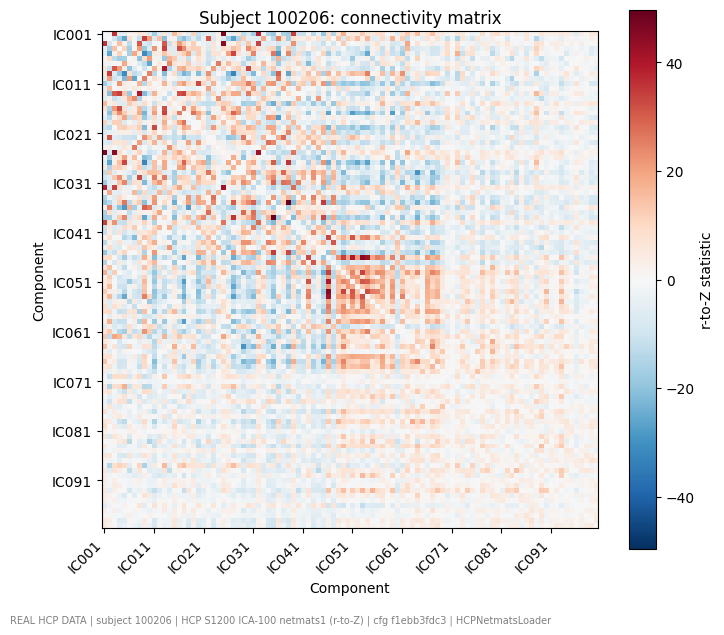

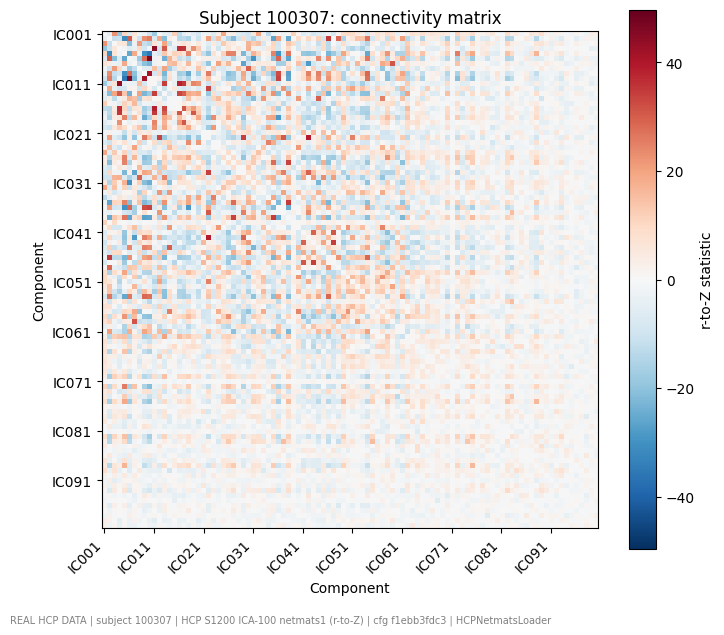

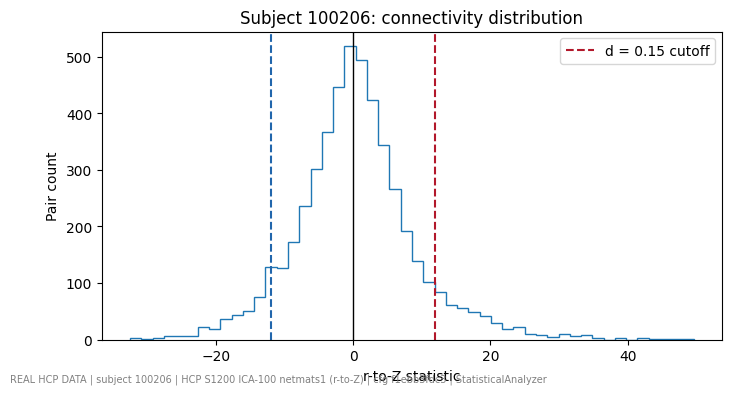

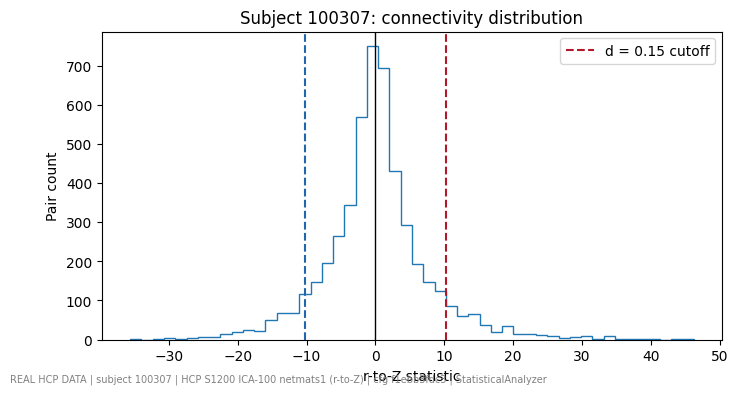

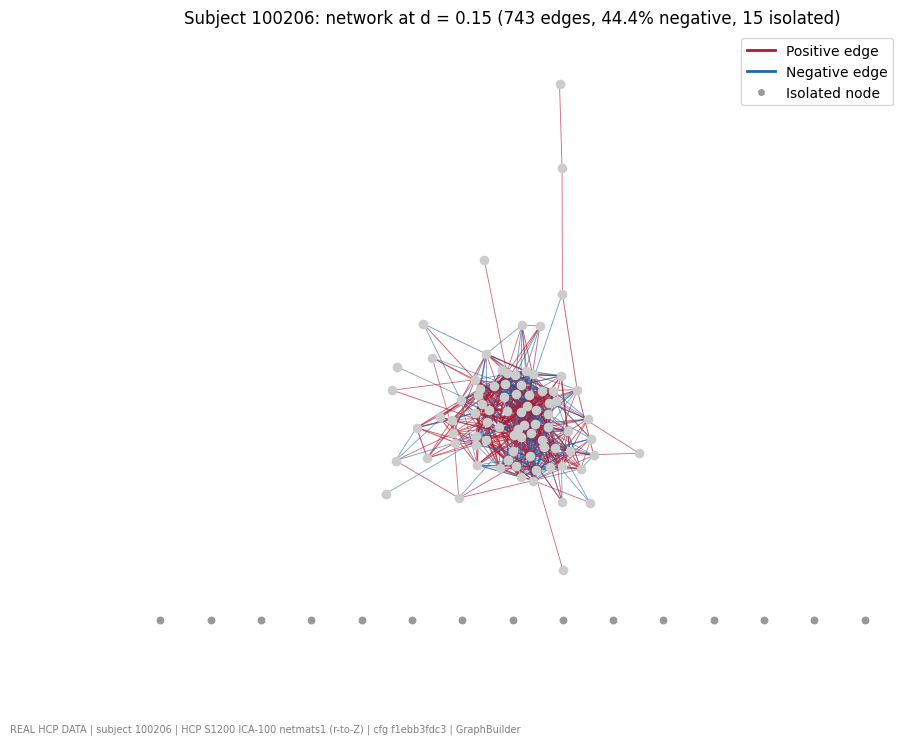

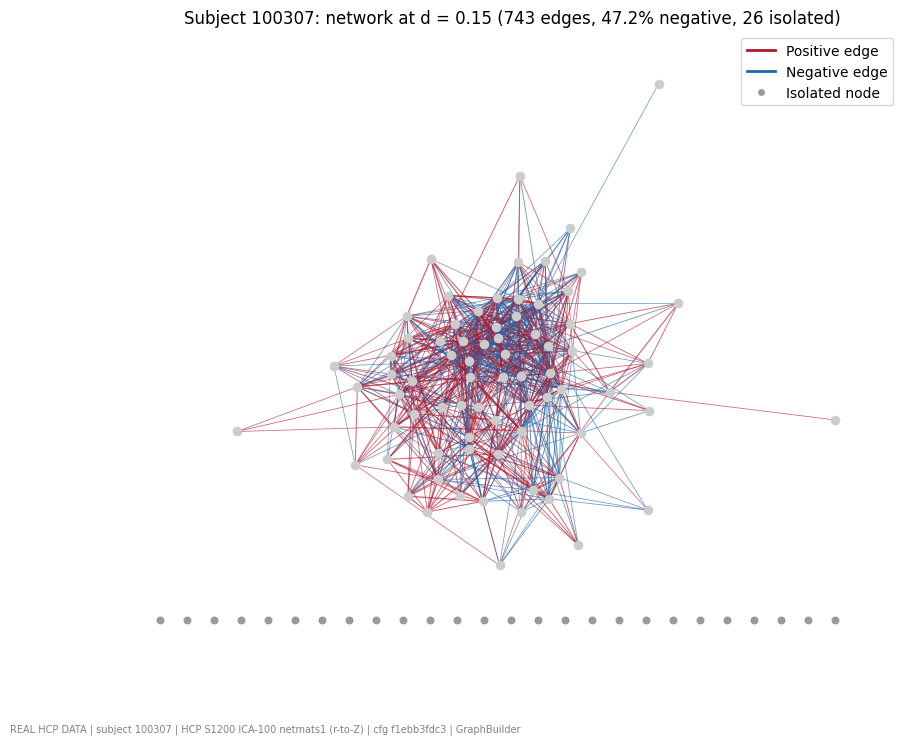

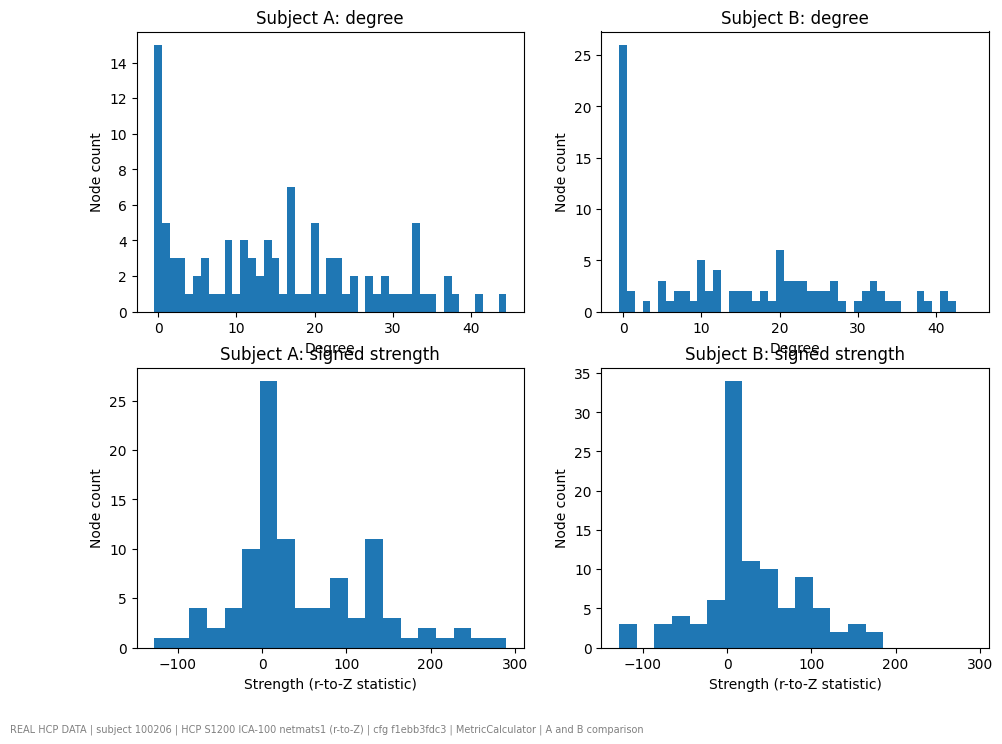

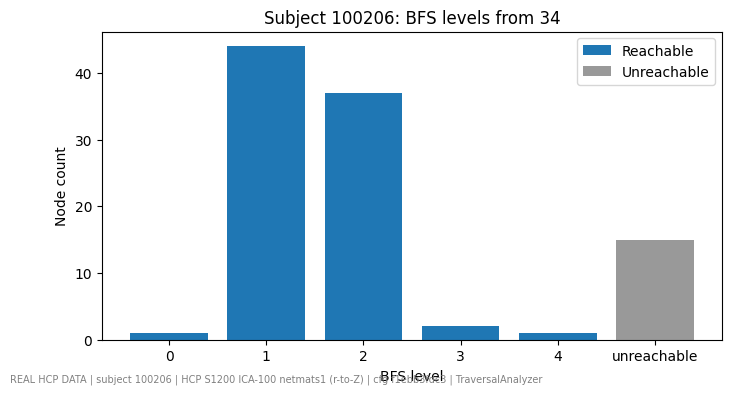

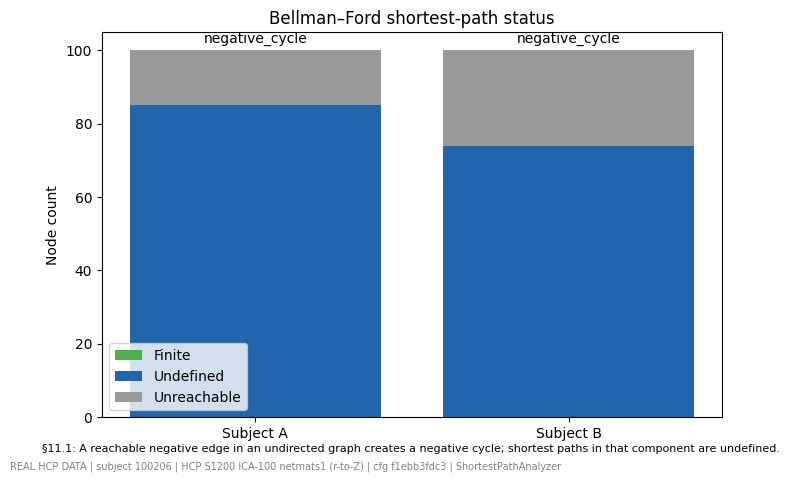

C19 figures: ['AB_degree_strength', 'AB_shortest_path_status', 'A_bfs_levels', 'A_hist', 'A_matrix', 'A_network', 'B_hist', 'B_matrix', 'B_network']
Figure count: 9
C19 ready: FIGURES, stamp, COLOR_POS, COLOR_NEG


In [25]:
# =============================================================================
# C19 | Module J part 1: Single-network figures
# Reads : C06, C09, C12-C17
# Writes: FIGURES, stamp, COLOR_POS, COLOR_NEG
# =============================================================================

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FIGURES = {}
COLOR_POS = "#b2182b"
COLOR_NEG = "#2166ac"
_COLOR_ISOLATED = "#999999"


def stamp(fig, prov, extra=""):
    """Add a provenance footer to a figure."""
    first = "TEST FIXTURE" if prov.is_fixture else "REAL HCP DATA"
    color = "red" if prov.is_fixture else "grey"
    footer = (
        f"{first} | subject {prov.subject_id} | "
        f"HCP S1200 ICA-100 netmats1 (r-to-Z) | "
        f"cfg {prov.config_hash} | {prov.algorithm}"
    )
    if extra:
        footer += " | " + extra
    fig.text(0.01, 0.005, footer, fontsize=7, color=color)


_plot_subjects = [
    ("A", data_A, proc_A, G_A, stats_A, metrics_A, trav_A, sp_A),
    ("B", data_B, proc_B, G_B, stats_B, metrics_B, trav_B, sp_B)
]
_vmax = max(
    float(np.max(np.abs(data_A.matrix_original))),
    float(np.max(np.abs(data_B.matrix_original)))
)

# A_matrix and B_matrix
for _tag, _data, _pm, _cg, _stats, _metrics, _trav, _sp in _plot_subjects:
    _fig, _ax = plt.subplots(figsize=(8, 7))
    _im = _ax.imshow(
        _data.matrix_original, cmap="RdBu_r",
        vmin=-_vmax, vmax=_vmax, interpolation="nearest"
    )
    _ticks = list(range(0, N_NODES, 10))
    _ax.set_xticks(_ticks)
    _ax.set_yticks(_ticks)
    _ax.set_xticklabels([_data.labels[i] for i in _ticks], rotation=45, ha="right")
    _ax.set_yticklabels([_data.labels[i] for i in _ticks])
    _ax.set_title(f"Subject {_data.subject_id}: connectivity matrix")
    _ax.set_xlabel("Component")
    _ax.set_ylabel("Component")
    _bar = _fig.colorbar(_im, ax=_ax)
    _bar.set_label("r-to-Z statistic")
    stamp(_fig, _data.provenance)
    FIGURES[f"{_tag}_matrix"] = _fig
    plt.show()

# A_hist and B_hist
for _tag, _data, _pm, _cg, _stats, _metrics, _trav, _sp in _plot_subjects:
    _fig, _ax = plt.subplots(figsize=(8, 4))
    _gv = _stats.global_values
    _ax.stairs(_gv["hist_counts"], _gv["hist_edges"])
    _ax.axvline(0, color="black", linewidth=1)
    _cut = _cg.G.graph["cutoff_abs_weight"]
    _ax.axvline(_cut, color=COLOR_POS, linestyle="--", label="d = 0.15 cutoff")
    _ax.axvline(-_cut, color=COLOR_NEG, linestyle="--")
    _ax.set_title(f"Subject {_data.subject_id}: connectivity distribution")
    _ax.set_xlabel("r-to-Z statistic")
    _ax.set_ylabel("Pair count")
    _ax.legend()
    stamp(_fig, _stats.provenance)
    FIGURES[f"{_tag}_hist"] = _fig
    plt.show()

# A_network and B_network
for _tag, _data, _pm, _cg, _stats, _metrics, _trav, _sp in _plot_subjects:
    _G = _cg.G
    _fig, _ax = plt.subplots(figsize=(10, 8))
    _iso_nodes = sorted(node for node in _G.nodes if _G.degree(node) == 0)
    _connected = sorted(node for node in _G.nodes if _G.degree(node) > 0)
    # Layout only the connected nodes, ignoring signed weights; isolated nodes go in a row below
    _pos = nx.spring_layout(_G.subgraph(_connected), seed=SEED, weight=None)
    _widths = []
    _colors = []
    for _u, _v, _d in _G.edges(data=True):
        _widths.append(0.2 + 1.5 * _d["abs_weight"] /
                       max(1.0, max(abs(x[2]) for x in edge_list(_cg))))
        if _d["weight"] > 0:
            _colors.append(COLOR_POS)
        else:
            _colors.append(COLOR_NEG)
    nx.draw_networkx_edges(_G, _pos, ax=_ax, edge_color=_colors,
                           width=_widths, alpha=0.65)
    nx.draw_networkx_nodes(_G, _pos, nodelist=_connected, ax=_ax,
                           node_size=35, node_color="#cccccc")
    if _iso_nodes:
        _bottom_y = min(y for _, y in _pos.values()) - 0.15
        _xs = np.linspace(-1, 1, len(_iso_nodes))    # keep isolated row inside the layout's range
        for _idx, _node in enumerate(_iso_nodes):
            _pos[_node] = (float(_xs[_idx]), _bottom_y)
        nx.draw_networkx_nodes(_G, _pos, nodelist=_iso_nodes, ax=_ax,
                               node_size=22, node_color=_COLOR_ISOLATED)
    _negative_pct = 100 * _cg.n_negative / _cg.n_edges
    _ax.set_title(
        f"Subject {_cg.subject_id}: network at d = {_cg.config.density:.2f} "
        f"({ _cg.n_edges} edges, {_negative_pct:.1f}% negative, "
        f"{_metrics.global_values['n_isolated']} isolated)"
    )
    _ax.legend(handles=[
        Line2D([0], [0], color=COLOR_POS, lw=2, label="Positive edge"),
        Line2D([0], [0], color=COLOR_NEG, lw=2, label="Negative edge"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor=_COLOR_ISOLATED,
               markersize=6, label="Isolated node")
    ])
    _ax.axis("off")
    stamp(_fig, _cg.provenance)
    FIGURES[f"{_tag}_network"] = _fig
    plt.show()

# AB_degree_strength
_fig, _axes = plt.subplots(2, 2, figsize=(11, 8))
_deg_max = max(metrics_A.node_table["degree"].max(),
               metrics_B.node_table["degree"].max())
_deg_bins = np.arange(-0.5, _deg_max + 1.5, 1)
for _ax, _metrics, _subject in [
    (_axes[0, 0], metrics_A, "A"),
    (_axes[0, 1], metrics_B, "B")
]:
    _ax.hist(_metrics.node_table["degree"], bins=_deg_bins)
    _ax.set_title(f"Subject {_subject}: degree")
    _ax.set_xlabel("Degree")
    _ax.set_ylabel("Node count")

_strength_values = list(metrics_A.node_table["strength"]) + \
                   list(metrics_B.node_table["strength"])
_strength_bins = np.histogram_bin_edges(_strength_values, bins=20)
for _ax, _metrics, _subject in [
    (_axes[1, 0], metrics_A, "A"),
    (_axes[1, 1], metrics_B, "B")
]:
    _ax.hist(_metrics.node_table["strength"], bins=_strength_bins)
    _ax.set_title(f"Subject {_subject}: signed strength")
    _ax.set_xlabel("Strength (r-to-Z statistic)")
    _ax.set_ylabel("Node count")
stamp(_fig, metrics_A.provenance, "A and B comparison")
FIGURES["AB_degree_strength"] = _fig
plt.show()

# A_bfs_levels
_fig, _ax = plt.subplots(figsize=(8, 4))
_bfs_result = trav_A["BFS"]
_level_counts = {}
for _node, _level in _bfs_result.depth.items():
    _level_counts[_level] = _level_counts.get(_level, 0) + 1
_levels = sorted(_level_counts)
_ax.bar([str(x) for x in _levels],
        [_level_counts[x] for x in _levels], label="Reachable")
_ax.bar(["unreachable"], [len(_bfs_result.unreachable)],
        color=_COLOR_ISOLATED, label="Unreachable")
_ax.set_title(f"Subject {G_A.subject_id}: BFS levels from {SOURCE_NODE}")
_ax.set_xlabel("BFS level")
_ax.set_ylabel("Node count")
_ax.legend()
stamp(_fig, _bfs_result.provenance)
FIGURES["A_bfs_levels"] = _fig
plt.show()

# AB_shortest_path_status
_fig, _ax = plt.subplots(figsize=(8, 5))
for _x, _result, _subject in [(0, sp_A, "A"), (1, sp_B, "B")]:
    _finite = sum(1 for value in _result.distances.values()
                  if value is not None and value != math.inf)
    _undefined = len(_result.undefined_nodes)
    _unreachable = len(_result.unreachable)
    _bottom = 0
    for _count, _label, _color in [
        (_finite, "Finite", "#4daf4a"),
        (_undefined, "Undefined", COLOR_NEG),
        (_unreachable, "Unreachable", _COLOR_ISOLATED)
    ]:
        _ax.bar(_x, _count, bottom=_bottom, label=_label if _x == 0 else None,
                color=_color)
        _bottom += _count
    _ax.text(_x, 102, _result.status, ha="center")
_ax.set_xticks([0, 1])
_ax.set_xticklabels(["Subject A", "Subject B"])
_ax.set_ylabel("Node count")
_ax.set_title("Bellman–Ford shortest-path status")
_ax.legend()
_fig.text(
    0.05, 0.04,
    "§11.1: A reachable negative edge in an undirected graph creates a "
    "negative cycle; shortest paths in that component are undefined.",
    fontsize=8, wrap=True
)
stamp(_fig, sp_A.provenance)
FIGURES["AB_shortest_path_status"] = _fig
plt.show()

print("C19 figures:", sorted(FIGURES))
print("Figure count:", len(FIGURES))
print("C19 ready: FIGURES, stamp, COLOR_POS, COLOR_NEG")

In [26]:
# =============================================================================
# C20 | Module H: Compatibility + pairwise comparison (Algorithm doc §12)
# Reads : C02 (CFG), C03 (ComparisonResult, make_provenance, RESULTS),
#         C08 (build_graph, edge_list), C12 (stats_A, stats_B),
#         C13 (compute_metrics), C17 (sp_A, sp_B)
# Writes: COMPARE_METRICS, check_compatibility, compare_networks, cmp_AB
# Frozen 21 Oct 2026 (decisions 10-13, 15): see plan doc.
# =============================================================================

# Global metrics compared between A and B.
# Left out on purpose: n_edges, density and mean_degree are identical for A and B
# under proportional density (delta always 0); total_weight repeats mean_strength.
COMPARE_METRICS = (
    "avg_clustering_all", "avg_clustering_lcc",
    "transitivity_all", "transitivity_lcc",
    "n_components", "largest_component_size", "n_isolated",
    "mean_strength", "mean_strength_lcc",
    "share_negative_edges", "mean_abs_weight",
)

# Metrics whose raw value depends on each subject's r-to-Z scale (decision 15)
SCALE_DEPENDENT = ("mean_strength", "mean_strength_lcc", "mean_abs_weight")


def _source_file_base(prov):
    """Source file without the '#rowN' part, so A and B can be matched."""
    return prov.source_file.split("#")[0]


def check_compatibility(proc_A, proc_B):
    """Algorithm H steps 2-5: can A and B be compared node by node?"""
    flags = []
    ok = True

    if proc_A.W.shape != (N_NODES, N_NODES) or proc_B.W.shape != (N_NODES, N_NODES):
        flags.append(f"BLOCK: shapes {proc_A.W.shape} and {proc_B.W.shape}, expected (100, 100)")
        ok = False
    if list(proc_A.labels) != list(proc_B.labels):
        flags.append("BLOCK: node labels or their order differ")
        ok = False
    if proc_A.provenance.representation != proc_B.provenance.representation:
        flags.append("BLOCK: different connectivity representations")
        ok = False
    if _source_file_base(proc_A.provenance) != _source_file_base(proc_B.provenance):
        flags.append("BLOCK: matrices come from different source files")
        ok = False

    if ok:
        for name, p in (("A", proc_A), ("B", proc_B)):
            if not np.array_equal(p.W, p.W.T):
                flags.append(f"BLOCK: matrix {name} is not symmetric")
                ok = False
            if np.any(np.diag(p.W) != 0):
                flags.append(f"BLOCK: matrix {name} has a non-zero diagonal")
                ok = False

    if proc_A.subject_id == proc_B.subject_id:
        flags.append("WARN: A and B have the same subject ID")
    if proc_A.provenance.is_fixture or proc_B.provenance.is_fixture:
        flags.append("WARN: fixture data")
    return ok, flags


def _node_diff_table(mA, mB, stats_A=None, stats_B=None):
    """100-row table of node-level A, B and A - B values."""
    tA = mA.node_table
    tB = mB.node_table
    scale_A = np.nan
    scale_B = np.nan
    if stats_A is not None and stats_B is not None:
        scale_A = stats_A.global_values["mean_abs"]
        scale_B = stats_B.global_values["mean_abs"]

    rows = []
    for i in range(len(tA)):
        a = tA.iloc[i]
        b = tB.iloc[i]
        iso_a = bool(a["isolated"])
        iso_b = bool(b["isolated"])
        change = "neither"
        if iso_a and iso_b:
            change = "both"
        elif iso_a:
            change = "A_only"
        elif iso_b:
            change = "B_only"
        rows.append({
            "node": int(a["node"]),
            "label": a["label"],
            "degree_A": int(a["degree"]),
            "degree_B": int(b["degree"]),
            "d_degree": int(a["degree"]) - int(b["degree"]),
            "strength_A": float(a["strength"]),
            "strength_B": float(b["strength"]),
            "d_strength": float(a["strength"]) - float(b["strength"]),
            "strength_norm_A": float(a["strength"]) / scale_A,
            "strength_norm_B": float(b["strength"]) / scale_B,
            "d_strength_norm": float(a["strength"]) / scale_A - float(b["strength"]) / scale_B,
            "clustering_A": float(a["clustering"]),
            "clustering_B": float(b["clustering"]),
            "d_clustering": float(a["clustering"]) - float(b["clustering"]),
            "isolated_A": iso_a,
            "isolated_B": iso_b,
            "isolation_change": change,
        })
    return pd.DataFrame(rows)


def _edge_diff_table(gA, gB, proc_A, proc_B):
    """One row per pair that is an edge in A, in B, or in both."""
    set_A = set()
    for i, j, _ in edge_list(gA):
        set_A.add((i, j))
    set_B = set()
    for i, j, _ in edge_list(gB):
        set_B.add((i, j))

    rows = []
    for (i, j) in sorted(set_A | set_B):
        in_A = (i, j) in set_A
        in_B = (i, j) in set_B
        status = "both"
        if in_A and not in_B:
            status = "A_only"
        if in_B and not in_A:
            status = "B_only"
        w_A = float(proc_A.W[i, j])
        w_B = float(proc_B.W[i, j])
        sign_A = int(np.sign(w_A))
        sign_B = int(np.sign(w_B))
        rows.append({
            "i": i, "j": j,
            "label_i": proc_A.labels[i], "label_j": proc_A.labels[j],
            "in_A": in_A, "in_B": in_B, "status": status,
            "w_A": w_A, "w_B": w_B, "d_w": w_A - w_B,
            "sign_A": sign_A, "sign_B": sign_B,
            "sign_flip": bool(in_A and in_B and sign_A != sign_B),
        })
    return pd.DataFrame(rows)


def compare_networks(proc_A, proc_B, cfg=CFG, stats_A=None, stats_B=None,
                     sp_A=None, sp_B=None):
    """Algorithm H: compare A and B built with the SAME settings."""
    # 1. Compatibility first: no number is computed before this passes
    ok, flags = check_compatibility(proc_A, proc_B)
    if not ok:
        blocks = [f for f in flags if f.startswith("BLOCK")]
        raise ValueError("Networks are not compatible: " + "; ".join(blocks))

    # 2. Matched graphs: one cfg for both
    cfg.validate()
    gA = build_graph(proc_A, cfg)
    gB = build_graph(proc_B, cfg)
    if gA.config.hash() != gB.config.hash():
        raise AssertionError("A and B were built with different settings")

    # 3. Metrics
    mA = compute_metrics(gA)
    mB = compute_metrics(gB)

    # 4. Global differences: dM = M(A) - M(B)
    global_diff = {}
    for k in COMPARE_METRICS:
        global_diff[k] = float(mA.global_values[k]) - float(mB.global_values[k])

    # 5-6. Node and edge differences
    node_diff = _node_diff_table(mA, mB, stats_A, stats_B)
    edge_diff = _edge_diff_table(gA, gB, proc_A, proc_B)

    # 7. Edge summary
    n_both = int((edge_diff["status"] == "both").sum())
    n_A_only = int((edge_diff["status"] == "A_only").sum())
    n_B_only = int((edge_diff["status"] == "B_only").sum())
    edge_summary = {
        "n_both": n_both,
        "n_A_only": n_A_only,
        "n_B_only": n_B_only,
        "n_sign_flips": int(edge_diff["sign_flip"].sum()),
        "jaccard": n_both / (n_both + n_A_only + n_B_only),
    }

    # 8. Shortest-path differences only when both are defined (§12 step 12)
    path_diff = None
    both_ok = (sp_A is not None and sp_B is not None
               and sp_A.status == "ok" and sp_B.status == "ok")
    if both_ok:
        path_diff = {}
        for n in sp_A.distances:
            dA = sp_A.distances[n]
            dB = sp_B.distances.get(n)
            if dA is not None and dB is not None and dA != math.inf and dB != math.inf:
                path_diff[n] = dA - dB
    else:
        flags.append("Shortest-path comparison undefined: reachable negative cycle (§11.1)")

    if stats_A is None or stats_B is None:
        flags.append("WARN: no statistics given; normalised strength is NaN")

    is_fix = proc_A.provenance.is_fixture or proc_B.provenance.is_fixture
    prov = make_provenance(f"{proc_A.subject_id}_vs_{proc_B.subject_id}",
                           "NetworkComparator", cfg,
                           source_file=_source_file_base(proc_A.provenance),
                           is_fixture=is_fix)
    return ComparisonResult(proc_A.subject_id, proc_B.subject_id, True, flags,
                            cfg.density, global_diff, node_diff, edge_diff,
                            path_diff, prov, edge_summary=edge_summary)


# ---- Run on the real pair at the base density ---------------------------------
cmp_AB = compare_networks(proc_A, proc_B, CFG, stats_A, stats_B, sp_A, sp_B)
RESULTS.add("comparison", cmp_AB)

print(f"C20 | Pairwise comparison {cmp_AB.id_A} (A) vs {cmp_AB.id_B} (B) at d = {cmp_AB.density}")
print("Flags:")
for f in cmp_AB.flags:
    print("  -", f)

print(f"\n{'Metric':24s} | {'A':>10s} | {'B':>10s} | {'A - B':>10s}")
_gA = compute_metrics(build_graph(proc_A, CFG)).global_values
_gB = compute_metrics(build_graph(proc_B, CFG)).global_values
for k in COMPARE_METRICS:
    note = ""
    if k in SCALE_DEPENDENT:
        note = "  (scale-dependent)"
    print(f"{k:24s} | {_gA[k]:10.4f} | {_gB[k]:10.4f} | {cmp_AB.global_diff[k]:10.4f}{note}")

print("\nEdge summary:", cmp_AB.edge_summary)
print("\nTop 10 nodes by |d_degree|:")
_nd = cmp_AB.node_diff.copy()
_nd["abs_d_degree"] = _nd["d_degree"].abs()
print(_nd.sort_values(["abs_d_degree", "node"], ascending=[False, True])
      .head(10)[["node", "label", "degree_A", "degree_B", "d_degree", "d_strength_norm"]]
      .to_string(index=False))
print("\nIsolation change counts:", cmp_AB.node_diff["isolation_change"].value_counts().to_dict())
print("C20 ready: COMPARE_METRICS, check_compatibility, compare_networks, cmp_AB")

C20 | Pairwise comparison 100206 (A) vs 100307 (B) at d = 0.15
Flags:
  - Shortest-path comparison undefined: reachable negative cycle (§11.1)

Metric                   |          A |          B |      A - B
avg_clustering_all       |     0.4394 |     0.4044 |     0.0349
avg_clustering_lcc       |     0.5169 |     0.5465 |    -0.0297
transitivity_all         |     0.5163 |     0.5230 |    -0.0067
transitivity_lcc         |     0.5163 |     0.5230 |    -0.0067
n_components             |    16.0000 |    27.0000 |   -11.0000
largest_component_size   |    85.0000 |    74.0000 |    11.0000
n_isolated               |    15.0000 |    26.0000 |   -11.0000
mean_strength            |    47.8913 |    27.3355 |    20.5558  (scale-dependent)
mean_strength_lcc        |    56.3427 |    36.9398 |    19.4029  (scale-dependent)
share_negative_edges     |     0.4441 |     0.4724 |    -0.0283
mean_abs_weight          |    17.7750 |    16.0266 |     1.7484  (scale-dependent)

Edge summary: {'n_both': 355, 

In [27]:
# =============================================================================
# C21 | Module I: Multi-setting global-to-local analysis (Algorithm doc §13)
# Reads : C02 (CFG, DENSITY_SETTINGS, EPS_ZERO), C03 (MultiSettingResult, make_provenance),
#         C08 (build_graph, edge_list), C13 (compute_metrics),
#         C20 (COMPARE_METRICS, SCALE_DEPENDENT, check_compatibility, _source_file_base)
# Writes: CONSISTENCY_RULE, G2L_MAP, G2L_DIRECTION, classify_metric, run_multi_setting
# Note  : definitions only. The real run is C22.
# Frozen 21 Oct 2026: strict rule, eps = 1e-9, top 10 nodes / top 20 edges.
# v2 (21 Oct 2026): sign_agreement now uses G2L_DIRECTION (bug fix; rule unchanged).
# =============================================================================

CONSISTENCY_RULE = (
    "setting-consistent iff all K deltas share one sign beyond eps "
    "(S_M = 1 and n_zero = 0); no difference iff all |delta| <= eps; "
    "otherwise construction-sensitive. Descriptive only, not a significance test."
)

N_TOP_NODES = 10
N_TOP_EDGES = 20

# Decision 13: which local (node-level) measure explains each global metric
G2L_MAP = {
    "avg_clustering_all": "d_clustering",
    "avg_clustering_lcc": "d_clustering",
    "transitivity_all": "d_clustering",
    "transitivity_lcc": "d_clustering",
    "n_components": "d_degree",
    "largest_component_size": "d_degree",
    "n_isolated": "d_degree",
    "mean_strength": "d_strength_norm",
    "mean_strength_lcc": "d_strength_norm",
    "share_negative_edges": "d_degree",
    "mean_abs_weight": "d_strength_norm",
}

# Expected direction linking the local measure to the global metric:
# +1 = a node with a higher local value in A pushes the metric up in A;
# -1 = it pushes the metric down (more degree -> fewer components / isolated nodes).
# Used only for sign_agreement; it does not change rankings or the consistency rule.
G2L_DIRECTION = {
    "avg_clustering_all": 1, "avg_clustering_lcc": 1,
    "transitivity_all": 1, "transitivity_lcc": 1,
    "n_components": -1, "largest_component_size": 1, "n_isolated": -1,
    "mean_strength": 1, "mean_strength_lcc": 1,
    "share_negative_edges": 1, "mean_abs_weight": 1,
}


def classify_metric(deltas, eps=EPS_ZERO):
    """Apply the frozen consistency rule to one metric's deltas across settings."""
    n_pos = 0
    n_neg = 0
    for x in deltas:
        if x > eps:
            n_pos += 1
        elif x < -eps:
            n_neg += 1
    n_zero = len(deltas) - n_pos - n_neg

    if n_pos + n_neg == 0:
        return {"n_pos": 0, "n_neg": 0, "n_zero": n_zero, "S_M": np.nan,
                "label": "no difference", "direction": "none"}

    s_m = max(n_pos, n_neg) / (n_pos + n_neg)

    direction = "mixed"
    if n_pos > n_neg:
        direction = "A > B"
    elif n_neg > n_pos:
        direction = "A < B"

    label = "construction-sensitive"
    if s_m == 1.0 and n_zero == 0:
        label = "setting-consistent"

    return {"n_pos": n_pos, "n_neg": n_neg, "n_zero": n_zero, "S_M": s_m,
            "label": label, "direction": direction}


def _sign(x, eps):
    """+1, -1 or 0 using the same tolerance as the rule."""
    if x > eps:
        return 1
    if x < -eps:
        return -1
    return 0


def run_multi_setting(proc_A, proc_B, cfg=CFG, settings=DENSITY_SETTINGS,
                      metrics=None, eps=EPS_ZERO, stats_A=None, stats_B=None):
    """Algorithm I: matched A/B graphs at every setting -> profiles, rule, global-to-local."""
    if metrics is None:
        metrics = COMPARE_METRICS
    metrics = tuple(metrics)

    # Preconditions (§13.1)
    ok, flags = check_compatibility(proc_A, proc_B)
    if not ok:
        blocks = [f for f in flags if f.startswith("BLOCK")]
        raise ValueError("Networks are not compatible: " + "; ".join(blocks))
    settings = tuple(sorted(set(float(d) for d in settings)))
    for d in settings:
        cfg.with_density(d).validate()

    scale_A = np.nan
    scale_B = np.nan
    if stats_A is not None and stats_B is not None:
        scale_A = stats_A.global_values["mean_abs"]
        scale_B = stats_B.global_values["mean_abs"]

    K = len(settings)
    count_A = np.zeros((N_NODES, N_NODES), dtype=int)
    count_B = np.zeros((N_NODES, N_NODES), dtype=int)
    value_rows = []
    profile_rows = []
    node_rows = []

    # Steps 2-8: identical setting for A and B at every density
    for d in settings:
        c = cfg.with_density(d)
        gA = build_graph(proc_A, c)
        gB = build_graph(proc_B, c)
        if gA.config.hash() != gB.config.hash():
            raise AssertionError(f"A and B built with different settings at d = {d}")
        mA = compute_metrics(gA)
        mB = compute_metrics(gB)

        vrow = {"density": d, "config_hash": c.hash()}
        prow = {"density": d, "config_hash": c.hash()}
        for k in metrics:
            a = float(mA.global_values[k])
            b = float(mB.global_values[k])
            vrow[f"{k}_A"] = a
            vrow[f"{k}_B"] = b
            prow[k] = a - b
        value_rows.append(vrow)
        profile_rows.append(prow)

        tA = mA.node_table
        tB = mB.node_table
        for i in range(N_NODES):
            a = tA.iloc[i]
            b = tB.iloc[i]
            node_rows.append({
                "density": d, "node": i, "label": proc_A.labels[i],
                "degree_A": int(a["degree"]), "degree_B": int(b["degree"]),
                "d_degree": int(a["degree"]) - int(b["degree"]),
                "strength_A": float(a["strength"]), "strength_B": float(b["strength"]),
                "d_strength": float(a["strength"]) - float(b["strength"]),
                "d_strength_norm": float(a["strength"]) / scale_A - float(b["strength"]) / scale_B,
                "clustering_A": float(a["clustering"]), "clustering_B": float(b["clustering"]),
                "d_clustering": float(a["clustering"]) - float(b["clustering"]),
                "isolated_A": bool(a["isolated"]), "isolated_B": bool(b["isolated"]),
            })

        for i, j, _ in edge_list(gA):
            count_A[i, j] += 1
        for i, j, _ in edge_list(gB):
            count_B[i, j] += 1

    values = pd.DataFrame(value_rows)
    profile = pd.DataFrame(profile_rows)
    node_profile = pd.DataFrame(node_rows)

    # Steps 9-10: edge retention P_A(e), P_B(e), dP(e) over all 4950 pairs
    ret_rows = []
    rows_i, cols_j = np.triu_indices(N_NODES, k=1)
    for i, j in zip(rows_i, cols_j):
        i = int(i)
        j = int(j)
        w_A = float(proc_A.W[i, j])
        w_B = float(proc_B.W[i, j])
        ret_rows.append({
            "i": i, "j": j, "label_i": proc_A.labels[i], "label_j": proc_A.labels[j],
            "count_A": int(count_A[i, j]), "count_B": int(count_B[i, j]),
            "P_A": count_A[i, j] / K, "P_B": count_B[i, j] / K,
            "dP": (count_A[i, j] - count_B[i, j]) / K,
            "w_A": w_A, "w_B": w_B,
            "sign_A": int(np.sign(w_A)), "sign_B": int(np.sign(w_B)),
        })
    retention = pd.DataFrame(ret_rows)

    # Steps 11-12: consistency classification per metric
    cons_rows = []
    for k in metrics:
        res = classify_metric(list(profile[k]), eps)
        res["metric"] = k
        res["scale_dependent"] = k in SCALE_DEPENDENT
        cons_rows.append(res)
    consistency = pd.DataFrame(cons_rows)[
        ["metric", "n_pos", "n_neg", "n_zero", "S_M", "label", "direction", "scale_dependent"]]

    # Steps 13-14: global-to-local summary (descriptive context, not causes)
    g2l_rows = []
    for k in metrics:
        local = G2L_MAP[k]
        label = consistency.loc[consistency["metric"] == k, "label"].iloc[0]
        delta_by_d = {}
        for _, prow in profile.iterrows():
            delta_by_d[prow["density"]] = prow[k]

        node_stats = []
        for node in range(N_NODES):
            sub = node_profile[node_profile["node"] == node]
            vals = list(sub[local])
            agree = 0
            counted = 0
            for _, r in sub.iterrows():
                s_global = _sign(delta_by_d[r["density"]], eps) * G2L_DIRECTION[k]
                s_local = _sign(r[local], eps)
                if s_global != 0:
                    counted += 1
                    if s_local == s_global:
                        agree += 1
            sign_agreement = np.nan
            if counted > 0:
                sign_agreement = agree / counted
            node_stats.append((float(np.mean(np.abs(vals))), node, float(np.mean(vals)),
                               sign_agreement))
        node_stats.sort(key=lambda t: (-t[0], t[1]))
        for rank in range(N_TOP_NODES):
            mad, node, md, sa = node_stats[rank]
            g2l_rows.append({
                "metric": k, "label": label, "level": "node", "local_measure": local,
                "rank": rank + 1, "node": node, "node_label": proc_A.labels[node],
                "i": np.nan, "j": np.nan, "edge_labels": "",
                "mean_abs_delta": mad, "mean_delta": md, "sign_agreement": sa, "dP": np.nan,
            })

        edge_pool = retention
        if k == "share_negative_edges":
            edge_pool = retention[(retention["sign_A"] < 0) | (retention["sign_B"] < 0)]
        if local != "d_clustering":
            top = edge_pool.assign(abs_dP=edge_pool["dP"].abs())
            top = top.sort_values(["abs_dP", "i", "j"], ascending=[False, True, True]).head(N_TOP_EDGES)
            rank = 0
            for _, e in top.iterrows():
                rank += 1
                g2l_rows.append({
                    "metric": k, "label": label, "level": "edge", "local_measure": "dP",
                    "rank": rank, "node": np.nan, "node_label": "",
                    "i": int(e["i"]), "j": int(e["j"]),
                    "edge_labels": f"{e['label_i']}-{e['label_j']}",
                    "mean_abs_delta": abs(e["dP"]), "mean_delta": e["dP"],
                    "sign_agreement": np.nan, "dP": e["dP"],
                })
    g2l_summary = pd.DataFrame(g2l_rows)

    is_fix = proc_A.provenance.is_fixture or proc_B.provenance.is_fixture
    prov = make_provenance(f"{proc_A.subject_id}_vs_{proc_B.subject_id}",
                           "MultiSettingAnalyzer", cfg,
                           source_file=_source_file_base(proc_A.provenance),
                           is_fixture=is_fix)
    return MultiSettingResult(settings, metrics, eps, profile, consistency, node_profile,
                              retention, g2l_summary, CONSISTENCY_RULE, prov, values=values)


print("C21 ready: CONSISTENCY_RULE, G2L_MAP, G2L_DIRECTION, classify_metric, run_multi_setting")
print("Rule:", CONSISTENCY_RULE)

C21 ready: CONSISTENCY_RULE, G2L_MAP, G2L_DIRECTION, classify_metric, run_multi_setting
Rule: setting-consistent iff all K deltas share one sign beyond eps (S_M = 1 and n_zero = 0); no difference iff all |delta| <= eps; otherwise construction-sensitive. Descriptive only, not a significance test.


In [28]:
# =============================================================================
# C22 | Module I run: multi-setting analysis on the real pair
# Reads : C02 (CFG, DENSITY_SETTINGS, EPS_ZERO), C09 (proc_A, proc_B),
#         C12 (stats_A, stats_B), C20 (COMPARE_METRICS), C21 (run_multi_setting)
# Writes: ms_AB
# =============================================================================

# 1. Record the frozen settings BEFORE any result is computed
print("C22 | Frozen settings (decided 21 Oct 2026, before this run)")
print("   densities D       :", DENSITY_SETTINGS, f"(K = {len(DENSITY_SETTINGS)})")
print("   edges per density :", [n_edges_for_density(d, 4950) for d in DENSITY_SETTINGS])
print("   eps (near-zero)   :", EPS_ZERO)
print("   metrics           :", len(COMPARE_METRICS), "->", ", ".join(COMPARE_METRICS))
print("   rule              :", CONSISTENCY_RULE)
print("   global-to-local   : top", N_TOP_NODES, "nodes, top", N_TOP_EDGES, "edges")
print("   run at (UTC)      :", datetime.now(timezone.utc).isoformat(timespec="seconds"))

# 2. Run
ms_AB = run_multi_setting(proc_A, proc_B, CFG, DENSITY_SETTINGS, COMPARE_METRICS,
                          EPS_ZERO, stats_A, stats_B)
RESULTS.add("multi_setting", ms_AB)

# 3. Structural checks (not results)
_K = len(ms_AB.settings)
_expected_P = sum(n_edges_for_density(d, 4950) for d in ms_AB.settings) / _K
print("\nStructure")
print("   profile rows      :", len(ms_AB.profile), "(expected", _K, ")")
print("   node_profile rows :", len(ms_AB.node_profile), "(expected", _K * N_NODES, ")")
print("   retention rows    :", len(ms_AB.retention), "(expected 4950)")
print("   sum P_A, sum P_B  :", round(ms_AB.retention["P_A"].sum(), 6),
      round(ms_AB.retention["P_B"].sum(), 6), "(expected", _expected_P, ")")
print("   distinct settings :", ms_AB.profile["config_hash"].nunique(), "config hashes")

# 4. Results
pd.set_option("display.width", 160)
print("\nConsistency of A - B across densities")
print(ms_AB.consistency.to_string(index=False))

print("\nA - B at each density (profile)")
print(ms_AB.profile.drop(columns=["config_hash"]).round(4).to_string(index=False))

_consistent = list(ms_AB.consistency.loc[
    ms_AB.consistency["label"] == "setting-consistent", "metric"])
print("\nSetting-consistent metrics:", _consistent)
for _m in _consistent:
    _rows = ms_AB.g2l_summary[(ms_AB.g2l_summary["metric"] == _m) &
                              (ms_AB.g2l_summary["level"] == "node")].head(5)
    print(f"\n  {_m}: top 5 nodes by mean |{G2L_MAP[_m]}|")
    print(_rows[["rank", "node_label", "mean_delta", "mean_abs_delta", "sign_agreement"]]
          .round(3).to_string(index=False))

print("\nC22 ready: ms_AB")

C22 | Frozen settings (decided 21 Oct 2026, before this run)
   densities D       : (0.05, 0.1, 0.15, 0.2, 0.25, 0.3) (K = 6)
   edges per density : [248, 495, 743, 990, 1238, 1485]
   eps (near-zero)   : 1e-09
   metrics           : 11 -> avg_clustering_all, avg_clustering_lcc, transitivity_all, transitivity_lcc, n_components, largest_component_size, n_isolated, mean_strength, mean_strength_lcc, share_negative_edges, mean_abs_weight
   rule              : setting-consistent iff all K deltas share one sign beyond eps (S_M = 1 and n_zero = 0); no difference iff all |delta| <= eps; otherwise construction-sensitive. Descriptive only, not a significance test.
   global-to-local   : top 10 nodes, top 20 edges
   run at (UTC)      : 2026-10-21T17:12:43+00:00

Structure
   profile rows      : 6 (expected 6 )
   node_profile rows : 600 (expected 600 )
   retention rows    : 4950 (expected 4950)
   sum P_A, sum P_B  : 866.5 866.5 (expected 866.5 )
   distinct settings : 6 config hashes

Consist

In [29]:
# =============================================================================
# C22S | Post-hoc scale check for the 3 scale-dependent metrics
# Reads : C12 (stats_A, stats_B), C21 (classify_metric), C22 (ms_AB), C02 (EPS_ZERO)
# Writes: scale_check, scale_check_labels
# POST-HOC (added 21 Oct 2026, AFTER the frozen C22 run). It does not change any
# frozen rule, label or result. It only asks: does each scale-dependent difference
# survive when every weight is divided by that subject's own mean|w| (all 4950 pairs)?
# =============================================================================

_SCALED = ("mean_strength", "mean_strength_lcc", "mean_abs_weight")
_scale_A = stats_A.global_values["mean_abs"]
_scale_B = stats_B.global_values["mean_abs"]

_rows = []
for _, _v in ms_AB.values.iterrows():
    _row = {"density": _v["density"]}
    for _k in _SCALED:
        _a = _v[f"{_k}_A"] / _scale_A
        _b = _v[f"{_k}_B"] / _scale_B
        _row[f"{_k}_norm_A"] = _a
        _row[f"{_k}_norm_B"] = _b
        _row[f"{_k}_norm_delta"] = _a - _b
    _rows.append(_row)
scale_check = pd.DataFrame(_rows)

_lab_rows = []
for _k in _SCALED:
    _raw = ms_AB.consistency.loc[ms_AB.consistency["metric"] == _k].iloc[0]
    _res = classify_metric(list(scale_check[f"{_k}_norm_delta"]), EPS_ZERO)
    _lab_rows.append({"metric": _k, "raw_label": _raw["label"], "raw_direction": _raw["direction"],
                      "normalised_label": _res["label"], "normalised_direction": _res["direction"],
                      "n_pos": _res["n_pos"], "n_neg": _res["n_neg"]})
scale_check_labels = pd.DataFrame(_lab_rows)

print("C22S | POST-HOC scale check (not part of the frozen analysis)")
print(f"   per-subject scale mean|w| : A = {_scale_A:.4f}, B = {_scale_B:.4f} "
      f"(ratio A/B = {_scale_A / _scale_B:.3f})")
print("\nNormalised values (metric / own mean|w|) and A - B at each density")
_cols = ["density"]
for _k in _SCALED:
    _cols += [f"{_k}_norm_A", f"{_k}_norm_B", f"{_k}_norm_delta"]
print(scale_check[_cols].round(4).to_string(index=False))
print("\nDoes the raw label survive normalisation?")
print(scale_check_labels.to_string(index=False))
print("\nC22S ready: scale_check, scale_check_labels")

C22S | POST-HOC scale check (not part of the frozen analysis)
   per-subject scale mean|w| : A = 6.3631, B = 5.2530 (ratio A/B = 1.211)

Normalised values (metric / own mean|w|) and A - B at each density
 density  mean_strength_norm_A  mean_strength_norm_B  mean_strength_norm_delta  mean_strength_lcc_norm_A  mean_strength_lcc_norm_B  mean_strength_lcc_norm_delta  mean_abs_weight_norm_A  mean_abs_weight_norm_B  mean_abs_weight_norm_delta
    0.05                7.6792                5.5622                    2.1170                   11.9082                    9.2704                        2.6377                  3.7607                  4.2830                     -0.5223
    0.10                8.3497                5.4620                    2.8877                   10.9865                    7.8028                        3.1836                  3.1654                  3.5018                     -0.3364
    0.15                7.5264                5.2038                    2.3226       

In [30]:
# =============================================================================
# C22R | Revised protocol v2: scale-free metrics + minimum-size tolerance
# Reads : C02 (DENSITY_SETTINGS, EPS_ZERO), C12 (stats_A, stats_B), C20 (COMPARE_METRICS,
#         SCALE_DEPENDENT), C22 (ms_AB)
# Writes: REL_TOL, COMPARE_METRICS_V2, CONSISTENCY_RULE_V2, classify_metric_v2, protocol_v2,
#         protocol_v2_table, consistency_v2
# Why   : two problems found in the frozen v1 run (C22):
#         1. raw strength / weight metrics depend on each subject's r-to-Z scale (C22S showed
#            mean_abs_weight reverses once that scale is removed);
#         2. the v1 rule counts any difference above 1e-9 as real, so a gap of 0.0008 counts
#            the same as a gap of 0.09.
# Status: v2 was written on 21 Oct 2026 AFTER seeing the main pair (so for the main pair it is
#         a revision, reported next to v1, not instead of it). It is fixed BEFORE C28 runs, so
#         the 4 replication pairs are a clean test of v2. v1 (C21/C22) is left unchanged.
#         The v1 columns show the frozen label of the raw metric.
# =============================================================================

REL_TOL = 0.01   # a per-density difference counts only if |A - B| > 1% of the mean of |A| and |B|

# v2 metric set: the 8 scale-free metrics unchanged, the 3 scale-dependent ones replaced
# by the same metric divided by that subject's own mean|w| over all 4950 pairs.
COMPARE_METRICS_V2 = []
for _k in COMPARE_METRICS:
    if _k in SCALE_DEPENDENT:
        COMPARE_METRICS_V2.append(_k + "_norm")
    else:
        COMPARE_METRICS_V2.append(_k)
COMPARE_METRICS_V2 = tuple(COMPARE_METRICS_V2)

CONSISTENCY_RULE_V2 = (
    "v2: a density counts as a difference only if |A - B| > max(eps, REL_TOL x mean(|A|, |B|)), "
    "REL_TOL = 0.01; strength/weight metrics divided by each subject's mean|w|. "
    "setting-consistent = same sign at all K densities; partially consistent = one sign only, "
    "but negligible at some densities; construction-sensitive = both signs appear; "
    "no difference = negligible at all densities. Descriptive only, not a significance test."
)


def classify_metric_v2(values_a, values_b, eps=EPS_ZERO, rel_tol=REL_TOL):
    """v2 rule for one metric, given its A and B values at each density."""
    n_pos = 0
    n_neg = 0
    for a, b in zip(values_a, values_b):
        tol = max(eps, rel_tol * (abs(a) + abs(b)) / 2)
        if a - b > tol:
            n_pos += 1
        elif a - b < -tol:
            n_neg += 1
    n_small = len(values_a) - n_pos - n_neg

    if n_pos + n_neg == 0:
        return {"n_pos": 0, "n_neg": 0, "n_small": n_small, "label": "no difference",
                "direction": "none"}
    direction = "mixed"
    if n_pos > n_neg:
        direction = "A > B"
    elif n_neg > n_pos:
        direction = "A < B"
    if n_pos > 0 and n_neg > 0:
        label = "construction-sensitive"
    elif n_small == 0:
        label = "setting-consistent"
    else:
        label = "partially consistent"
    return {"n_pos": n_pos, "n_neg": n_neg, "n_small": n_small, "label": label,
            "direction": direction}


def protocol_v2(ms, st_a, st_b):
    """Apply v2 to a finished multi-setting result. Returns (values table, consistency table)."""
    sa = st_a.global_values["mean_abs"]
    sb = st_b.global_values["mean_abs"]
    vals = pd.DataFrame({"density": ms.values["density"]})
    for k in COMPARE_METRICS_V2:
        base = k
        scale_a = 1.0
        scale_b = 1.0
        if k.endswith("_norm"):
            base = k[:-len("_norm")]
            scale_a = sa
            scale_b = sb
        vals[f"{k}_A"] = ms.values[f"{base}_A"] / scale_a
        vals[f"{k}_B"] = ms.values[f"{base}_B"] / scale_b
    rows = []
    for k in COMPARE_METRICS_V2:
        res = classify_metric_v2(list(vals[f"{k}_A"]), list(vals[f"{k}_B"]))
        base = k
        if k.endswith("_norm"):
            base = k[:-len("_norm")]
        v1 = ms.consistency.loc[ms.consistency["metric"] == base].iloc[0]
        res["metric"] = k
        res["v1_label"] = v1["label"]
        res["v1_direction"] = v1["direction"]
        rows.append(res)
    cons = pd.DataFrame(rows)[["metric", "v1_label", "v1_direction", "label", "direction",
                               "n_pos", "n_neg", "n_small"]]
    return vals, cons


# ---- Self-checks of the v2 rule (hand cases) -----------------------------------
_c = classify_metric_v2([1.0, 1.0, 1.0], [0.5, 0.5, 0.5])
assert _c["label"] == "setting-consistent" and _c["direction"] == "A > B"
_c = classify_metric_v2([1.0, 1.0, 1.0], [0.5, 0.999, 0.5])        # middle gap 0.1% -> negligible
assert _c["label"] == "partially consistent" and _c["n_small"] == 1
_c = classify_metric_v2([1.0, 0.5, 1.0], [0.5, 1.0, 0.5])
assert _c["label"] == "construction-sensitive"
_c = classify_metric_v2([1.0, 1.0], [1.001, 0.9995])
assert _c["label"] == "no difference"
_c = classify_metric_v2([5.0, 5.0], [5.0 + 1e-12, 5.0])
assert _c["label"] == "no difference"
print("C22R | v2 rule self-checks: 5 passed")

# ---- Main pair under v2 -------------------------------------------------------
protocol_v2_table, consistency_v2 = protocol_v2(ms_AB, stats_A, stats_B)
print("Rule:", CONSISTENCY_RULE_V2)
print("\nMain pair: v1 (frozen, C22) vs v2 (revised)")
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(consistency_v2.to_string(index=False))
_changed = consistency_v2[(consistency_v2["v1_label"] != consistency_v2["label"]) |
                          (consistency_v2["v1_direction"] != consistency_v2["direction"])]
print(f"\nMetrics whose label or direction changed under v2: {list(_changed['metric'])}")
print("C22R ready: REL_TOL, COMPARE_METRICS_V2, CONSISTENCY_RULE_V2, classify_metric_v2, "
      "protocol_v2, protocol_v2_table, consistency_v2")

C22R | v2 rule self-checks: 5 passed
Rule: v2: a density counts as a difference only if |A - B| > max(eps, REL_TOL x mean(|A|, |B|)), REL_TOL = 0.01; strength/weight metrics divided by each subject's mean|w|. setting-consistent = same sign at all K densities; partially consistent = one sign only, but negligible at some densities; construction-sensitive = both signs appear; no difference = negligible at all densities. Descriptive only, not a significance test.

Main pair: v1 (frozen, C22) vs v2 (revised)
                metric               v1_label v1_direction                  label direction  n_pos  n_neg  n_small
    avg_clustering_all construction-sensitive        A > B   partially consistent     A > B      5      0        1
    avg_clustering_lcc construction-sensitive        A < B construction-sensitive     A < B      1      4        1
      transitivity_all     setting-consistent        A < B   partially consistent     A < B      0      5        1
      transitivity_lcc     sett

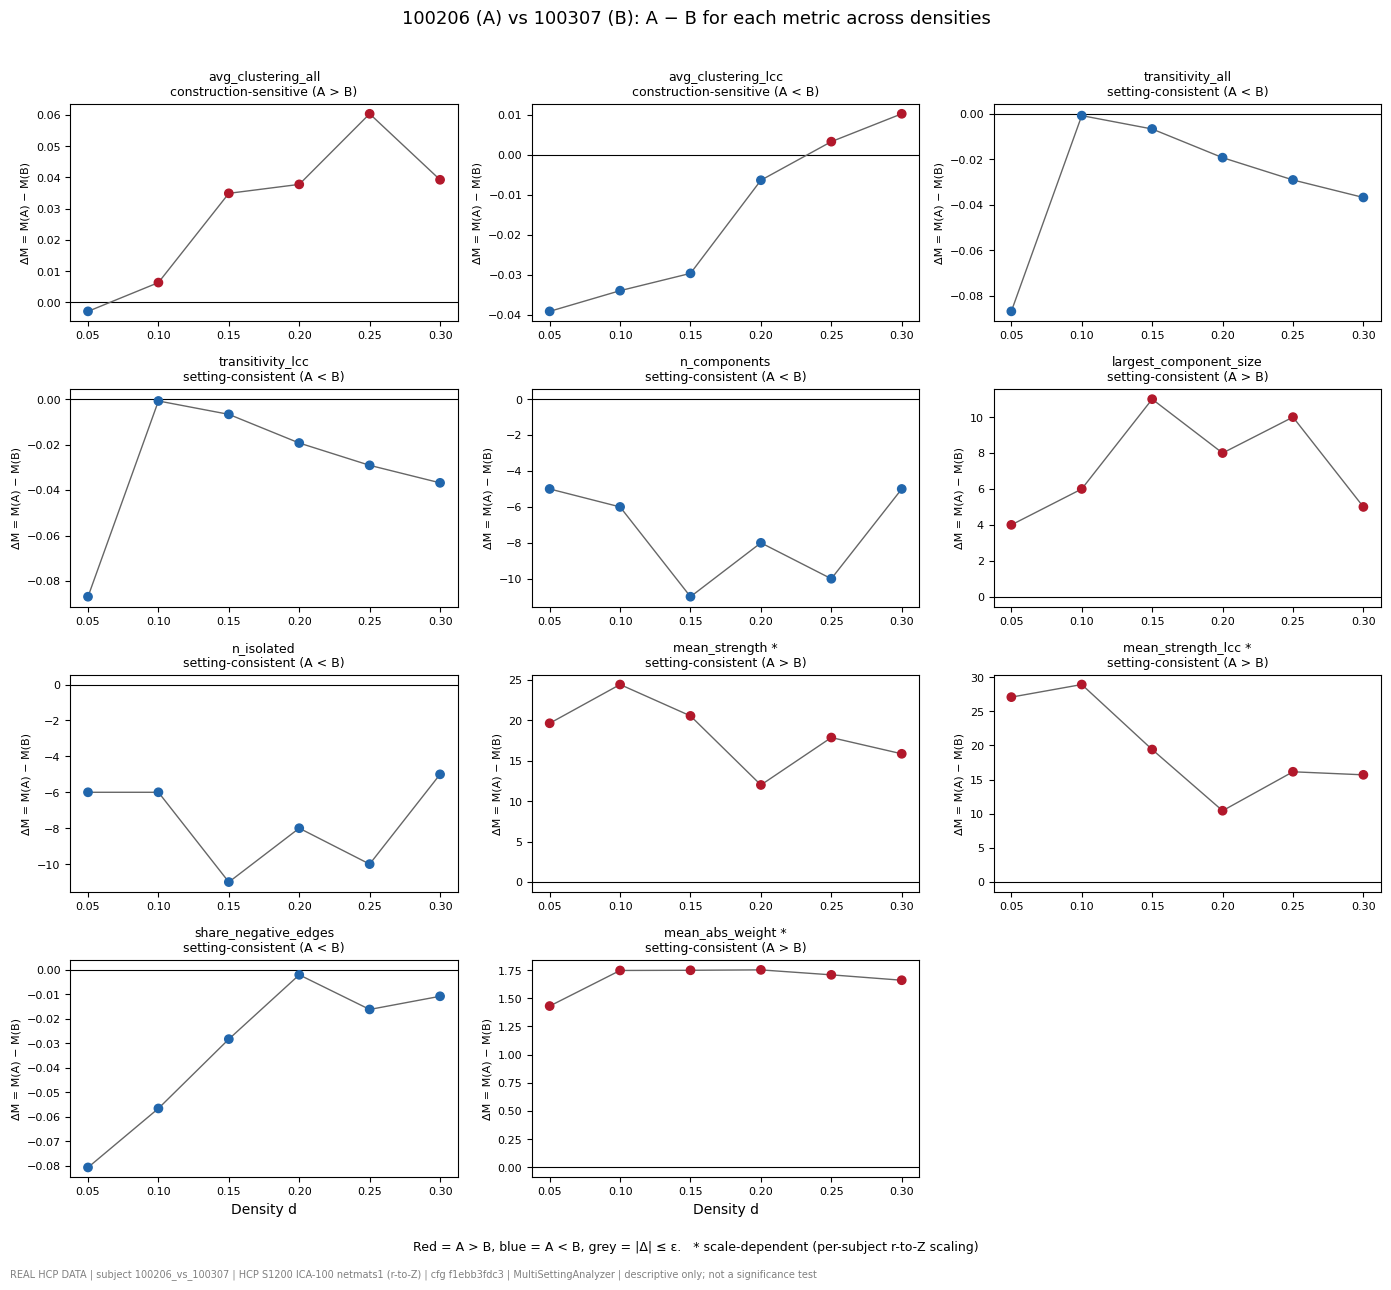

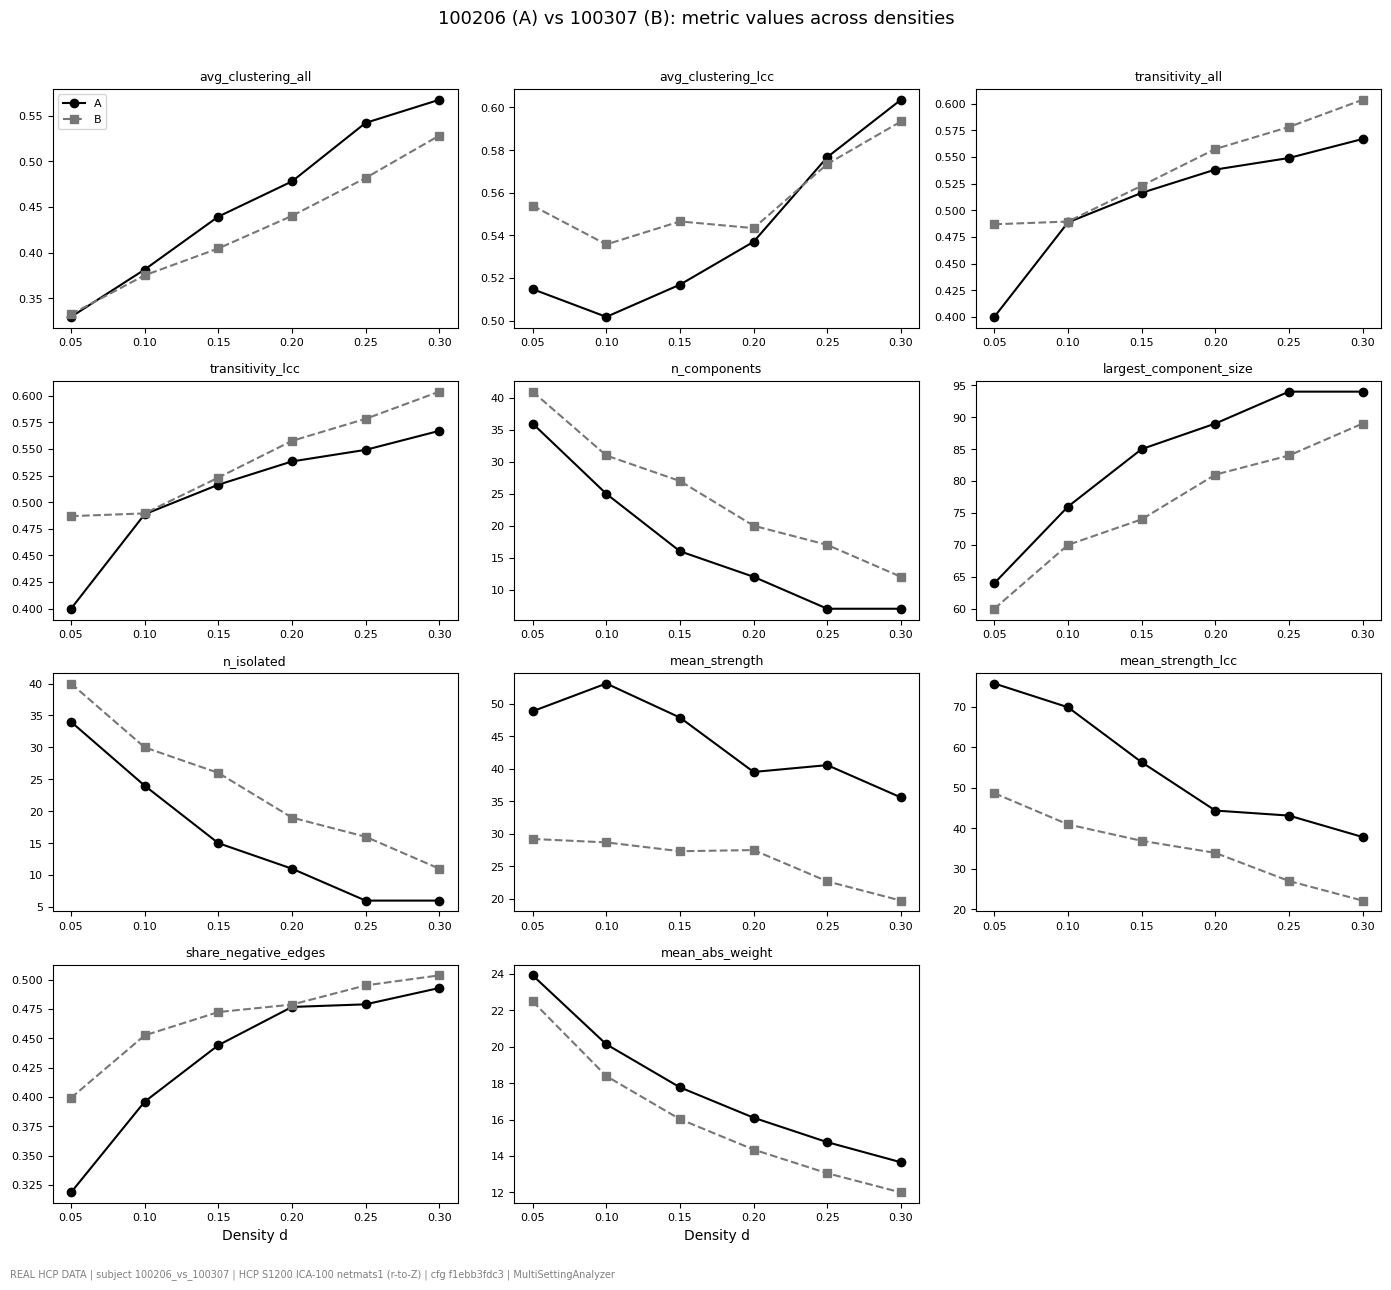

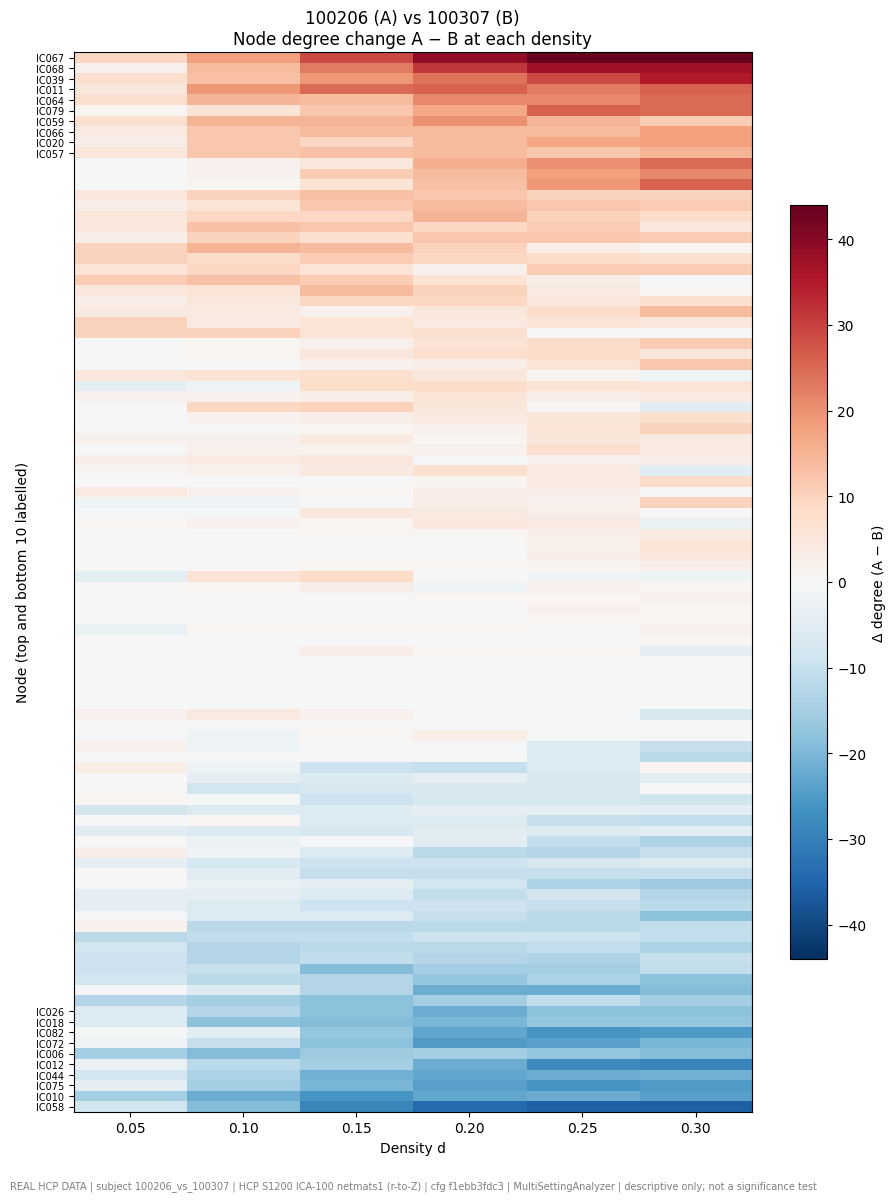

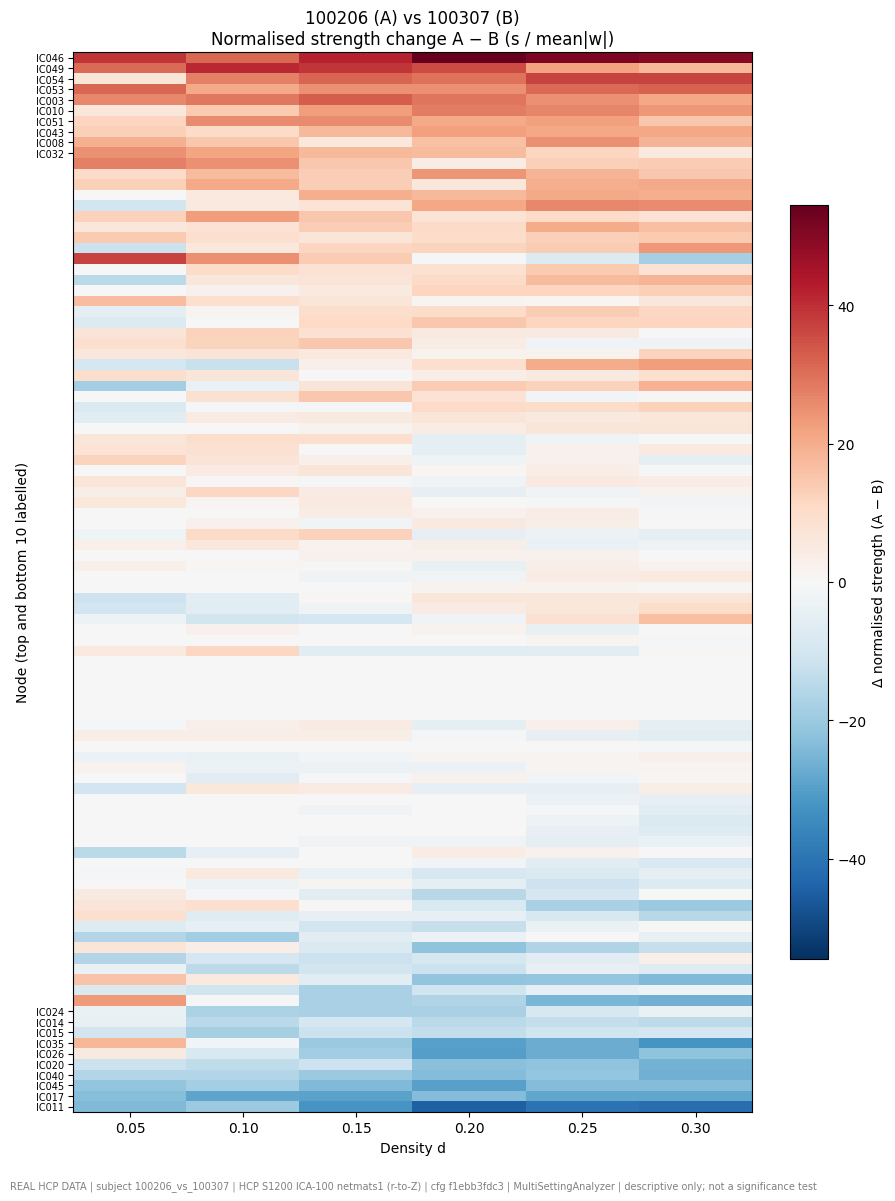

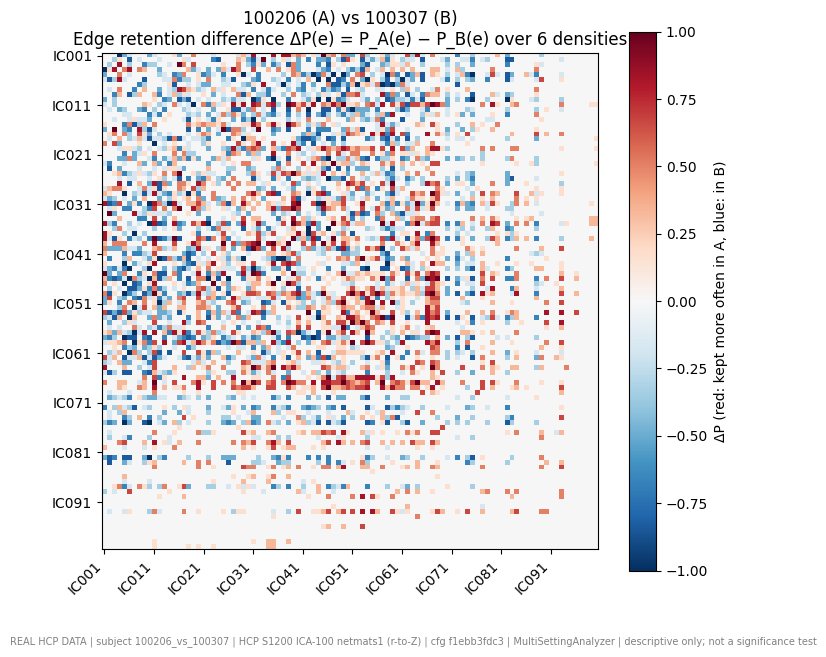

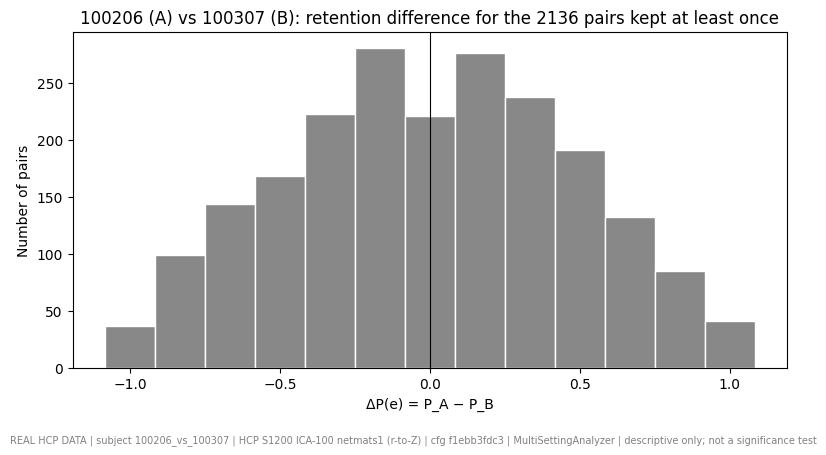

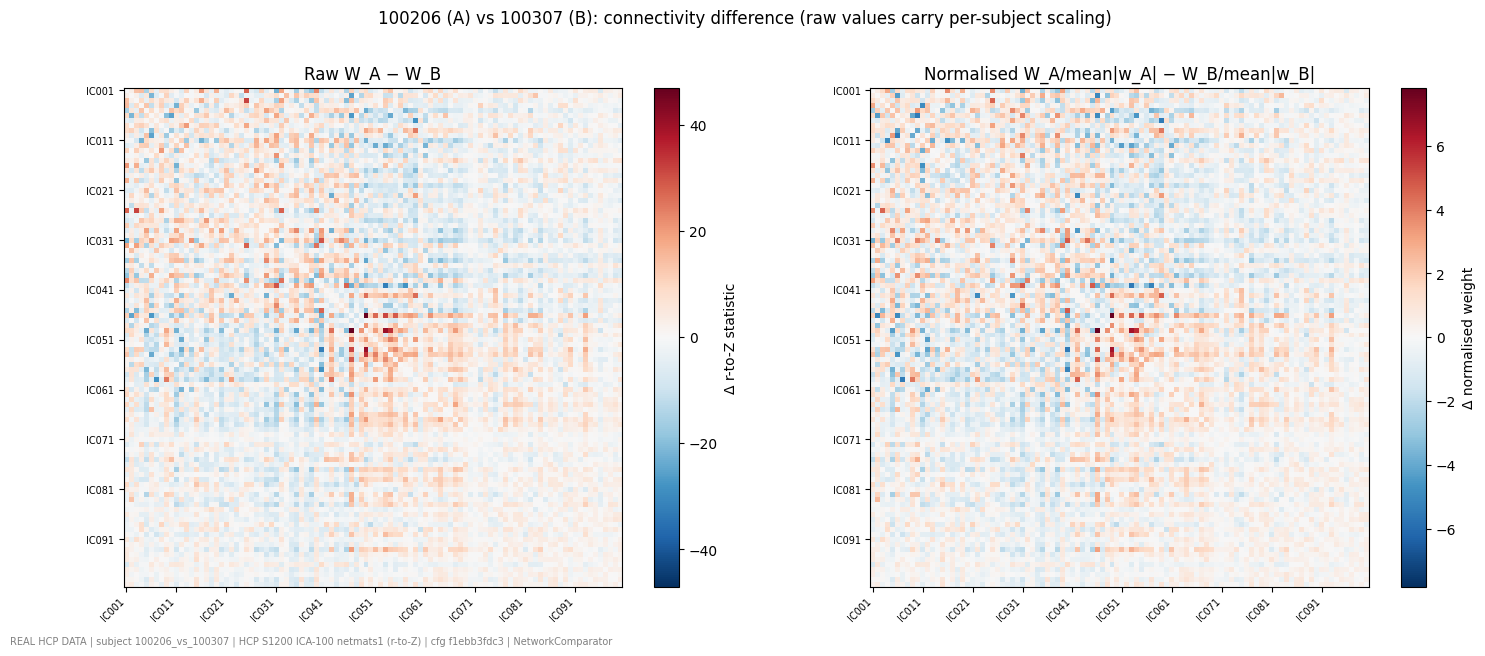

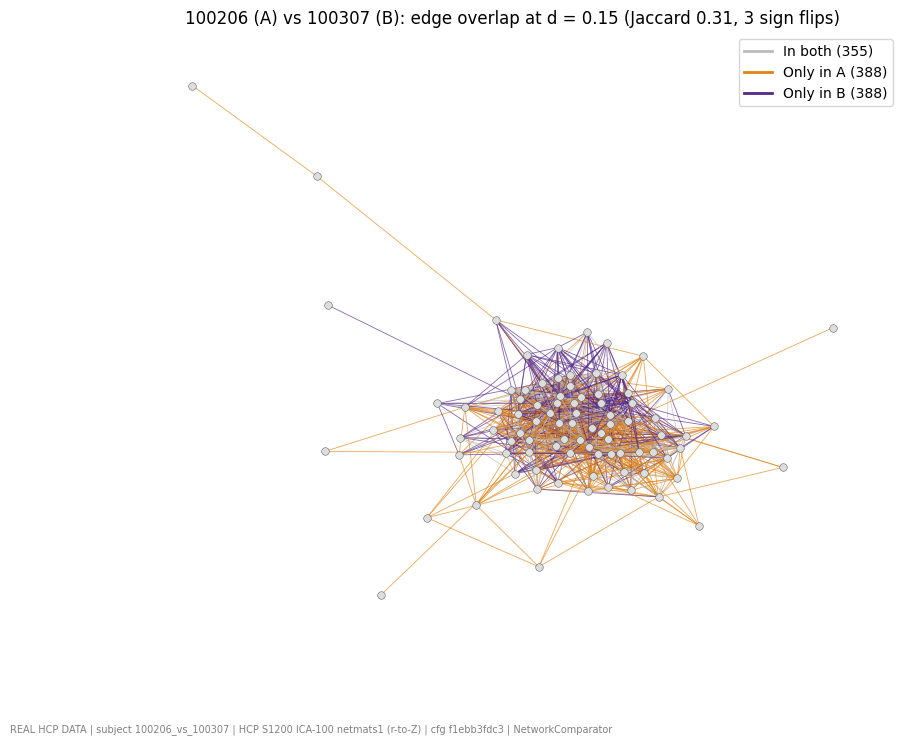

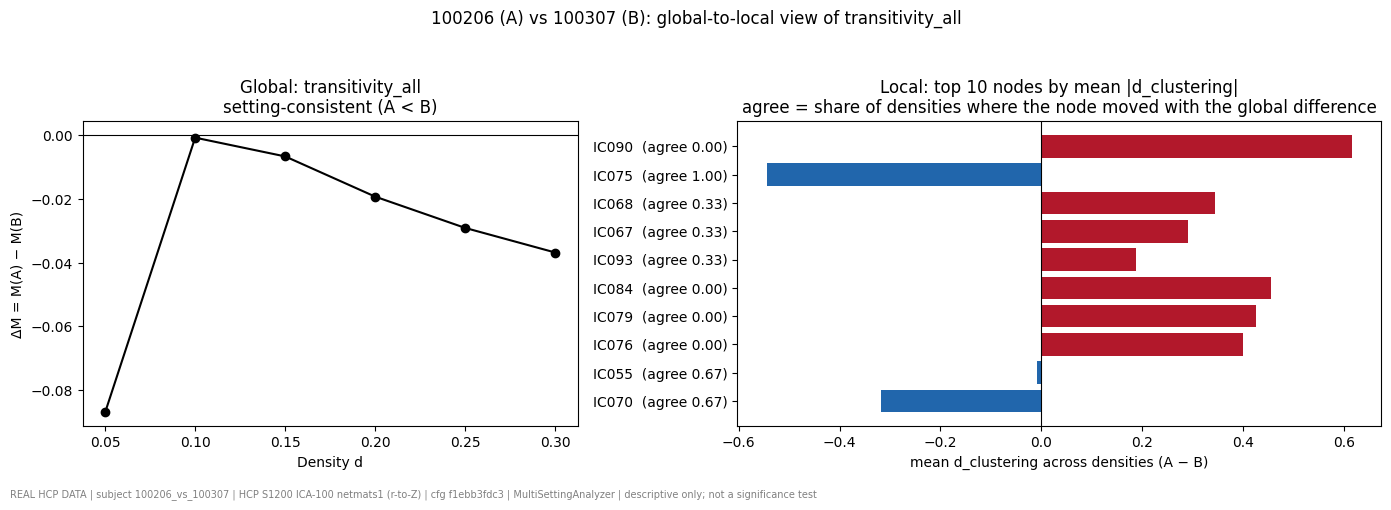

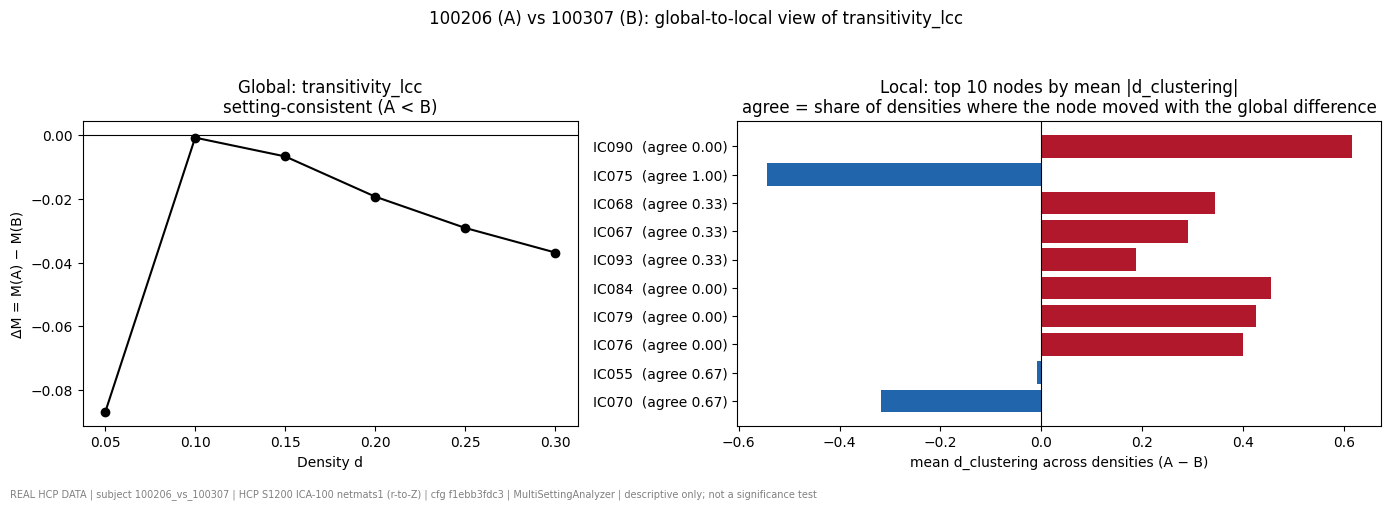

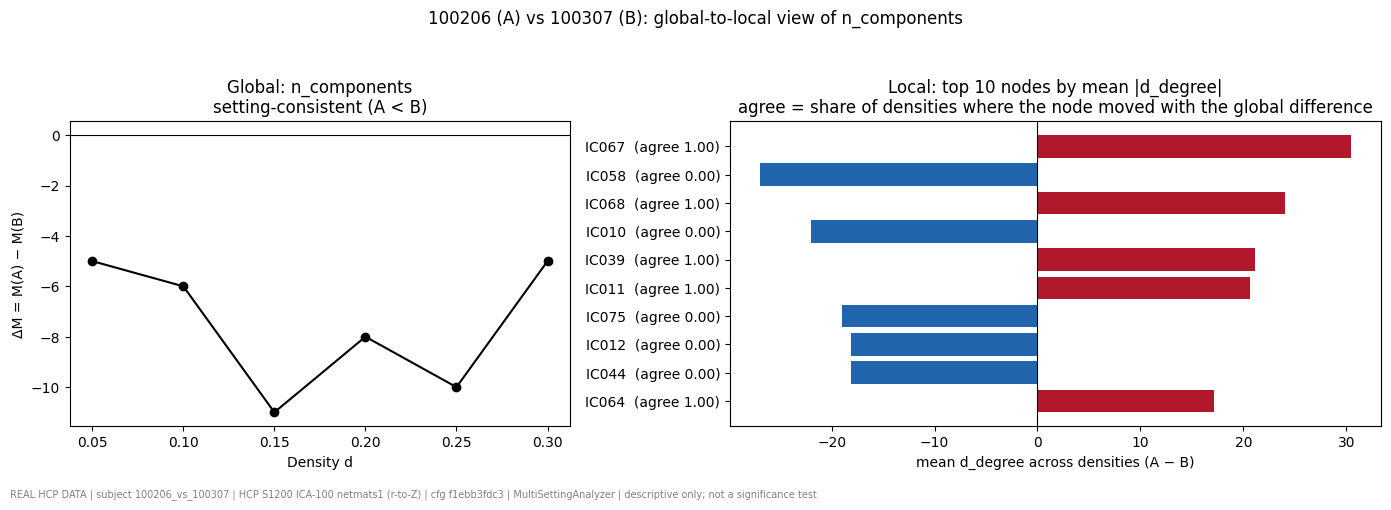

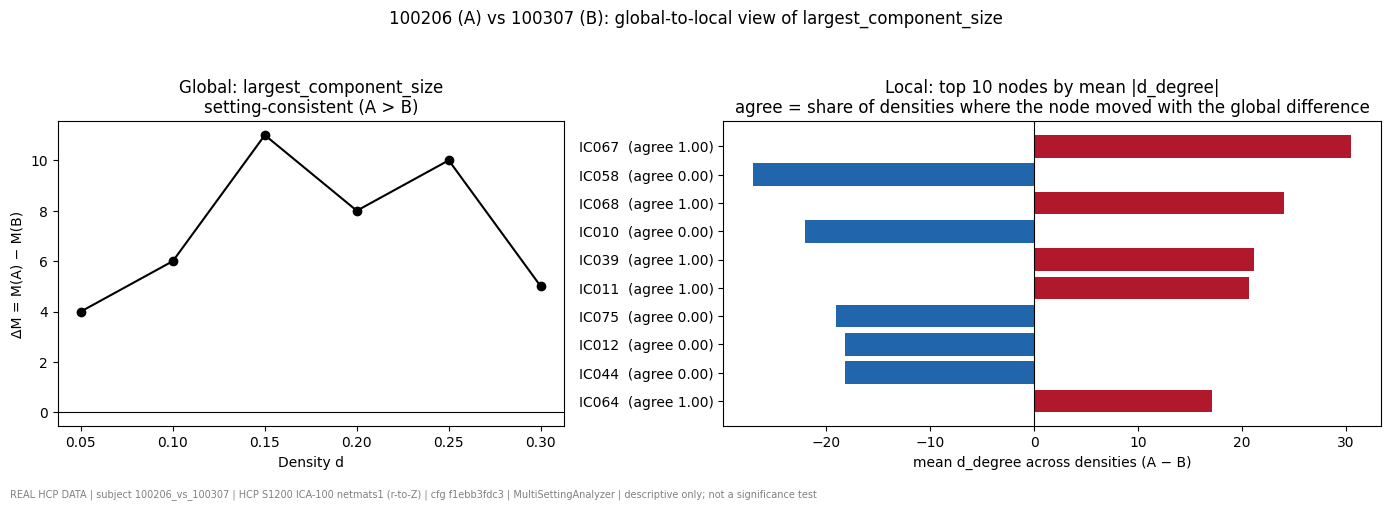

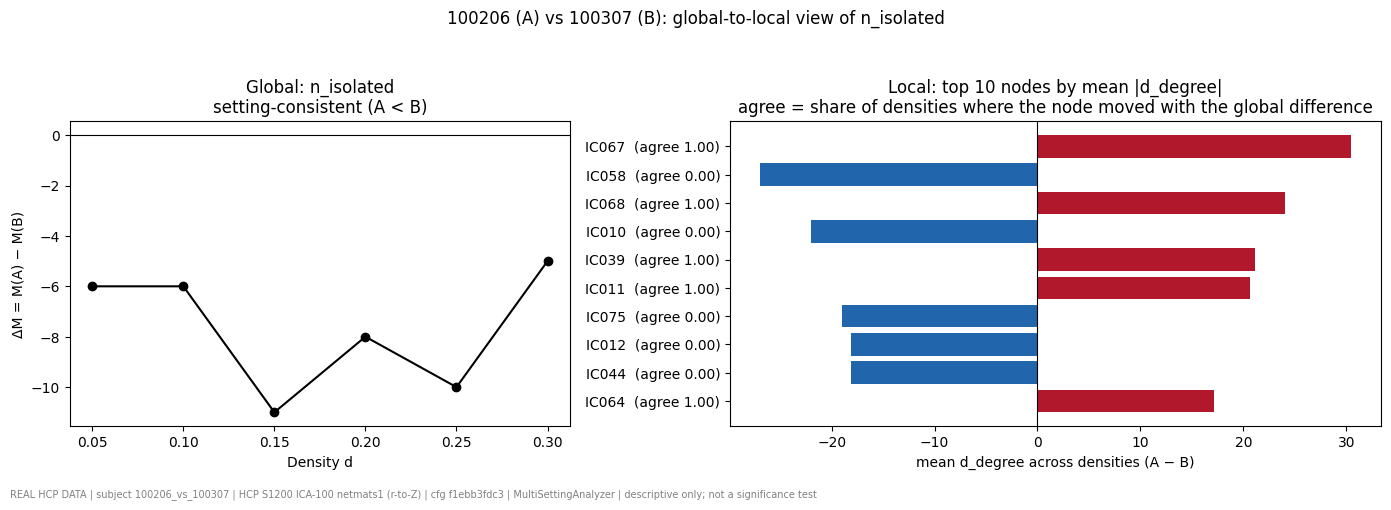

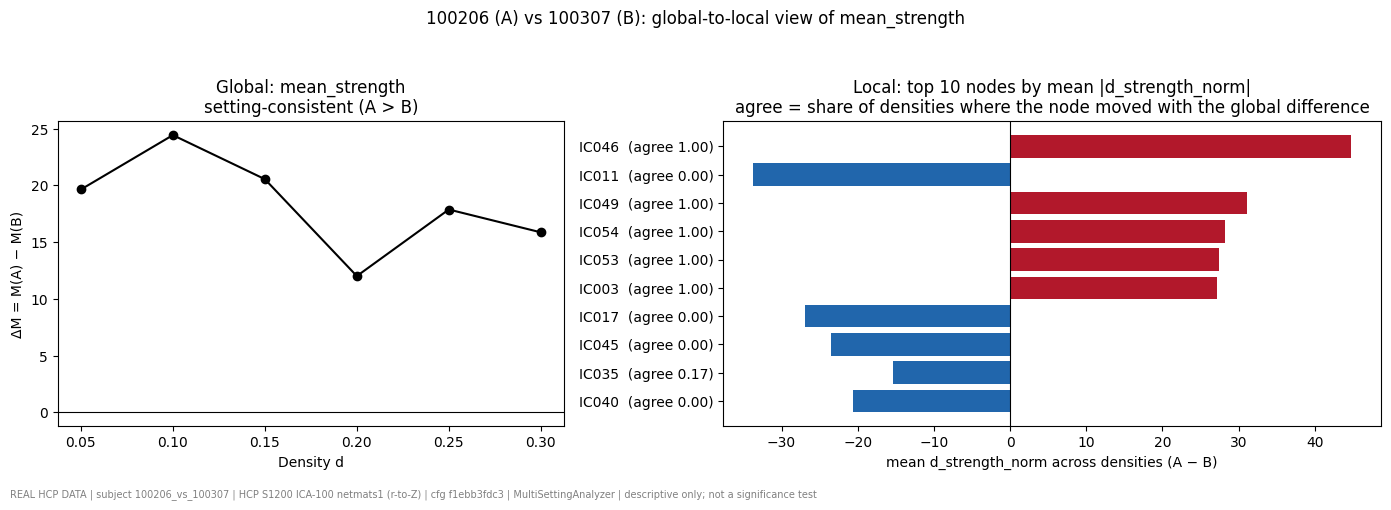

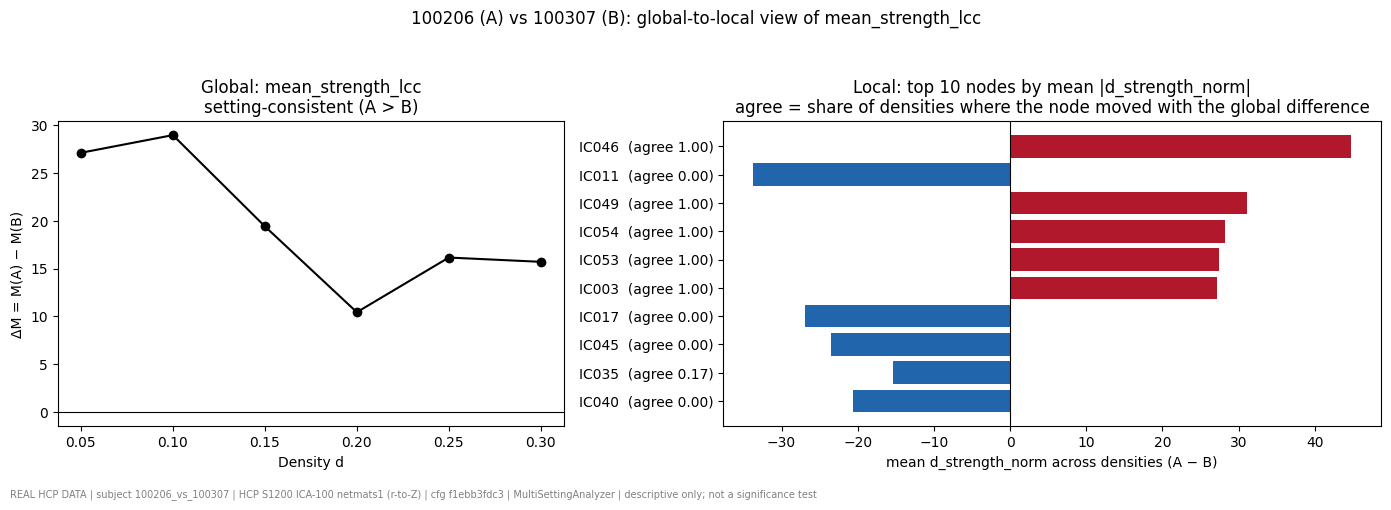

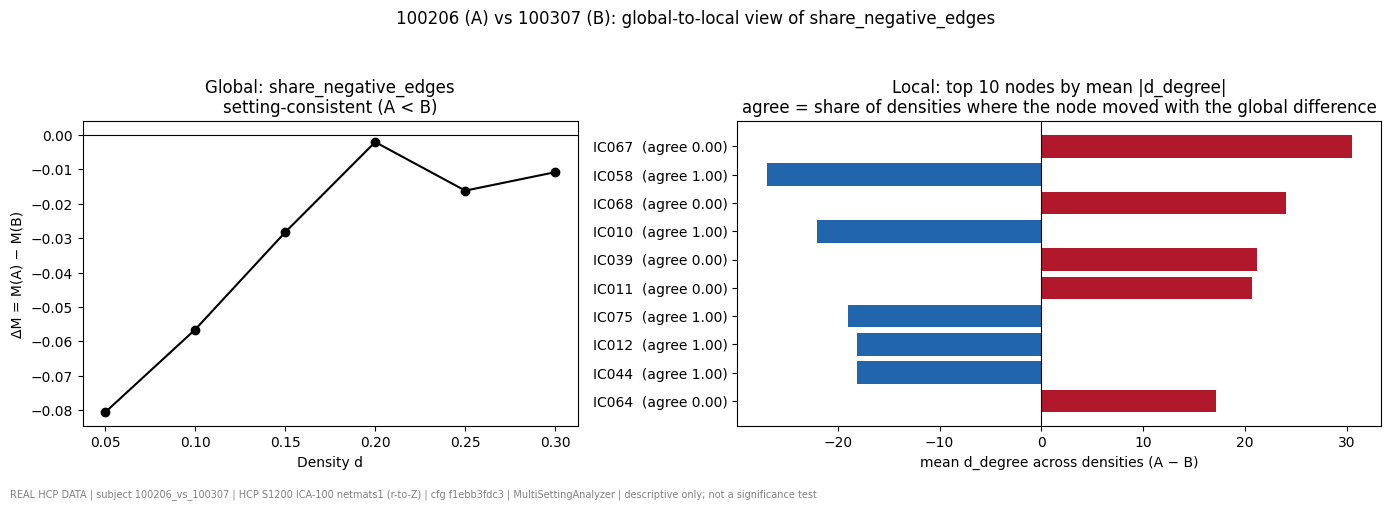

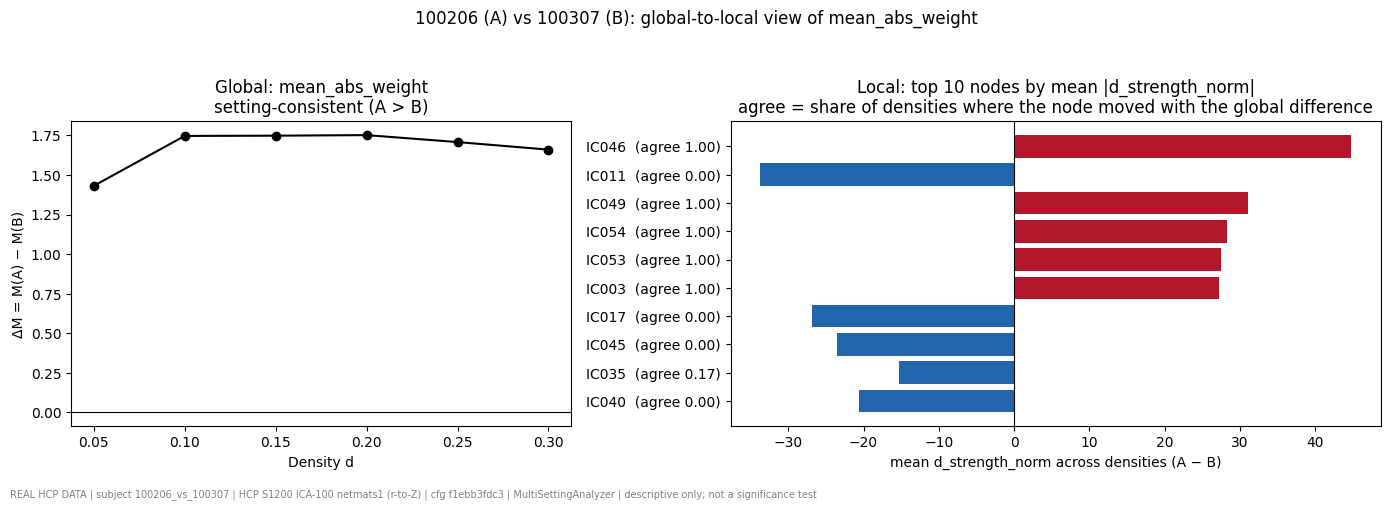

C23 figures added: 17 | total FIGURES: 26
['AB_degree_strength', 'AB_delta_profiles', 'AB_edge_overlap_network', 'AB_g2l_largest_component_size', 'AB_g2l_mean_abs_weight', 'AB_g2l_mean_strength', 'AB_g2l_mean_strength_lcc', 'AB_g2l_n_components', 'AB_g2l_n_isolated', 'AB_g2l_share_negative_edges', 'AB_g2l_transitivity_all', 'AB_g2l_transitivity_lcc', 'AB_node_degree_heatmap', 'AB_node_strength_heatmap', 'AB_retention_hist', 'AB_retention_matrix', 'AB_shortest_path_status', 'AB_values_vs_density', 'AB_weight_difference']
C23 ready


In [31]:
# =============================================================================
# C23 | Module J part 2: Comparison and research figures (Algorithm doc §14)
# Reads : C09 (proc_A, proc_B), C12 (stats_A, stats_B), C19 (FIGURES, stamp, COLOR_POS, COLOR_NEG),
#         C20 (cmp_AB, COMPARE_METRICS, SCALE_DEPENDENT), C21 (G2L_MAP), C22 (ms_AB)
# Writes: new "AB_*" keys in FIGURES only
# Rule  : every number comes from the result objects; every figure is stamped.
# =============================================================================

_PAIR = f"{cmp_AB.id_A} (A) vs {cmp_AB.id_B} (B)"
_DESC = "descriptive only; not a significance test"
_COLOR_ZERO = "#999999"
_COLOR_A_ONLY = "#e08214"     # orange: edge only in A (red/blue stay reserved for edge sign)
_COLOR_B_ONLY = "#542788"     # purple: edge only in B
_COLOR_BOTH = "#bbbbbb"


def _label_of(metric):
    """'label (direction)' for a metric from the consistency table."""
    row = ms_AB.consistency[ms_AB.consistency["metric"] == metric].iloc[0]
    text = row["label"]
    if row["direction"] != "none":
        text = text + " (" + row["direction"] + ")"
    return text


def _metric_grid(title):
    """4 x 3 grid with one panel per metric; the 12th panel is hidden."""
    fig, axes = plt.subplots(4, 3, figsize=(14, 13))
    flat = axes.ravel()
    flat[-1].axis("off")
    fig.suptitle(title, fontsize=13)
    return fig, flat


_d = list(ms_AB.profile["density"])

# 1. AB_delta_profiles: does each A - B keep its sign across densities?
_fig, _axs = _metric_grid(f"{_PAIR}: A − B for each metric across densities")
for _n, _m in enumerate(COMPARE_METRICS):
    _ax = _axs[_n]
    _y = list(ms_AB.profile[_m])
    _cols = []
    for _v in _y:
        if _v > ms_AB.eps:
            _cols.append(COLOR_POS)
        elif _v < -ms_AB.eps:
            _cols.append(COLOR_NEG)
        else:
            _cols.append(_COLOR_ZERO)
    _ax.axhline(0, color="black", linewidth=0.8)
    _ax.plot(_d, _y, color="#666666", linewidth=1)
    _ax.scatter(_d, _y, c=_cols, zorder=3)
    _ttl = _m
    if _m in SCALE_DEPENDENT:
        _ttl = _ttl + " *"
    _ax.set_title(_ttl + "\n" + _label_of(_m), fontsize=9)
    _ax.set_xticks(_d)
    _ax.tick_params(labelsize=8)
    _ax.set_ylabel("ΔM = M(A) − M(B)", fontsize=8)
_axs[9].set_xlabel("Density d")
_axs[10].set_xlabel("Density d")
_fig.text(0.5, 0.025, "Red = A > B, blue = A < B, grey = |Δ| ≤ ε.   * scale-dependent (per-subject r-to-Z scaling)",
          ha="center", fontsize=9)
_fig.tight_layout(rect=[0, 0.04, 1, 0.97])
stamp(_fig, ms_AB.provenance, _DESC)
FIGURES["AB_delta_profiles"] = _fig
plt.show()

# 2. AB_values_vs_density: the A and B values behind each delta
_fig, _axs = _metric_grid(f"{_PAIR}: metric values across densities")
for _n, _m in enumerate(COMPARE_METRICS):
    _ax = _axs[_n]
    _ax.plot(_d, ms_AB.values[f"{_m}_A"], marker="o", linestyle="-", color="black", label="A")
    _ax.plot(_d, ms_AB.values[f"{_m}_B"], marker="s", linestyle="--", color="#777777", label="B")
    _ax.set_title(_m, fontsize=9)
    _ax.set_xticks(_d)
    _ax.tick_params(labelsize=8)
    if _n == 0:
        _ax.legend(fontsize=8)
_axs[9].set_xlabel("Density d")
_axs[10].set_xlabel("Density d")
_fig.tight_layout(rect=[0, 0.02, 1, 0.97])
stamp(_fig, ms_AB.provenance)
FIGURES["AB_values_vs_density"] = _fig
plt.show()


# 3-4. Node x density heatmaps (degree, normalised strength)
def _node_heatmap(col, title, key, unit):
    """Rows = 100 nodes sorted by mean change, columns = densities."""
    piv = ms_AB.node_profile.pivot(index="node", columns="density", values=col)
    order = piv.mean(axis=1).sort_values(ascending=False).index
    piv = piv.loc[order]
    lim = float(np.nanmax(np.abs(piv.values)))
    fig, ax = plt.subplots(figsize=(9, 12))
    im = ax.imshow(piv.values, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels([f"{c:.2f}" for c in piv.columns])
    ax.set_xlabel("Density d")
    ticks = list(range(10)) + list(range(len(order) - 10, len(order)))
    ax.set_yticks(ticks)
    ax.set_yticklabels([proc_A.labels[int(order[t])] for t in ticks], fontsize=7)
    ax.set_ylabel("Node (top and bottom 10 labelled)")
    ax.set_title(f"{_PAIR}\n{title}")
    bar = fig.colorbar(im, ax=ax, fraction=0.05)
    bar.set_label(unit)
    fig.tight_layout(rect=[0, 0.02, 1, 1])
    stamp(fig, ms_AB.provenance, _DESC)
    FIGURES[key] = fig
    plt.show()


_node_heatmap("d_degree", "Node degree change A − B at each density",
              "AB_node_degree_heatmap", "Δ degree (A − B)")
_node_heatmap("d_strength_norm", "Normalised strength change A − B (s / mean|w|)",
              "AB_node_strength_heatmap", "Δ normalised strength (A − B)")

# 5. AB_retention_matrix: which connections are kept more often in A than in B
_dP = np.zeros((N_NODES, N_NODES))
for _, _r in ms_AB.retention.iterrows():
    _dP[int(_r["i"]), int(_r["j"])] = _r["dP"]
    _dP[int(_r["j"]), int(_r["i"])] = _r["dP"]
_fig, _ax = plt.subplots(figsize=(8, 7))
_im = _ax.imshow(_dP, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
_ticks = list(range(0, N_NODES, 10))
_ax.set_xticks(_ticks)
_ax.set_yticks(_ticks)
_ax.set_xticklabels([proc_A.labels[i] for i in _ticks], rotation=45, ha="right")
_ax.set_yticklabels([proc_A.labels[i] for i in _ticks])
_ax.set_title(f"{_PAIR}\nEdge retention difference ΔP(e) = P_A(e) − P_B(e) over {len(ms_AB.settings)} densities")
_bar = _fig.colorbar(_im, ax=_ax)
_bar.set_label("ΔP (red: kept more often in A, blue: in B)")
stamp(_fig, ms_AB.provenance, _DESC)
FIGURES["AB_retention_matrix"] = _fig
plt.show()

# 6. AB_retention_hist: how many pairs differ in retention, and by how much
_kept = ms_AB.retention[(ms_AB.retention["count_A"] > 0) | (ms_AB.retention["count_B"] > 0)]
_K = len(ms_AB.settings)
_bins = np.arange(-1 - 0.5 / _K, 1 + 1 / _K, 1 / _K)
_fig, _ax = plt.subplots(figsize=(8, 4.5))
_ax.hist(_kept["dP"], bins=_bins, color="#888888", edgecolor="white")
_ax.axvline(0, color="black", linewidth=0.8)
_ax.set_xlabel("ΔP(e) = P_A − P_B")
_ax.set_ylabel("Number of pairs")
_ax.set_title(f"{_PAIR}: retention difference for the {len(_kept)} pairs kept at least once")
_fig.tight_layout(rect=[0, 0.04, 1, 1])
stamp(_fig, ms_AB.provenance, _DESC)
FIGURES["AB_retention_hist"] = _fig
plt.show()

# 7. AB_weight_difference: raw and normalised connectivity difference
_scale_A = stats_A.global_values["mean_abs"]
_scale_B = stats_B.global_values["mean_abs"]
_raw = proc_A.W - proc_B.W
_norm = proc_A.W / _scale_A - proc_B.W / _scale_B
_fig, _axs2 = plt.subplots(1, 2, figsize=(15, 6.5))
for _ax, _mat, _ttl, _unit in [
    (_axs2[0], _raw, "Raw W_A − W_B", "Δ r-to-Z statistic"),
    (_axs2[1], _norm, "Normalised W_A/mean|w_A| − W_B/mean|w_B|", "Δ normalised weight"),
]:
    _lim = float(np.max(np.abs(_mat)))
    _im = _ax.imshow(_mat, cmap="RdBu_r", vmin=-_lim, vmax=_lim, interpolation="nearest")
    _ax.set_xticks(_ticks)
    _ax.set_yticks(_ticks)
    _ax.set_xticklabels([proc_A.labels[i] for i in _ticks], rotation=45, ha="right", fontsize=7)
    _ax.set_yticklabels([proc_A.labels[i] for i in _ticks], fontsize=7)
    _ax.set_title(_ttl)
    _b = _fig.colorbar(_im, ax=_ax, fraction=0.046)
    _b.set_label(_unit)
_fig.suptitle(f"{_PAIR}: connectivity difference (raw values carry per-subject scaling)")
_fig.tight_layout(rect=[0, 0.03, 1, 0.95])
stamp(_fig, cmp_AB.provenance)
FIGURES["AB_weight_difference"] = _fig
plt.show()

# 8. AB_edge_overlap_network: which edges are shared at the base density
_U = nx.Graph()
_U.add_nodes_from(range(N_NODES))
_ecol = []
_ed = []
for _, _r in cmp_AB.edge_diff.iterrows():
    _ed.append((int(_r["i"]), int(_r["j"])))
    if _r["status"] == "both":
        _ecol.append(_COLOR_BOTH)
    elif _r["status"] == "A_only":
        _ecol.append(_COLOR_A_ONLY)
    else:
        _ecol.append(_COLOR_B_ONLY)
_U.add_edges_from(_ed)
_conn = sorted(n for n in _U.nodes if _U.degree(n) > 0)
_pos = nx.spring_layout(_U.subgraph(_conn), seed=SEED, weight=None)
_fig, _ax = plt.subplots(figsize=(10, 8))
nx.draw_networkx_edges(_U, _pos, edgelist=_ed, edge_color=_ecol, width=0.6, alpha=0.7, ax=_ax)
nx.draw_networkx_nodes(_U, _pos, nodelist=_conn, node_size=30, node_color="#dddddd",
                       edgecolors="#666666", linewidths=0.4, ax=_ax)
_es = cmp_AB.edge_summary
_ax.legend(handles=[
    Line2D([0], [0], color=_COLOR_BOTH, lw=2, label=f"In both ({_es['n_both']})"),
    Line2D([0], [0], color=_COLOR_A_ONLY, lw=2, label=f"Only in A ({_es['n_A_only']})"),
    Line2D([0], [0], color=_COLOR_B_ONLY, lw=2, label=f"Only in B ({_es['n_B_only']})"),
], loc="upper right")
_ax.set_title(f"{_PAIR}: edge overlap at d = {cmp_AB.density:.2f} "
              f"(Jaccard {_es['jaccard']:.2f}, {_es['n_sign_flips']} sign flips)")
_ax.axis("off")
stamp(_fig, cmp_AB.provenance)
FIGURES["AB_edge_overlap_network"] = _fig
plt.show()

# 9. AB_g2l_<metric>: one panel pair per setting-consistent metric
_consistent = list(ms_AB.consistency.loc[ms_AB.consistency["label"] == "setting-consistent", "metric"])
for _m in _consistent:
    _rows = ms_AB.g2l_summary[(ms_AB.g2l_summary["metric"] == _m) &
                              (ms_AB.g2l_summary["level"] == "node")].sort_values("rank")
    _fig, (_a1, _a2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.3]})
    _y = list(ms_AB.profile[_m])
    _a1.axhline(0, color="black", linewidth=0.8)
    _a1.plot(_d, _y, marker="o", color="black")
    _a1.set_xticks(_d)
    _a1.set_xlabel("Density d")
    _a1.set_ylabel("ΔM = M(A) − M(B)")
    _a1.set_title(f"Global: {_m}\n{_label_of(_m)}")
    _vals = list(_rows["mean_delta"])[::-1]
    _names = []
    for _lab, _ag in zip(list(_rows["node_label"])[::-1], list(_rows["sign_agreement"])[::-1]):
        _names.append(f"{_lab}  (agree {_ag:.2f})")
    _bc = []
    for _v in _vals:
        if _v >= 0:
            _bc.append(COLOR_POS)
        else:
            _bc.append(COLOR_NEG)
    _a2.barh(_names, _vals, color=_bc)
    _a2.axvline(0, color="black", linewidth=0.8)
    _a2.set_xlabel(f"mean {G2L_MAP[_m]} across densities (A − B)")
    _a2.set_title(f"Local: top {len(_rows)} nodes by mean |{G2L_MAP[_m]}|\n"
                  "agree = share of densities where the node moved with the global difference")
    _fig.suptitle(f"{_PAIR}: global-to-local view of {_m}")
    _fig.tight_layout(rect=[0, 0.03, 1, 0.94])
    stamp(_fig, ms_AB.provenance, _DESC)
    FIGURES[f"AB_g2l_{_m}"] = _fig
    plt.show()

_ab = [k for k in sorted(FIGURES) if k.startswith("AB_")]
print("C23 figures added:", len(_ab) - 2, "| total FIGURES:", len(FIGURES))
print(_ab)
print("C23 ready")

In [32]:
# =============================================================================
# C24 | Tests for Modules H-I (Algorithm doc §16)
# Reads : C20 (check_compatibility, compare_networks), C21 (classify_metric,
#         run_multi_setting), C16 (bellman_ford), C05T/C08T helpers (_check, _sym)
# Writes: nothing global (all data here are TEST FIXTURES)
# =============================================================================
_passed = 0
_failed = 0


def _proc100(W, sid, labels=None):
    """100x100 fixture ProcessedMatrix with its own subject ID and a shared fixture source."""
    W = np.array(W, dtype=float)
    if labels is None:
        labels = make_labels(W.shape[0])
    prov = make_provenance(sid, "C24", CFG, source_file="FIXTURE_SOURCE#row0", is_fixture=True)
    return ProcessedMatrix(sid, W, labels, [], 0, prov)


def _expect_value_error(fn):
    """True if calling fn raises ValueError."""
    try:
        fn()
    except ValueError:
        return True
    return False


_WA = _sym() * 10
_WB = _sym() * 10
_PA = _proc100(_WA, "FA")
_PA_copy = _proc100(_WA, "FA2")
_PB = _proc100(_WB, "FB")

_Wboost = _WA.copy()
for _n in (5, 17, 42):
    _Wboost[_n, :] = _Wboost[_n, :] * 3
    _Wboost[:, _n] = _Wboost[:, _n] * 3
np.fill_diagonal(_Wboost, 0)
_PB_boost = _proc100(_Wboost, "FB3")

_relabel = make_labels(N_NODES)
_relabel[0], _relabel[1] = _relabel[1], _relabel[0]
_PA_relabel = _proc100(_WA, "FA4", _relabel)
_PA_small = _proc(_sym(50) * 10)

print("C24 | Consistency rule (classify_metric)")
_r = classify_metric([1, 2, 3], 1e-9)
_check("1. [1, 2, 3] -> setting-consistent, A > B, S_M = 1",
       _r["label"] == "setting-consistent" and _r["direction"] == "A > B" and _r["S_M"] == 1.0)
_r = classify_metric([-1, -2, -0.5], 1e-9)
_check("2. [-1, -2, -0.5] -> setting-consistent, A < B",
       _r["label"] == "setting-consistent" and _r["direction"] == "A < B")
_r = classify_metric([1, -1, 2], 1e-9)
_check("3. [1, -1, 2] -> construction-sensitive, S_M = 2/3, A > B",
       _r["label"] == "construction-sensitive" and np.isclose(_r["S_M"], 2 / 3) and _r["direction"] == "A > B")
_r = classify_metric([1, -1], 1e-9)
_check("4. [1, -1] -> construction-sensitive, S_M = 0.5, mixed",
       _r["label"] == "construction-sensitive" and _r["S_M"] == 0.5 and _r["direction"] == "mixed")
_r = classify_metric([0, 1e-12, -1e-12], 1e-9)
_check("5. all within eps -> no difference, S_M NaN, n_zero = 3",
       _r["label"] == "no difference" and np.isnan(_r["S_M"]) and _r["n_zero"] == 3)
_r = classify_metric([1, 0, 2], 1e-9)
_check("6. [1, 0, 2] -> construction-sensitive (a zero breaks strict consistency)",
       _r["label"] == "construction-sensitive")

print("\nMulti-setting behaviour")
_ms_same = run_multi_setting(_PA, _PA_copy, CFG, DENSITY_SETTINGS, COMPARE_METRICS, EPS_ZERO)
_all_zero = True
for _m in COMPARE_METRICS:
    if not np.allclose(_ms_same.profile[_m], 0):
        _all_zero = False
_check("7. identical networks: every delta 0, every label 'no difference', every dP 0",
       _all_zero and set(_ms_same.consistency["label"]) == {"no difference"}
       and bool((_ms_same.retention["dP"] == 0).all()))

_ms_ab = run_multi_setting(_PA, _PB, CFG, DENSITY_SETTINGS, COMPARE_METRICS, EPS_ZERO)
_ms_ba = run_multi_setting(_PB, _PA, CFG, DENSITY_SETTINGS, COMPARE_METRICS, EPS_ZERO)
_neg = True
for _m in COMPARE_METRICS:
    if not np.allclose(_ms_ab.profile[_m], -_ms_ba.profile[_m]):
        _neg = False
_swap = {"A > B": "A < B", "A < B": "A > B", "mixed": "mixed", "none": "none"}
_dirs_ok = True
for _k in range(len(COMPARE_METRICS)):
    if _swap[_ms_ab.consistency["direction"].iloc[_k]] != _ms_ba.consistency["direction"].iloc[_k]:
        _dirs_ok = False
_check("8. swapping A and B negates every delta; labels match; directions swap",
       _neg and list(_ms_ab.consistency["label"]) == list(_ms_ba.consistency["label"]) and _dirs_ok)

_ms_boost = run_multi_setting(_PA, _PB_boost, CFG, DENSITY_SETTINGS, COMPARE_METRICS, EPS_ZERO)
_top3 = _ms_boost.g2l_summary[(_ms_boost.g2l_summary["metric"] == "n_isolated") &
                              (_ms_boost.g2l_summary["level"] == "node")].sort_values("rank").head(3)
_check("9. global-to-local finds the 3 perturbed nodes (5, 17, 42) at the top",
       set(int(x) for x in _top3["node"]) == {5, 17, 42})

_ok, _flags = check_compatibility(_PA, _PA_relabel)
_check("10. reordered labels -> incompatible (BLOCK) and compare_networks refuses",
       (not _ok) and any(f.startswith("BLOCK") for f in _flags)
       and _expect_value_error(lambda: compare_networks(_PA, _PA_relabel, CFG)))
_check("11. different size (50 vs 100) -> run_multi_setting refuses",
       _expect_value_error(lambda: run_multi_setting(_PA, _PA_small, CFG)))
_check("12. one settings ID per density, all different",
       _ms_ab.profile["config_hash"].nunique() == len(DENSITY_SETTINGS))
_expected_sum = sum(n_edges_for_density(d, 4950) for d in DENSITY_SETTINGS) / len(DENSITY_SETTINGS)
_check("13. retention: identical networks give P_A == P_B; sum of P_A = mean edges per setting",
       bool((_ms_same.retention["P_A"] == _ms_same.retention["P_B"]).all())
       and np.isclose(_ms_ab.retention["P_A"].sum(), _expected_sum))

print("\nPairwise comparison")
_cmp = compare_networks(_PA, _PB, CFG)
_es = _cmp.edge_summary
_m15 = n_edges_for_density(CFG.density, 4950)
_check("14. edge summary adds up: both + A_only = m and both + B_only = m",
       _es["n_both"] + _es["n_A_only"] == _m15 and _es["n_both"] + _es["n_B_only"] == _m15)

_gA = build_graph(_PA, CFG)
_gB = build_graph(_PB, CFG)
_spA = bellman_ford(_gA, 0)
_spB = bellman_ford(_gB, 0)
_cmp_neg = compare_networks(_PA, _PB, CFG, sp_A=_spA, sp_B=_spB)
_PApos = _proc100(np.abs(_WA), "FApos")
_PBpos = _proc100(np.abs(_WB), "FBpos")
_spApos = bellman_ford(build_graph(_PApos, CFG), 0)
_spBpos = bellman_ford(build_graph(_PBpos, CFG), 0)
_cmp_pos = compare_networks(_PApos, _PBpos, CFG, sp_A=_spApos, sp_B=_spBpos)
_check("15. path_diff is None with a negative cycle, and a dict when both paths are defined",
       _spA.status == "negative_cycle" and _cmp_neg.path_diff is None
       and _spApos.status == "ok" and _spBpos.status == "ok" and isinstance(_cmp_pos.path_diff, dict))

_check("16. fixture results are refused by RESULTS",
       _expect_value_error(lambda: RESULTS.add("comparison", _cmp))
       and _expect_value_error(lambda: RESULTS.add("multi_setting", _ms_ab)))

print(f"\nC24: {_passed} passed, {_failed} failed")
if _failed > 0:
    raise AssertionError("Fix the failing comparison tests before moving on")

C24 | Consistency rule (classify_metric)
  PASS   1. [1, 2, 3] -> setting-consistent, A > B, S_M = 1
  PASS   2. [-1, -2, -0.5] -> setting-consistent, A < B
  PASS   3. [1, -1, 2] -> construction-sensitive, S_M = 2/3, A > B
  PASS   4. [1, -1] -> construction-sensitive, S_M = 0.5, mixed
  PASS   5. all within eps -> no difference, S_M NaN, n_zero = 3
  PASS   6. [1, 0, 2] -> construction-sensitive (a zero breaks strict consistency)

Multi-setting behaviour
  PASS   7. identical networks: every delta 0, every label 'no difference', every dP 0
  PASS   8. swapping A and B negates every delta; labels match; directions swap
  PASS   9. global-to-local finds the 3 perturbed nodes (5, 17, 42) at the top
  PASS   10. reordered labels -> incompatible (BLOCK) and compare_networks refuses
  PASS   11. different size (50 vs 100) -> run_multi_setting refuses
  PASS   12. one settings ID per density, all different
  PASS   13. retention: identical networks give P_A == P_B; sum of P_A = mean edges p

In [33]:
# =============================================================================
# C25 | Module K: Report and export (Algorithm doc §15)
# Reads : everything stored in RESULTS, FIGURES (C19, C23), ENV_INFO (C01),
#         PROJECT_CONFIG, CFG, DENSITY_SETTINGS, EPS_ZERO, PTN_DIR, OUTPUT_DIR (C02),
#         loader (C06), COMPARE_METRICS, SCALE_DEPENDENT (C20), CONSISTENCY_RULE, G2L_MAP (C21)
# Writes: Report, REPORT_CAVEATS, build_report, export, report, RUN_DIR
# Rule  : never writes inside PTN_DIR; never overwrites an earlier run folder.
# v2 (21 Oct 2026): ICA-node caveat; includes the POST-HOC C22S scale check if it was run.
# v3 (21 Oct 2026): includes the revised protocol v2 (C22R) next to the frozen v1 if it was run.
# v4 (21 Oct 2026): caveats point to the C28 replication and note that C23 figures show v1 labels.
# =============================================================================

REPORT_CAVEATS = [
    "Consistency labels, S_M and dP(e) are descriptive. They are not significance tests and carry no p-values.",
    "'Setting-consistent' means stable across the predefined densities for this pair only. It is not "
    "test-retest reliability, pipeline stability, biological truth or a clinical finding.",
    "This report covers one pair (two subjects). C28 repeats the analysis on 4 more pre-specified pairs "
    "and writes its own replication folder (replication.md); five pairs still do not generalise to a "
    "population.",
    "Weights are HCP netmats1 r-to-Z statistics with subject-specific scaling. Raw strength and weight "
    "differences (mean_strength, mean_strength_lcc, mean_abs_weight, d_strength, d_w) are scale-dependent; "
    "read them with the normalised versions.",
    "Nodes are the 100 group-ICA components of the HCP PTN release, not anatomical parcels: ICA maps are "
    "not binary masks, can overlap, and one map can contain several separated regions (HCP PTN appendix). "
    "'Brain region' in the project statement means 'network node' here.",
    "Graphs are disconnected at every density. Whole-graph and largest-component metrics can disagree.",
    "Shortest paths are undefined in the large components because undirected negative edges create "
    "reachable negative cycles (Algorithm doc 11.1). No path-based comparison is reported.",
    "Figure titles from C23 (delta profiles, global-to-local panels) show the frozen v1 labels. For "
    "mean_abs_weight the v1 label (A > B) is a scale effect; read it with the v2 table in section 10 "
    "(A < B after normalisation).",
    "Global-to-local rows show which nodes and edges change together with a global difference, not what "
    "caused it. Two links are coarse: share_negative_edges -> node degree, mean_abs_weight -> normalised "
    "signed strength.",
    "Several setting-consistent metrics are not independent: n_components, n_isolated and "
    "largest_component_size all measure fragmentation; transitivity_all equals transitivity_lcc here; "
    "mean_strength and mean_strength_lcc move together.",
    "Protocol v2 (C22R) was written after the main pair was seen, so for this pair it is a revision "
    "reported next to the frozen v1 labels, not a replacement. It removes per-subject scale from "
    "strength/weight metrics and ignores per-density gaps under 1% of the metric's size. It was fixed "
    "before the replication pairs (C28) were run.",
    "Research integrity: the isolated-node pattern (B > A at every density) and the d = 0.15 metric values "
    "were seen before the rules were frozen on 21 Oct 2026. After the first C22 run, a sign_agreement bug "
    "was corrected (C21 v2); labels, profiles and rankings were unchanged.",
    "Threshold sensitivity on its own is not claimed as new. The candidate contribution is the matched "
    "multi-setting workflow linking global differences to local evidence, and it still has to be compared "
    "with the closest published methods.",
]


@dataclass
class Report:
    sections: dict      # title -> markdown text, in order
    tables: dict        # name -> pandas DataFrame
    figures: dict       # name -> matplotlib Figure
    metadata: dict      # env, config, provenance list, dataset identity
    caveats: list       # interpretation-safety notes
    markdown: str       # the full report.md text


def _md_table(df, digits=4):
    """Plain markdown table (no extra packages)."""
    cols = [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, row in df.iterrows():
        cells = []
        for v in row:
            if isinstance(v, float) and v.is_integer() and abs(v) < 1e12:
                cells.append(str(int(v)))
            elif isinstance(v, float):
                cells.append(f"{v:.{digits}f}")
            else:
                cells.append(str(v))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


def _latest(results, kind, subject_id=None):
    """Most recent stored result of a kind (re-running a cell adds a newer copy)."""
    found = results.get(kind, subject_id)
    if not found:
        raise ValueError(f"No '{kind}' result in RESULTS for {subject_id}")
    return found[-1]


def _all_subject_check():
    """Re-validate all subjects in the loader (same check as C06)."""
    n_valid = 0
    n_nan = 0
    max_asym = 0.0
    diag = set()
    for sid in loader.subject_ids:
        rep = validate(load_subject(loader, sid))
        if rep.is_valid:
            n_valid += 1
        n_nan += rep.summary.get("n_nan", 0)
        max_asym = max(max_asym, rep.summary.get("max_asymmetry", 0.0))
        diag.add(rep.summary.get("diag_min"))
        diag.add(rep.summary.get("diag_max"))
    return {"subjects": len(loader), "valid": n_valid, "total_nan": n_nan,
            "max_asymmetry": max_asym, "diagonal_values": sorted(diag)}


def build_report(results=None, figures=None, env=None, project=None):
    """Algorithm K steps 1-10: collect everything into one Report."""
    if results is None:
        results = RESULTS
    if figures is None:
        figures = FIGURES
    if env is None:
        env = ENV_INFO
    if project is None:
        project = PROJECT_CONFIG

    a = SUBJECT_A_ID
    b = SUBJECT_B_ID
    data_a = _latest(results, "connectivity", a)
    data_b = _latest(results, "connectivity", b)
    proc_a = _latest(results, "processed", a)
    proc_b = _latest(results, "processed", b)
    g_a = _latest(results, "graph", a)
    g_b = _latest(results, "graph", b)
    st_a = _latest(results, "statistics", a)
    st_b = _latest(results, "statistics", b)
    me_a = _latest(results, "metrics", a)
    me_b = _latest(results, "metrics", b)
    sp_a = _latest(results, "shortest_path", a)
    sp_b = _latest(results, "shortest_path", b)
    cmp = _latest(results, "comparison")
    ms = _latest(results, "multi_setting")
    trav = {}
    for t in results.get("traversal"):
        trav[(t.provenance.subject_id, t.algorithm)] = t
    val_reports = results.get("validation")

    tables = {}

    # Statistics and metrics, A vs B
    rows = []
    for k, v in st_a.global_values.items():
        if not isinstance(v, list):
            rows.append({"statistic": k, "A": v, "B": st_b.global_values[k]})
    tables["statistics_global"] = pd.DataFrame(rows)
    tables["statistics_nodes_A"] = st_a.node_table
    tables["statistics_nodes_B"] = st_b.node_table
    rows = []
    for k in METRIC_KEYS:
        rows.append({"metric": k, "A": me_a.global_values[k], "B": me_b.global_values[k]})
    tables["metrics_global_d015"] = pd.DataFrame(rows)
    tables["metrics_nodes_A"] = me_a.node_table
    tables["metrics_nodes_B"] = me_b.node_table

    # Traversal and Bellman-Ford
    rows = []
    for (sid, alg), t in sorted(trav.items()):
        n_levels = 0
        if t.depth:
            n_levels = max(t.depth.values()) + 1
        rows.append({"subject": sid, "algorithm": alg, "source": t.source,
                     "source_label": proc_a.labels[t.source], "reachable": len(t.reachable),
                     "unreachable": len(t.unreachable), "bfs_levels": n_levels})
    tables["traversal_summary"] = pd.DataFrame(rows)
    rows = []
    for sid, sp in ((a, sp_a), (b, sp_b)):
        finite = 0
        for v in sp.distances.values():
            if v is not None and v != math.inf:
                finite += 1
        rows.append({"subject": sid, "source": sp.source, "status": sp.status,
                     "undefined": len(sp.undefined_nodes), "unreachable": len(sp.unreachable),
                     "finite": finite})
    tables["shortest_path_summary"] = pd.DataFrame(rows)

    # Comparison and multi-setting
    rows = []
    for k in COMPARE_METRICS:
        rows.append({"metric": k, "A": me_a.global_values[k], "B": me_b.global_values[k],
                     "A_minus_B": cmp.global_diff[k], "scale_dependent": k in SCALE_DEPENDENT})
    tables["comparison_global_d015"] = pd.DataFrame(rows)
    tables["comparison_nodes_d015"] = cmp.node_diff
    tables["comparison_edges_d015"] = cmp.edge_diff
    tables["multi_setting_values"] = ms.values
    tables["multi_setting_profile"] = ms.profile
    tables["multi_setting_consistency"] = ms.consistency
    tables["multi_setting_node_profile"] = ms.node_profile
    tables["multi_setting_retention"] = ms.retention
    tables["multi_setting_g2l"] = ms.g2l_summary
    has_scale_check = "scale_check" in globals() and "scale_check_labels" in globals()
    has_v2 = "consistency_v2" in globals() and "protocol_v2_table" in globals()
    if has_v2:
        tables["protocol_v2_values"] = protocol_v2_table
        tables["protocol_v2_consistency"] = consistency_v2
    if has_scale_check:
        tables["posthoc_scale_check"] = scale_check
        tables["posthoc_scale_check_labels"] = scale_check_labels

    # Dataset identity and provenance
    download = None
    rec = Path(PTN_DIR) / "download_record.json"
    if rec.exists():
        download = json.loads(rec.read_text())
    all_check = _all_subject_check()
    prov_list = []
    for kind in results.kinds():
        for r in results.get(kind):
            p = getattr(r, "provenance", None)
            if p is not None:
                entry = asdict(p)
                entry["kind"] = kind
                prov_list.append(entry)

    cfg_info = asdict(CFG)
    cfg_info["hash"] = CFG.hash()
    metadata = {
        "project": project, "environment": env, "config": cfg_info,
        "density_settings": list(ms.settings), "eps": ms.eps,
        "compare_metrics": list(ms.metrics), "consistency_rule": ms.rule,
        "g2l_map": G2L_MAP, "subjects": {"A": a, "B": b},
        "source_files": {"A": data_a.provenance.source_file, "B": data_b.provenance.source_file},
        "download_record": download, "all_subject_check": all_check,
        "provenance": prov_list,
        "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }

    # Sections (Algorithm doc 15, steps 1-9)
    s = {}
    download_note = "not found"
    if download:
        download_note = "see provenance.json (S3 path, bytes, checksum tag, date)"
    s["1. Dataset identity"] = (
        f"- Dataset: {project['dataset']}; package: {project['package']}\n"
        f"- Parcellation: {project['parcellation']}; representation: {project['representation']} "
        f"(values are r-to-Z statistics from FSLNets, not Pearson r)\n"
        f"- Subjects: A = {a} ({data_a.provenance.source_file}), B = {b} ({data_b.provenance.source_file})\n"
        f"- Download record: {download_note}"
    )
    env_lines = []
    for k, v in env.items():
        env_lines.append(f"- {k}: {v}")
    s["2. Environment"] = "\n".join(env_lines)
    cfg_lines = []
    for k, v in cfg_info.items():
        cfg_lines.append(f"- {k}: {v}")
    s["3. Settings and transformations"] = (
        "\n".join(cfg_lines)
        + f"\n- Density settings: {list(ms.settings)} (K = {len(ms.settings)})\n- eps: {ms.eps}\n"
        + f"- Compared metrics: {', '.join(ms.metrics)}\n- Consistency rule: {ms.rule}\n\n"
        + f"Preprocessing log (A): " + "; ".join(proc_a.transform_log) + "\n\n"
        + f"Preprocessing log (B): " + "; ".join(proc_b.transform_log)
    )
    val_lines = []
    for v in val_reports:
        val_lines.append(f"- {v.summary.get('subject_id')}: valid = {v.is_valid}, issues = {v.issues}, "
                         f"warnings = {v.warnings}")
    s["4. Validation"] = (
        "\n".join(val_lines)
        + f"\n- All subjects: {all_check['valid']} / {all_check['subjects']} valid, "
          f"{all_check['total_nan']} NaN, max asymmetry {all_check['max_asymmetry']}, "
          f"diagonal values {all_check['diagonal_values']}"
    )
    s["5. Descriptive statistics"] = _md_table(tables["statistics_global"])
    s["6. Graph metrics at d = 0.15"] = _md_table(tables["metrics_global_d015"])
    s["7. Traversal (BFS / DFS)"] = _md_table(tables["traversal_summary"])
    s["8. Bellman-Ford"] = (_md_table(tables["shortest_path_summary"]) + "\n\nCaveats:\n- "
                            + "\n- ".join(sp_a.caveats))
    es = cmp.edge_summary
    s["9. Pairwise comparison at d = 0.15"] = (
        _md_table(tables["comparison_global_d015"]) + "\n\n"
        + f"Edges: {es['n_both']} shared, {es['n_A_only']} only in A, {es['n_B_only']} only in B, "
          f"{es['n_sign_flips']} sign flips, Jaccard {es['jaccard']:.3f}.\n\nFlags:\n- "
        + "\n- ".join(cmp.flags)
    )
    consistent = list(ms.consistency.loc[ms.consistency["label"] == "setting-consistent", "metric"])
    sensitive = list(ms.consistency.loc[ms.consistency["label"] == "construction-sensitive", "metric"])
    g2l_lines = []
    for m in consistent:
        top = ms.g2l_summary[(ms.g2l_summary["metric"] == m) & (ms.g2l_summary["level"] == "node")]
        top = top.sort_values("rank").head(5)
        names = []
        for _, r in top.iterrows():
            names.append(f"{r['node_label']} ({r['mean_delta']:+.2f}, agree {r['sign_agreement']:.2f})")
        g2l_lines.append(f"- {m} [{G2L_MAP[m]}]: " + ", ".join(names))
    s["10. Multi-setting analysis"] = (
        f"Setting-consistent ({len(consistent)}): {', '.join(consistent)}\n\n"
        f"Construction-sensitive ({len(sensitive)}): {', '.join(sensitive)}\n\n"
        + _md_table(ms.consistency) + "\n\nA - B at each density:\n\n"
        + _md_table(ms.profile.drop(columns=["config_hash"])) + "\n\n"
        + "Global-to-local, top 5 nodes per setting-consistent metric (mean A - B, sign agreement):\n"
        + "\n".join(g2l_lines)
    )
    if has_scale_check:
        s["10. Multi-setting analysis"] += (
            "\n\n**Post-hoc scale check (C22S, added after the frozen run; labels above are unchanged).** "
            "Each scale-dependent metric divided by that subject's own mean|w| over all 4950 pairs:\n\n"
            + _md_table(scale_check_labels)
        )
    if has_v2:
        s["10. Multi-setting analysis"] += (
            "\n\n**Revised protocol v2 (C22R).** " + CONSISTENCY_RULE_V2
            + "\n\nv1 (frozen) and v2 labels for this pair:\n\n" + _md_table(consistency_v2)
        )
    fig_lines = []
    for k in sorted(figures):
        fig_lines.append(f"- figures/{k}.png")
    s["11. Figures"] = "\n".join(fig_lines)
    s["12. Caveats and limits"] = "- " + "\n- ".join(REPORT_CAVEATS)

    md = [f"# Brain Connectome Visualization and Analysis System: report",
          "", f"Generated {metadata['created_at']} UTC. Config {cfg_info['hash']}. "
              f"Pair {a} (A) vs {b} (B).", ""]
    for title, body in s.items():
        md.append(f"## {title}")
        md.append("")
        md.append(body)
        md.append("")
    return Report(s, tables, dict(figures), metadata, list(REPORT_CAVEATS), "\n".join(md))


def export(report, out_dir=None, formats=("md", "csv", "png", "json")):
    """Algorithm K steps 11-12: write one new, never-overwritten run folder."""
    if out_dir is None:
        out_dir = OUTPUT_DIR
    allowed = {"md", "csv", "png", "json"}
    for f in formats:
        if f not in allowed:
            raise ValueError(f"Unsupported export format: {f}")

    out_dir = Path(out_dir)
    ptn = Path(PTN_DIR).resolve()
    target = out_dir.resolve()
    if target == ptn or ptn in target.parents:
        raise ValueError("Refusing to write inside PTN_DIR (source data)")

    stamp_time = datetime.now().strftime("%Y%m%d-%H%M%S")
    run_dir = out_dir / f"run_{stamp_time}_{CFG.hash()}"
    run_dir.mkdir(parents=True, exist_ok=False)

    if "csv" in formats:
        (run_dir / "tables").mkdir()
        for name, df in report.tables.items():
            df.to_csv(run_dir / "tables" / f"{name}.csv", index=False)
    if "png" in formats:
        (run_dir / "figures").mkdir()
        for name, fig in report.figures.items():
            fig.savefig(run_dir / "figures" / f"{name}.png", dpi=150, bbox_inches="tight")
    if "json" in formats:
        meta = report.metadata
        cfg_part = {k: meta[k] for k in ("config", "density_settings", "eps", "compare_metrics",
                                         "consistency_rule", "g2l_map", "subjects")}
        (run_dir / "config.json").write_text(json.dumps(cfg_part, indent=2, default=str))
        (run_dir / "provenance.json").write_text(json.dumps(
            {"source_files": meta["source_files"], "download_record": meta["download_record"],
             "all_subject_check": meta["all_subject_check"], "results": meta["provenance"]},
            indent=2, default=str))
        (run_dir / "environment.json").write_text(json.dumps(
            {"environment": meta["environment"], "project": meta["project"],
             "created_at": meta["created_at"]}, indent=2, default=str))
    if "md" in formats:
        (run_dir / "report.md").write_text(report.markdown)
    return run_dir


# ---- Run ---------------------------------------------------------------------
report = build_report()
RUN_DIR = export(report)

print("C25 | Report exported to:", RUN_DIR)
_n_files = 0
for _p in sorted(RUN_DIR.rglob("*")):
    if _p.is_file():
        _n_files += 1
        print(f"   {str(_p.relative_to(RUN_DIR)):55s} {_p.stat().st_size / 1e3:9.1f} KB")
print(f"\n{_n_files} files: {len(report.tables)} tables, {len(report.figures)} figures, "
      f"report.md + 3 JSON")
print("C25 ready: Report, REPORT_CAVEATS, build_report, export, report, RUN_DIR")

C25 | Report exported to: /content/drive/MyDrive/connectome_outputs/run_20261021-171303_f1ebb3fdc3
   config.json                                                   1.6 KB
   environment.json                                              0.7 KB
   figures/AB_degree_strength.png                               76.4 KB
   figures/AB_delta_profiles.png                               316.6 KB
   figures/AB_edge_overlap_network.png                         267.9 KB
   figures/AB_g2l_largest_component_size.png                   153.8 KB
   figures/AB_g2l_mean_abs_weight.png                          146.3 KB
   figures/AB_g2l_mean_strength.png                            151.6 KB
   figures/AB_g2l_mean_strength_lcc.png                        151.2 KB
   figures/AB_g2l_n_components.png                             150.1 KB
   figures/AB_g2l_n_isolated.png                               147.5 KB
   figures/AB_g2l_share_negative_edges.png                     158.2 KB
   figures/AB_g2l_transitivity_all.pn

In [34]:
# =============================================================================
# C26 | Integration tests (Algorithm doc §16)
# Reads : everything (run after C25)
# Writes: nothing global except the _-prefixed test helpers
# v2 (21 Oct 2026): fixed check 9; subject ID no longer hard-coded; scan now also
#     catches 1/w; added per-density A/B setting check and report/export checks.
# =============================================================================

import ast
import tempfile

_passed = 0
_failed = 0
_skipped = 0


def _integration_check(name, condition):
    """Count and print an integration test result."""
    global _passed, _failed
    if condition:
        _passed += 1
        print("PASS:", name)
    else:
        _failed += 1
        print("FAIL:", name)


def _integration_skip(name):
    """Print a skipped integration check."""
    global _skipped
    _skipped += 1
    print("SKIP:", name)


_FORBIDDEN_WEIGHTED = {"shortest_path", "shortest_path_length", "average_shortest_path_length",
                       "closeness_centrality", "betweenness_centrality"}
_WEIGHT_NAMES = {"w", "W", "weight", "abs_weight"}


def _base_name(node):
    """Name behind x, obj.x, x[i] or obj.x[i, j]; '' otherwise."""
    while isinstance(node, ast.Subscript):
        node = node.value
    if isinstance(node, ast.Name):
        return node.id
    if isinstance(node, ast.Attribute):
        return node.attr
    return ""


def _is_weight(node):
    """True for w, W[i, j], obj.weight, G[u][v]['weight'] and similar."""
    while isinstance(node, ast.Subscript):
        key = node.slice
        if isinstance(key, ast.Constant) and key.value in _WEIGHT_NAMES:
            return True
        node = node.value
    return _base_name(node) in _WEIGHT_NAMES


def _is_one(node):
    return isinstance(node, ast.Constant) and node.value in (1, 1.0) and not isinstance(node.value, bool)


def _scan_source(source):
    """Return a list of (problem, line) for Dijkstra, weighted path calls, reciprocal and 1/w."""
    lines = []
    for line in source.splitlines():
        if not line.lstrip().startswith(("!", "%")):
            lines.append(line)
    try:
        tree = ast.parse("\n".join(lines))
    except SyntaxError:
        return []
    found = []
    for node in ast.walk(tree):
        if isinstance(node, (ast.Name, ast.Attribute)):
            name = _base_name(node)
            if "dijkstra" in name.lower():
                found.append((name, node.lineno))
        if isinstance(node, ast.Call):
            name = _base_name(node.func)
            if name in _FORBIDDEN_WEIGHTED:
                for kw in node.keywords:
                    if kw.arg == "weight":
                        found.append((name + " with weight", node.lineno))
            if name == "reciprocal":
                found.append(("np.reciprocal", node.lineno))
            if name == "divide" and len(node.args) == 2:
                if _is_one(node.args[0]) and _is_weight(node.args[1]):
                    found.append(("np.divide(1, w)", node.lineno))
        if isinstance(node, ast.BinOp) and isinstance(node.op, ast.Div):
            if _is_one(node.left) and _is_weight(node.right):
                found.append(("1 / weight", node.lineno))
    return found


print("C26 | Integration tests")

# 1. HCP structure and labels
_integration_check(
    "HCP structure and labels",
    data_A.matrix_original.shape == (100, 100) and
    data_B.matrix_original.shape == (100, 100) and
    val_A.is_valid and val_B.is_valid and
    data_A.labels == make_labels(100) and
    data_B.labels == make_labels(100)
)

# 2. Reproducible graphs
_rebuilt_A = build_graph(proc_A, CFG)
_integration_check("reproducible graph build", edge_list(_rebuilt_A) == edge_list(G_A))

# 3. Reproducible metrics
_rebuilt_metrics_A = compute_metrics(G_A)
try:
    pd.testing.assert_frame_equal(metrics_A.node_table, _rebuilt_metrics_A.node_table)
    _same_node_table = True
except AssertionError:
    _same_node_table = False
_integration_check(
    "reproducible metrics",
    _same_node_table and metrics_A.global_values == _rebuilt_metrics_A.global_values
)

# 4. Reproducible Bellman-Ford
_rebuilt_sp_A = bellman_ford(G_A, SOURCE_NODE)
_integration_check(
    "reproducible Bellman-Ford",
    sp_A.status == _rebuilt_sp_A.status and
    sp_A.undefined_nodes == _rebuilt_sp_A.undefined_nodes and
    sp_A.unreachable == _rebuilt_sp_A.unreachable
)

# 5. Signs and weights preserved end to end
_weight_check = True
for i, j, weight in edge_list(G_A):
    if weight != proc_A.W[i, j]:
        _weight_check = False
        break
_integration_check(
    "signs and weights preserved",
    G_A.n_negative == int(metrics_A.node_table["n_neg_edges"].sum() / 2) and _weight_check
)

# 6. Undefined nodes have no finite distances
_integration_check(
    "undefined distances are None",
    all(sp_A.distances[node] is None for node in sp_A.undefined_nodes)
)

# 7. A and B use matching settings at d = 0.15, and that setting is CFG
_integration_check(
    "same graph configuration for A and B (d = 0.15)",
    metrics_A.provenance.config_hash == metrics_B.provenance.config_hash == CFG.hash()
)

# 8. Traversal reaches the correct connected component
_integration_check(
    "BFS reachability matches connected component",
    trav_A["BFS"].reachable == nx.node_connected_component(G_A.G, SOURCE_NODE) and
    trav_B["BFS"].reachable == nx.node_connected_component(G_B.G, SOURCE_NODE)
)

# 9. Invalid input is rejected by the graph foundation (C11 run_foundation)
with tempfile.TemporaryDirectory() as _tmpdir:
    _bad_path = Path(_tmpdir) / "bad.npy"
    np.save(_bad_path, np.zeros((60, 60)))
    try:
        _foundation_result = run_foundation(_bad_path, "INVALID_TEST")
        _rejected = _foundation_result[3] is None and not _foundation_result[1].is_valid
    except ValueError:
        _rejected = True
_integration_check("60x60 input is rejected (no graph built)", _rejected)

# 10. No test fixtures were stored in RESULTS
_fixture_found = False
for _kind in RESULTS.kinds():
    for _result in RESULTS.get(_kind):
        _prov = getattr(_result, "provenance", None)
        if _prov is not None and _prov.is_fixture:
            _fixture_found = True
_integration_check("no fixtures in RESULTS", not _fixture_found)

# 11. Source data remains unchanged
_original_A = loader.rows[loader.index[data_A.subject_id]].reshape(100, 100)
_original_B = loader.rows[loader.index[data_B.subject_id]].reshape(100, 100)
_integration_check(
    "source data untouched",
    np.array_equal(data_A.matrix_original, _original_A, equal_nan=True) and
    np.array_equal(data_B.matrix_original, _original_B, equal_nan=True)
)

# 12a. The scanner itself works (known bad and good snippets)
_bad_snippets = ["d = 1 / w", "x = 1.0 / G[u][v]['weight']", "y = 1 / W[i, j]",
                 "z = np.reciprocal(W)", "nx.dijkstra_path(G, 0, 1)",
                 "nx.shortest_path(G, 0, 1, weight='weight')", "q = np.divide(1, abs_weight)"]
_good_snippets = ["m = count_A[i, j] / K", "s = strength / scale_A",
                  "nx.shortest_path(G, 0, 1)", "h = w / 2"]
_scanner_ok = True
for _snip in _bad_snippets:
    if not _scan_source(_snip):
        _scanner_ok = False
        print("  scanner missed:", _snip)
for _snip in _good_snippets:
    if _scan_source(_snip):
        _scanner_ok = False
        print("  scanner false alarm:", _snip)
_integration_check("source scanner detects forbidden patterns", _scanner_ok)

# 12b. Scan every notebook code cell (Colab only)
try:
    from google.colab import _message
    _notebook = _message.blocking_request("get_ipynb")["ipynb"]
    _violations = []
    _n_scanned = 0
    for _cell in _notebook["cells"]:
        if _cell.get("cell_type") != "code":
            continue
        _source = "".join(_cell.get("source", []))
        if "C26 |" in _source:
            continue
        _n_scanned += 1
        _cell_name = _source.strip().splitlines()[0][:40]
        if len(_source.strip().splitlines()) > 1:
            _cell_name = _source.strip().splitlines()[1][:40]
        for _v in _scan_source(_source):
            _violations.append((_cell_name, _v))
    print(f"  scanned {_n_scanned} code cells")
    _integration_check("no Dijkstra, weighted path calls, reciprocal or 1/w in notebook",
                       len(_violations) == 0)
    for _violation in _violations:
        print("  Offending code:", _violation)
except Exception as _error:
    _integration_skip(f"notebook source scan unavailable: {_error}")

# 13. Multi-setting: A and B matched at every density, densities vary (Person 3)
_ms_hashes = list(ms_AB.profile["config_hash"])
_expected_hashes = []
for _d in DENSITY_SETTINGS:
    _expected_hashes.append(CFG.with_density(_d).hash())
_integration_check(
    "multi-setting: one setting per density, matching CFG",
    tuple(ms_AB.settings) == tuple(DENSITY_SETTINGS) and
    _ms_hashes == _expected_hashes and len(set(_ms_hashes)) == len(DENSITY_SETTINGS)
)
_integration_check(
    "multi-setting: d = 0.15 row uses the same setting as C09-C18",
    CFG.hash() in _ms_hashes
)
_integration_check(
    "multi-setting: rule and eps are the frozen ones",
    ms_AB.rule == CONSISTENCY_RULE and ms_AB.eps == EPS_ZERO and
    tuple(ms_AB.metrics) == tuple(COMPARE_METRICS)
)
_row_015 = ms_AB.profile[ms_AB.profile["config_hash"] == CFG.hash()].iloc[0]
_same_015 = True
for _k in COMPARE_METRICS:
    if not math.isclose(_row_015[_k], cmp_AB.global_diff[_k], rel_tol=1e-12, abs_tol=1e-12):
        _same_015 = False
        print("  mismatch at d = 0.15:", _k, _row_015[_k], cmp_AB.global_diff[_k])
_integration_check("multi-setting d = 0.15 deltas equal the C20 comparison", _same_015)

# 14. Report and export (C25)
_md_text = (RUN_DIR / "report.md").read_text()
_has_sections = True
for _title in report.sections:
    if f"## {_title}" not in _md_text:
        _has_sections = False
_integration_check(
    "report exported with all sections, tables and figures",
    _has_sections and len(report.sections) == 12 and
    len(list((RUN_DIR / "tables").glob("*.csv"))) == len(report.tables) and
    len(list((RUN_DIR / "figures").glob("*.png"))) == len(report.figures) and
    (RUN_DIR / "provenance.json").exists() and (RUN_DIR / "config.json").exists()
)
_cfg_json = json.loads((RUN_DIR / "config.json").read_text())
_integration_check("exported config hash matches CFG", _cfg_json["config"]["hash"] == CFG.hash())
_integration_check("export folder is outside PTN_DIR",
                   Path(PTN_DIR).resolve() not in RUN_DIR.resolve().parents)
try:
    export(report, out_dir=PTN_DIR)
    _refused = False
except ValueError:
    _refused = True
_integration_check("export refuses to write inside PTN_DIR", _refused)

print(f"\nC26: {_passed} passed, {_failed} failed, {_skipped} skipped")
if _failed > 0:
    raise AssertionError("Fix failed integration checks before submission")

C26 | Integration tests
PASS: HCP structure and labels
PASS: reproducible graph build
PASS: reproducible metrics
PASS: reproducible Bellman-Ford
PASS: signs and weights preserved
PASS: undefined distances are None
PASS: same graph configuration for A and B (d = 0.15)
PASS: BFS reachability matches connected component
PASS: 60x60 input is rejected (no graph built)
PASS: no fixtures in RESULTS
PASS: source data untouched
PASS: source scanner detects forbidden patterns
  scanned 35 code cells
PASS: no Dijkstra, weighted path calls, reciprocal or 1/w in notebook
PASS: multi-setting: one setting per density, matching CFG
PASS: multi-setting: d = 0.15 row uses the same setting as C09-C18
PASS: multi-setting: rule and eps are the frozen ones
PASS: multi-setting d = 0.15 deltas equal the C20 comparison
PASS: report exported with all sections, tables and figures
PASS: exported config hash matches CFG
PASS: export folder is outside PTN_DIR
PASS: export refuses to write inside PTN_DIR

C26: 21 pa

In [35]:
# =============================================================================
# C27 | One-call pipeline: run_pipeline (Algorithm doc §17)
# Reads : C02 (CFG, DENSITY_SETTINGS, EPS_ZERO), C03 (ResultStore), C04-C05 (loader,
#         load_subject, validate), C07 (preprocess), C08 (build_graph, edge_list),
#         C12 (compute_statistics), C13 (compute_metrics), C15 (pick_source, bfs, dfs),
#         C16 (bellman_ford), C20 (compare_networks, COMPARE_METRICS), C21 (run_multi_setting)
# Writes: ANALYSES, run_pipeline, pipe_AB
# Rule  : uses its own ResultStore, so the main RESULTS (and the C25 report) is untouched.
# =============================================================================

ANALYSES = ("statistics", "metrics", "traversal", "shortest_path", "comparison", "multi_setting")

# What each analysis needs to have run first
_NEEDS = {
    "statistics": (),
    "metrics": (),
    "traversal": (),
    "shortest_path": ("traversal",),          # uses the same common source node
    "comparison": ("statistics", "metrics", "shortest_path"),
    "multi_setting": ("statistics",),         # normalised strength uses mean|w|
}


def _with_needs(analyses):
    """Add required earlier analyses and return them in ANALYSES order."""
    wanted = set()
    todo = list(analyses)
    while todo:
        name = todo.pop()
        if name not in _NEEDS:
            raise ValueError(f"Unknown analysis '{name}'. Choose from {ANALYSES}")
        if name not in wanted:
            wanted.add(name)
            for need in _NEEDS[name]:
                todo.append(need)
    ordered = []
    for name in ANALYSES:
        if name in wanted:
            ordered.append(name)
    return ordered


def run_pipeline(subject_a, subject_b, cfg=CFG, analyses=ANALYSES,
                 settings=DENSITY_SETTINGS, store=None, verbose=True):
    """Load -> validate -> preprocess -> build graphs -> chosen analyses, for one pair.

    Same settings for A and B. Stops (ValueError) if either subject is invalid.
    Returns a dict of every result; results are also added to `store`
    (a new ResultStore by default, never the main RESULTS unless passed in).
    """
    if store is None:
        store = ResultStore()
    subject_a = str(subject_a)
    subject_b = str(subject_b)
    if subject_a == subject_b:
        raise ValueError("Subject A and subject B must be different")
    cfg.validate()
    steps = _with_needs(analyses)

    out = {"subjects": (subject_a, subject_b), "config_hash": cfg.hash(),
           "analyses": tuple(steps), "store": store}

    # Foundation (same chain as run_foundation in C11, but from the HCP loader)
    for key, sid in (("A", subject_a), ("B", subject_b)):
        if sid not in loader.index:
            raise ValueError(f"Subject {sid} is not in subjectIDs.txt")
        data = load_subject(loader, sid, cfg)
        rep = validate(data, cfg)
        if not rep.is_valid:
            raise ValueError(f"Subject {sid} failed validation: {rep.issues}")
        proc = preprocess(data, rep, cfg)
        graph = build_graph(proc, cfg)
        store.add("connectivity", data)
        store.add("validation", rep)
        store.add("processed", proc)
        store.add("graph", graph)
        out[f"data_{key}"] = data
        out[f"val_{key}"] = rep
        out[f"proc_{key}"] = proc
        out[f"G_{key}"] = graph
    if out["G_A"].config.hash() != out["G_B"].config.hash():
        raise AssertionError("A and B were built with different settings")
    if verbose:
        print(f"run_pipeline | {subject_a} vs {subject_b} | config {cfg.hash()} | steps: {', '.join(steps)}")
        print(f"   foundation        : both valid, {out['G_A'].n_edges} / {out['G_B'].n_edges} edges")

    if "statistics" in steps:
        out["stats_A"] = store.add("statistics", compute_statistics(out["proc_A"], cfg))
        out["stats_B"] = store.add("statistics", compute_statistics(out["proc_B"], cfg))

    if "metrics" in steps:
        out["metrics_A"] = store.add("metrics", compute_metrics(out["G_A"]))
        out["metrics_B"] = store.add("metrics", compute_metrics(out["G_B"]))
        if verbose:
            print(f"   metrics           : isolated {out['metrics_A'].global_values['n_isolated']} / "
                  f"{out['metrics_B'].global_values['n_isolated']}, components "
                  f"{out['metrics_A'].global_values['n_components']} / "
                  f"{out['metrics_B'].global_values['n_components']}")

    if "traversal" in steps:
        source = pick_source(out["G_A"], out["G_B"])
        out["source"] = source
        out["trav_A"] = {"BFS": bfs(out["G_A"], source), "DFS": dfs(out["G_A"], source)}
        out["trav_B"] = {"BFS": bfs(out["G_B"], source), "DFS": dfs(out["G_B"], source)}
        for t in (out["trav_A"], out["trav_B"]):
            for result in t.values():
                store.add("traversal", result)
        if verbose:
            print(f"   traversal         : source {source} ({out['G_A'].G.nodes[source]['label']}), "
                  f"BFS reaches {len(out['trav_A']['BFS'].reachable)} / "
                  f"{len(out['trav_B']['BFS'].reachable)}")

    if "shortest_path" in steps:
        out["sp_A"] = store.add("shortest_path", bellman_ford(out["G_A"], out["source"]))
        out["sp_B"] = store.add("shortest_path", bellman_ford(out["G_B"], out["source"]))
        if verbose:
            print(f"   Bellman-Ford      : {out['sp_A'].status} / {out['sp_B'].status}")

    if "comparison" in steps:
        out["cmp"] = store.add("comparison", compare_networks(
            out["proc_A"], out["proc_B"], cfg, out["stats_A"], out["stats_B"],
            out["sp_A"], out["sp_B"]))
        if verbose:
            print(f"   comparison        : Jaccard {out['cmp'].edge_summary['jaccard']:.3f}, "
                  f"{len(out['cmp'].flags)} flags")

    if "multi_setting" in steps:
        out["ms"] = store.add("multi_setting", run_multi_setting(
            out["proc_A"], out["proc_B"], cfg, settings, COMPARE_METRICS, EPS_ZERO,
            out["stats_A"], out["stats_B"]))
        if verbose:
            _labels = out["ms"].consistency["label"]
            print(f"   multi-setting     : {int((_labels == 'setting-consistent').sum())} setting-consistent, "
                  f"{int((_labels == 'construction-sensitive').sum())} construction-sensitive, "
                  f"{int((_labels == 'no difference').sum())} no difference")
    return out


# ---- Run: rebuild the main pair in one call and check it matches C06-C22 -------
_n_results_before = len(RESULTS)
pipe_AB = run_pipeline(SUBJECT_A_ID, SUBJECT_B_ID)

_ok = 0
_bad = 0


def _same(name, condition):
    global _ok, _bad
    if condition:
        _ok += 1
        print("PASS:", name)
    else:
        _bad += 1
        print("FAIL:", name)


def _frames_equal(a, b):
    try:
        pd.testing.assert_frame_equal(a.reset_index(drop=True), b.reset_index(drop=True))
        return True
    except AssertionError:
        return False


print("\nC27 | One-call pipeline vs the step-by-step cells")
_same("graphs (edge lists A and B)",
      edge_list(pipe_AB["G_A"]) == edge_list(G_A) and edge_list(pipe_AB["G_B"]) == edge_list(G_B))
_same("statistics", stats_A.global_values == pipe_AB["stats_A"].global_values and
      stats_B.global_values == pipe_AB["stats_B"].global_values)
_same("metrics", metrics_A.global_values == pipe_AB["metrics_A"].global_values and
      _frames_equal(metrics_B.node_table, pipe_AB["metrics_B"].node_table))
_same("traversal source and BFS/DFS order",
      pipe_AB["source"] == SOURCE_NODE and
      pipe_AB["trav_A"]["BFS"].order == trav_A["BFS"].order and
      pipe_AB["trav_B"]["DFS"].order == trav_B["DFS"].order)
_same("Bellman-Ford", pipe_AB["sp_A"].status == sp_A.status and
      pipe_AB["sp_B"].undefined_nodes == sp_B.undefined_nodes)
_same("comparison at d = 0.15", pipe_AB["cmp"].global_diff == cmp_AB.global_diff and
      pipe_AB["cmp"].edge_summary == cmp_AB.edge_summary)
_same("multi-setting profile and consistency",
      _frames_equal(pipe_AB["ms"].profile, ms_AB.profile) and
      _frames_equal(pipe_AB["ms"].consistency, ms_AB.consistency) and
      _frames_equal(pipe_AB["ms"].g2l_summary, ms_AB.g2l_summary))
_same("main RESULTS untouched", len(RESULTS) == _n_results_before)

# Bad requests are refused
try:
    run_pipeline(SUBJECT_A_ID, SUBJECT_B_ID, analyses=("pagerank",), verbose=False)
    _r1 = False
except ValueError:
    _r1 = True
try:
    run_pipeline(SUBJECT_A_ID, SUBJECT_A_ID, verbose=False)
    _r2 = False
except ValueError:
    _r2 = True
try:
    run_pipeline(SUBJECT_A_ID, "000000", verbose=False)
    _r3 = False
except ValueError:
    _r3 = True
_same("refuses unknown analysis, same subject twice, unknown subject", _r1 and _r2 and _r3)
_same("dependencies added automatically",
      _with_needs(["comparison"]) == ["statistics", "metrics", "traversal", "shortest_path", "comparison"])

print(f"\nC27: {_ok} passed, {_bad} failed")
if _bad > 0:
    raise AssertionError("run_pipeline does not reproduce the step-by-step results")
print("C27 ready: ANALYSES, run_pipeline, pipe_AB")

run_pipeline | 100206 vs 100307 | config f1ebb3fdc3 | steps: statistics, metrics, traversal, shortest_path, comparison, multi_setting
   foundation        : both valid, 743 / 743 edges
   metrics           : isolated 15 / 26, components 16 / 27
   traversal         : source 34 (IC035), BFS reaches 85 / 74
   Bellman-Ford      : negative_cycle / negative_cycle
   comparison        : Jaccard 0.314, 1 flags
   multi-setting     : 9 setting-consistent, 2 construction-sensitive, 0 no difference

C27 | One-call pipeline vs the step-by-step cells
PASS: graphs (edge lists A and B)
PASS: statistics
PASS: metrics
PASS: traversal source and BFS/DFS order
PASS: Bellman-Ford
PASS: comparison at d = 0.15
PASS: multi-setting profile and consistency
PASS: main RESULTS untouched
PASS: refuses unknown analysis, same subject twice, unknown subject
PASS: dependencies added automatically

C27: 10 passed, 0 failed
C27 ready: ANALYSES, run_pipeline, pipe_AB


In [36]:
# =============================================================================
# C28 | Replication on additional pairs (pre-specified pairs, v2 primary)
# Reads : C02 (CFG, DENSITY_SETTINGS, EPS_ZERO, OUTPUT_DIR, PTN_DIR), C06 (loader),
#         C12 (stats_A, stats_B), C20 (COMPARE_METRICS), C21 (CONSISTENCY_RULE),
#         C22 (ms_AB), C22R (REL_TOL, COMPARE_METRICS_V2, CONSISTENCY_RULE_V2,
#         classify_metric_v2, protocol_v2), C27 (run_pipeline)
# Writes: REPLICATION_PAIRS, replication_v2, replication_v1, replication_summary,
#         replication_robustness, replication_d015, REPLICATION_DIR
# Pairs : fixed BEFORE looking at any of them (21 Oct 2026): the next 8 subjects in
#         subjectIDs.txt order after A and B, paired in order -> 4 pairs.
# Rules : same graphs and densities as C22. Labels use protocol v2 (C22R, fixed before this
#         cell ran) as the primary rule; frozen v1 labels are kept for reference.
#         Robustness: v2 labels also at REL_TOL = 0.5% and 2%.
# v3 (21 Oct 2026): also writes replication.md (uses _md_table from C25).
# Note  : A/B order inside a pair is arbitrary, so DIRECTION does not replicate across
#         pairs; what can replicate is the LABEL. Nothing goes into the main RESULTS.
# =============================================================================

_SHORT = {"setting-consistent": "consistent", "partially consistent": "partial",
          "construction-sensitive": "sensitive", "no difference": "no diff"}
_TOLS = (0.005, REL_TOL, 0.02)

_ids = list(loader.subject_ids)
_start = _ids.index(SUBJECT_B_ID) + 1
_next8 = _ids[_start:_start + 8]
REPLICATION_PAIRS = []
for _p in range(0, 8, 2):
    REPLICATION_PAIRS.append((_next8[_p], _next8[_p + 1]))

# Main pair first (already computed in C22), then the 4 new pairs
_runs = [("main", SUBJECT_A_ID, SUBJECT_B_ID, ms_AB, stats_A, stats_B)]
print("C28 | Replication on 4 pre-specified pairs (v2 primary, v1 for reference)")
print("   pairs:", ", ".join(f"{a}-{b}" for a, b in REPLICATION_PAIRS))
for _n, (_a, _b) in enumerate(REPLICATION_PAIRS, start=1):
    _out = run_pipeline(_a, _b, analyses=("multi_setting",), verbose=False)
    _runs.append((f"pair{_n}", _a, _b, _out["ms"], _out["stats_A"], _out["stats_B"]))
    print(f"   done {_a} vs {_b}")

_v2_rows = []
_v1_rows = []
_rob_rows = []
_d015_rows = []
for _name, _a, _b, _ms, _sa, _sb in _runs:
    if tuple(_ms.settings) != tuple(DENSITY_SETTINGS) or _ms.rule != CONSISTENCY_RULE:
        raise AssertionError(f"{_name} did not use the frozen settings")
    _vals, _cons = protocol_v2(_ms, _sa, _sb)
    for _, _r in _cons.iterrows():
        _v2_rows.append({"pair": _name, "A": _a, "B": _b, "metric": _r["metric"],
                         "label": _r["label"], "direction": _r["direction"],
                         "n_pos": _r["n_pos"], "n_neg": _r["n_neg"], "n_small": _r["n_small"]})
    for _, _r in _ms.consistency.iterrows():
        _v1_rows.append({"pair": _name, "A": _a, "B": _b, "metric": _r["metric"],
                         "label": _r["label"], "direction": _r["direction"]})
    for _k in COMPARE_METRICS_V2:
        for _t in _TOLS:
            _res = classify_metric_v2(list(_vals[f"{_k}_A"]), list(_vals[f"{_k}_B"]), rel_tol=_t)
            _rob_rows.append({"pair": _name, "metric": _k, "rel_tol": _t, "label": _res["label"]})
    _v = _ms.values[_ms.values["density"] == 0.15].iloc[0]
    _d015_rows.append({"pair": _name, "A": _a, "B": _b,
                       "n_isolated_A": int(_v["n_isolated_A"]), "n_isolated_B": int(_v["n_isolated_B"]),
                       "largest_A": int(_v["largest_component_size_A"]),
                       "largest_B": int(_v["largest_component_size_B"]),
                       "share_neg_A": _v["share_negative_edges_A"], "share_neg_B": _v["share_negative_edges_B"],
                       "mean_abs_w_all_A": _sa.global_values["mean_abs"],
                       "mean_abs_w_all_B": _sb.global_values["mean_abs"]})

replication_v2 = pd.DataFrame(_v2_rows)
replication_v1 = pd.DataFrame(_v1_rows)
_rob = pd.DataFrame(_rob_rows)
replication_d015 = pd.DataFrame(_d015_rows)
_pair_names = []
for _run in _runs:
    _pair_names.append(_run[0])
_n_pairs = len(_pair_names)

# Summary: v2 label in each pair + counts; v1 count for reference
_sum_rows = []
for _k in COMPARE_METRICS_V2:
    _base = _k
    if _k.endswith("_norm"):
        _base = _k[:-len("_norm")]
    _row = {"metric": _k}
    _n_cons = 0
    _n_part = 0
    _n_v1 = 0
    for _pn in _pair_names:
        _hit = replication_v2[(replication_v2["pair"] == _pn) & (replication_v2["metric"] == _k)].iloc[0]
        _row[_pn] = f"{_SHORT[_hit['label']]} ({_hit['direction']})"
        if _hit["label"] == "setting-consistent":
            _n_cons += 1
        if _hit["label"] == "partially consistent":
            _n_part += 1
        _h1 = replication_v1[(replication_v1["pair"] == _pn) & (replication_v1["metric"] == _base)].iloc[0]
        if _h1["label"] == "setting-consistent":
            _n_v1 += 1
    _row["v2_consistent"] = f"{_n_cons}/{_n_pairs}"
    _row["v2_partial"] = f"{_n_part}/{_n_pairs}"
    _row["v1_consistent"] = f"{_n_v1}/{_n_pairs}"
    _sum_rows.append(_row)
replication_summary = pd.DataFrame(_sum_rows)

# Robustness: how many pairs are setting-consistent at each tolerance
_rb_rows = []
for _k in COMPARE_METRICS_V2:
    _row = {"metric": _k}
    for _t in _TOLS:
        _sub = _rob[(_rob["metric"] == _k) & (_rob["rel_tol"] == _t)]
        _row[f"consistent_at_{_t * 100:g}%"] = f"{int((_sub['label'] == 'setting-consistent').sum())}/{_n_pairs}"
        _row[f"sensitive_at_{_t * 100:g}%"] = f"{int((_sub['label'] == 'construction-sensitive').sum())}/{_n_pairs}"
    _rb_rows.append(_row)
replication_robustness = pd.DataFrame(_rb_rows)

with pd.option_context("display.width", 250, "display.max_columns", 20):
    print("\nv2 label per pair (direction in brackets; direction is arbitrary across pairs)")
    print(replication_summary.to_string(index=False))
    print("\nTolerance check: number of pairs setting-consistent / construction-sensitive")
    print(replication_robustness.to_string(index=False))
    print("\nStructure at d = 0.15 and per-subject scale mean|w|")
    print(replication_d015.round(3).to_string(index=False))

# Export to a new folder (never inside PTN_DIR, never overwriting)
_ptn = Path(PTN_DIR).resolve()
if Path(OUTPUT_DIR).resolve() == _ptn or _ptn in Path(OUTPUT_DIR).resolve().parents:
    raise ValueError("Refusing to write inside PTN_DIR (source data)")
REPLICATION_DIR = Path(OUTPUT_DIR) / f"replication_{datetime.now().strftime('%Y%m%d-%H%M%S')}_{CFG.hash()}"
REPLICATION_DIR.mkdir(parents=True, exist_ok=False)
replication_summary.to_csv(REPLICATION_DIR / "replication_summary.csv", index=False)
replication_v2.to_csv(REPLICATION_DIR / "replication_labels_v2.csv", index=False)
replication_v1.to_csv(REPLICATION_DIR / "replication_labels_v1.csv", index=False)
replication_robustness.to_csv(REPLICATION_DIR / "replication_tolerance_check.csv", index=False)
replication_d015.to_csv(REPLICATION_DIR / "replication_structure_d015.csv", index=False)
(REPLICATION_DIR / "replication.json").write_text(json.dumps({
    "pairs": [[_r[1], _r[2]] for _r in _runs], "pair_rule": "next 8 subjectIDs after A and B, paired in order",
    "config_hash": CFG.hash(), "density_settings": list(DENSITY_SETTINGS), "eps": EPS_ZERO,
    "rule_v2": CONSISTENCY_RULE_V2, "rel_tol": REL_TOL, "tolerance_check": list(_TOLS),
    "metrics_v2": list(COMPARE_METRICS_V2), "rule_v1": CONSISTENCY_RULE,
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "note": "Descriptive only. Five pairs of individuals; not a population result. v2 was fixed "
            "after the main pair was seen and before the 4 replication pairs were run.",
}, indent=2))
_md = ["# Replication on 4 pre-specified pairs (C28)", "",
       f"Generated {datetime.now(timezone.utc).isoformat(timespec='seconds')} UTC. Config {CFG.hash()}.",
       "", "Pairs (main pair first; replication pairs = next 8 subjectIDs after A and B, paired in order):",
       ""]
for _r in _runs:
    _md.append(f"- {_r[0]}: {_r[1]} vs {_r[2]}")
_md += ["", "Rule (primary): " + CONSISTENCY_RULE_V2, "",
        "v2 was fixed after the main pair was seen and before these 4 pairs were run. Direction (A > B) "
        "is arbitrary across pairs; only the label can replicate. Descriptive only, not a significance test.",
        "", "## v2 label per pair", "", _md_table(replication_summary),
        "", "## Tolerance check (pairs setting-consistent / construction-sensitive)", "",
        _md_table(replication_robustness),
        "", "## Structure at d = 0.15 and per-subject scale", "", _md_table(replication_d015)]
(REPLICATION_DIR / "replication.md").write_text("\n".join(_md))
print("\nExported to:", REPLICATION_DIR)
print("C28 ready: REPLICATION_PAIRS, replication_v2, replication_v1, replication_summary, "
      "replication_robustness, replication_d015, REPLICATION_DIR")

C28 | Replication on 4 pre-specified pairs (v2 primary, v1 for reference)
   pairs: 100408-100610, 101006-101107, 101309-101915, 102008-102109
   done 100408 vs 100610
   done 101006 vs 101107
   done 101309 vs 101915
   done 102008 vs 102109

v2 label per pair (direction in brackets; direction is arbitrary across pairs)
                metric               main              pair1              pair2              pair3              pair4 v2_consistent v2_partial v1_consistent
    avg_clustering_all    partial (A > B) consistent (A > B) consistent (A < B)  sensitive (mixed)  sensitive (A < B)           2/5        1/5           2/5
    avg_clustering_lcc  sensitive (A < B) consistent (A > B)  sensitive (A > B)  sensitive (A > B)  sensitive (A < B)           1/5        0/5           1/5
      transitivity_all    partial (A < B) consistent (A > B)  sensitive (A > B) consistent (A < B) consistent (A < B)           3/5        1/5           4/5
      transitivity_lcc    partial (A < B) consist